In [3]:
# ============================================================
# Projet : Detection d'anomalies dans le trafic reseau
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
# ============================================================

# ------------------------------------------------------------
# 1. Bibliotheques generales
# ------------------------------------------------------------

import os
import sys
import json
import random
import platform
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 2. Visualisation scientifique
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from matplotlib import rcParams
from matplotlib import font_manager

# ------------------------------------------------------------
# 3. Pretraitement et separation des donnees
# ------------------------------------------------------------

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# 4. Metriques d'evaluation
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 5. Deep Learning
# ------------------------------------------------------------

import tensorflow as tf

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# ------------------------------------------------------------
# 6. Reproductibilite
# ------------------------------------------------------------

RANDOM_STATE = 42

os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

try:
    tf.config.experimental.enable_op_determinism()
    print("Determinisme TensorFlow active.")
except Exception as exc:
    print(
        "Determinisme TensorFlow non garanti :",
        str(exc)
    )

# ------------------------------------------------------------
# 7. Configuration des figures scientifiques
# ------------------------------------------------------------

available_fonts = {
    f.name for f in font_manager.fontManager.ttflist
}

SCIENTIFIC_FONT = (
    "Consolas"
    if "Consolas" in available_fonts
    else "DejaVu Sans Mono"
)

sns.set_theme(style="whitegrid")

rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.unicode_minus": False
})

# ------------------------------------------------------------
# 8. Repertoires des resultats
# ------------------------------------------------------------

PROJECT_DIR = Path.cwd()

RESULTS_DIR = PROJECT_DIR / "resultats_DDAE"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "modeles"
TABLES_DIR = RESULTS_DIR / "tableaux"
ARTIFACTS_DIR = RESULTS_DIR / "artefacts"

for directory in [
    RESULTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    TABLES_DIR,
    ARTIFACTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 9. Configuration experimentale
# ------------------------------------------------------------

MODEL_NAME = "Deep Dense Autoencoder"

DATASET_NAME = "UNSW-NB15"

CALIBRATION_PERCENTILE = 95

# ------------------------------------------------------------
# 10. Tracabilite de l'environnement
# ------------------------------------------------------------

environment_info = {
    "model": MODEL_NAME,
    "dataset": DATASET_NAME,
    "random_state": RANDOM_STATE,
    "calibration_percentile": CALIBRATION_PERCENTILE,
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": __import__("sklearn").__version__,
    "tensorflow_version": tf.__version__,
    "matplotlib_version": mpl.__version__,
    "figure_font": SCIENTIFIC_FONT
}

with open(
    ARTIFACTS_DIR / "environnement_DDAE.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        environment_info,
        file,
        indent=4,
        ensure_ascii=False
    )

Determinisme TensorFlow active.


In [4]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15_1.csv
# Objectif : Chargement fiable des donnees brutes
# ============================================================

# ------------------------------------------------------------
# 1. Localisation du fichier
# ------------------------------------------------------------

DATASET_PATH = PROJECT_DIR / "UNSW-NB15_1.csv"

print("=" * 65)
print("CHARGEMENT DU DATASET UNSW-NB15")
print("=" * 65)

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset introuvable : {DATASET_PATH}\n"
        "Placez UNSW-NB15_1.csv dans le dossier "
        "contenant le notebook."
    )

print("\nFichier localise :")
print(DATASET_PATH)

# ------------------------------------------------------------
# 2. Chargement des donnees brutes
# ------------------------------------------------------------

df = pd.read_csv(
    DATASET_PATH,
    header=None,
    low_memory=False,
    encoding="utf-8"
)

print("\nChargement termine.")

# ------------------------------------------------------------
# 3. Verification de la structure
# ------------------------------------------------------------

EXPECTED_COLUMNS = 49

n_rows, n_columns = df.shape

print("\nDimensions du dataset :")
print("Nombre d'observations :", f"{n_rows:,}")
print("Nombre de colonnes :", n_columns)

if df.empty:
    raise ValueError(
        "Le dataset est vide."
    )

if n_columns != EXPECTED_COLUMNS:
    raise ValueError(
        f"Nombre de colonnes incorrect : {n_columns}. "
        f"Attendu : {EXPECTED_COLUMNS}."
    )

print("\nStructure initiale conforme : 49 colonnes.")

# ------------------------------------------------------------
# 4. Apercu des donnees
# ------------------------------------------------------------

print("\nCinq premieres observations :")

display(df.head())

print("\nCinq dernieres observations :")

display(df.tail())

# ------------------------------------------------------------
# 5. Verification des types
# ------------------------------------------------------------

print("\nDistribution des types de donnees :")

print(
    df.dtypes.value_counts()
)

# ------------------------------------------------------------
# 6. Verification initiale des valeurs manquantes
# ------------------------------------------------------------

missing_values_total = int(
    df.isna().sum().sum()
)

print("\nValeurs manquantes detectees :")
print(missing_values_total)

# ------------------------------------------------------------
# 7. Verification initiale des doublons
# ------------------------------------------------------------

# Ce calcul est potentiellement couteux en memoire.
# La detection exhaustive sera realisee pendant
# l'audit du nettoyage.

print("\nRecherche exhaustive de doublons : differee.")

# ------------------------------------------------------------
# 8. Traçabilite du chargement
# ------------------------------------------------------------

loading_report = {
    "dataset": DATASET_NAME,
    "source_file": DATASET_PATH.name,
    "number_of_rows": int(n_rows),
    "number_of_columns": int(n_columns),
    "expected_columns": EXPECTED_COLUMNS,
    "missing_values": missing_values_total,
    "file_size_bytes": DATASET_PATH.stat().st_size,
    "column_names_assigned": False,
    "preprocessing_applied": False,
    "test_data_used_for_training": False
}

report_path = (
    ARTIFACTS_DIR / "rapport_chargement_DDAE.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        loading_report,
        file,
        indent=4,
        ensure_ascii=False
    )

CHARGEMENT DU DATASET UNSW-NB15

Fichier localise :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\UNSW-NB15_1.csv

Chargement termine.

Dimensions du dataset :
Nombre d'observations : 700,001
Nombre de colonnes : 49

Structure initiale conforme : 49 colonnes.

Cinq premieres observations :


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0



Cinq dernieres observations :


,0,1,2,3,4,5,6,7,8,9,...,39,40,41,42,43,44,45,46,47,48
699996,59.166.0.8,12520,149.171.126.6,31010,tcp,FIN,0.020383,320,1874,31,...,0,8,20,7,5,1,1,4,NaN,0
699997,59.166.0.0,18895,149.171.126.9,80,tcp,FIN,1.402957,19410,1087890,31,...,0,1,1,2,7,2,2,2,NaN,0
699998,59.166.0.0,30103,149.171.126.5,5190,tcp,FIN,0.007108,2158,2464,31,...,0,13,13,6,7,2,1,2,NaN,0
699999,59.166.0.6,30388,149.171.126.5,111,udp,CON,0.004435,568,304,31,...,0,10,13,6,5,1,1,3,NaN,0
700000,59.166.0.0,6055,149.171.126.5,54145,tcp,FIN,0.072974,4238,60788,31,...,0,13,13,6,7,1,1,2,NaN,0



Distribution des types de donnees :
int64      31
float64    10
object      8
Name: count, dtype: int64

Valeurs manquantes detectees :
677786

Recherche exhaustive de doublons : differee.


In [6]:

# ============================================================
# CELLULE 3 — IDENTIFICATION ET TRACABILITE DES VARIABLES
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Objectif : Identifier les 49 colonnes du dataset
# ============================================================

# ------------------------------------------------------------
# 1. Definition des noms de colonnes
# ------------------------------------------------------------

columns = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts",
    "Dpkts", "swin", "dwin", "stcpb", "dtcpb",
    "smeansz", "dmeansz", "trans_depth", "res_bdy_len",
    "Sjit", "Djit", "Stime", "Ltime", "Sintpkt",
    "Dintpkt", "tcprtt", "synack", "ackdat",
    "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm",
    "ct_src_ltm", "ct_src_dport_ltm",
    "ct_dst_sport_ltm", "ct_dst_src_ltm",
    "attack_cat", "label"
]

# ------------------------------------------------------------
# 2. Verification des 49 colonnes
# ------------------------------------------------------------

EXPECTED_COLUMNS = 49

assert len(columns) == EXPECTED_COLUMNS, (
    "La liste doit contenir exactement 49 colonnes."
)

assert df.shape[1] == EXPECTED_COLUMNS, (
    "Le dataset ne contient pas 49 colonnes."
)

assert len(columns) == len(set(columns)), (
    "Des noms de colonnes sont dupliques."
)

# ------------------------------------------------------------
# 3. Attribution des noms
# ------------------------------------------------------------

df.columns = columns

print("=" * 65)
print("IDENTIFICATION DES VARIABLES UNSW-NB15")
print("=" * 65)

print("\nNombre total de colonnes :", len(df.columns))

print("\nColonnes correctement attribuees.")

# ------------------------------------------------------------
# 4. Identification des variables cibles
# ------------------------------------------------------------

TARGET_COLUMN = "label"
ATTACK_COLUMN = "attack_cat"

EXCLUDED_COLUMNS = [
    TARGET_COLUMN,
    ATTACK_COLUMN
]

assert TARGET_COLUMN in df.columns
assert ATTACK_COLUMN in df.columns

FEATURE_COLUMNS = [
    column
    for column in df.columns
    if column not in EXCLUDED_COLUMNS
]

print("\nVariable cible :", TARGET_COLUMN)
print("Categorie d'attaque :", ATTACK_COLUMN)

print("\nNombre de variables candidates :")
print(len(FEATURE_COLUMNS))

# ------------------------------------------------------------
# 5. Tableau de tracabilite
# ------------------------------------------------------------

feature_report = pd.DataFrame({
    "Position": range(1, len(df.columns) + 1),
    "Variable": df.columns,
    "Type_initial": [
        str(dtype) for dtype in df.dtypes
    ],
    "Statut_initial": [
        "Exclue - cible"
        if column == TARGET_COLUMN
        else (
            "Exclue - categorie d'attaque"
            if column == ATTACK_COLUMN
            else "Candidate - a auditer"
        )
        for column in df.columns
    ]
})

print("\nTABLEAU DES VARIABLES INITIALES")
display(feature_report)

# ------------------------------------------------------------
# 6. Verification des variables interdites
# ------------------------------------------------------------

assert TARGET_COLUMN not in FEATURE_COLUMNS
assert ATTACK_COLUMN not in FEATURE_COLUMNS

print("\nVerification de l'exclusion des cibles : OK")

# ------------------------------------------------------------
# 7. Export du tableau
# ------------------------------------------------------------

feature_report_path = (
    TABLES_DIR / "tracabilite_variables_initiales_DDAE.csv"
)

feature_report.to_csv(
    feature_report_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nTableau de tracabilite sauvegarde :")
print(feature_report_path)

# ------------------------------------------------------------
# 8. Verification finale
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RESUME DE LA CELLULE 3")
print("=" * 65)

print("Colonnes totales :", len(columns))
print("Variables candidates :", len(FEATURE_COLUMNS))
print("Variables cibles exclues :", len(EXCLUDED_COLUMNS))

print("\nExclusions initiales :", EXCLUDED_COLUMNS)

IDENTIFICATION DES VARIABLES UNSW-NB15

Nombre total de colonnes : 49

Colonnes correctement attribuees.

Variable cible : label
Categorie d'attaque : attack_cat

Nombre de variables candidates :
47

TABLEAU DES VARIABLES INITIALES


,Position,Variable,Type_initial,Statut_initial
0,1,srcip,object,Candidate - a auditer
1,2,sport,object,Candidate - a auditer
2,3,dstip,object,Candidate - a auditer
3,4,dsport,object,Candidate - a auditer
4,5,proto,object,Candidate - a auditer
5,6,state,object,Candidate - a auditer
6,7,dur,float64,Candidate - a auditer
7,8,sbytes,int64,Candidate - a auditer
8,9,dbytes,int64,Candidate - a auditer
9,10,sttl,int64,Candidate - a auditer



Verification de l'exclusion des cibles : OK

Tableau de tracabilite sauvegarde :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\tableaux\tracabilite_variables_initiales_DDAE.csv

RESUME DE LA CELLULE 3
Colonnes totales : 49
Variables candidates : 47
Variables cibles exclues : 2

Exclusions initiales : ['label', 'attack_cat']


In [8]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Objectif : Qualite et tracabilite des caracteristiques
# ============================================================


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

assert "df" in globals(), "Le dataset n'est pas charge."

assert list(df.columns) == columns, (
    "Les noms ou l'ordre des colonnes ont change."
)

assert len(FEATURE_COLUMNS) == 47, (
    "Le nombre de variables candidates est inattendu."
)

print("\nDimensions du dataset :", df.shape)

# ------------------------------------------------------------
# 2. Identification des types initiaux
# ------------------------------------------------------------

numeric_initial = df[FEATURE_COLUMNS].select_dtypes(
    include=["number"]
).columns.tolist()

non_numeric_initial = [
    col for col in FEATURE_COLUMNS
    if col not in numeric_initial
]

print("\nVariables numeriques initiales :")
print(len(numeric_initial))
print(numeric_initial)

print("\nVariables non numeriques initiales :")
print(len(non_numeric_initial))
print(non_numeric_initial)

# ------------------------------------------------------------
# 3. Audit des valeurs manquantes
# ------------------------------------------------------------

missing_count = df.isna().sum()

missing_percent = (
    missing_count / len(df) * 100
)

# ------------------------------------------------------------
# 4. Audit des chaines vides
# ------------------------------------------------------------

empty_count = pd.Series(
    0,
    index=df.columns,
    dtype="int64"
)

for col in non_numeric_initial + [ATTACK_COLUMN]:

    if col in df.columns:

        serie = df[col].astype("string")

        empty_count[col] = int(
            serie.str.strip().eq("").sum()
        )

# ------------------------------------------------------------
# 5. Audit des valeurs infinies
# ------------------------------------------------------------

infinite_count = pd.Series(
    0,
    index=df.columns,
    dtype="int64"
)

for col in numeric_initial:

    numeric_values = pd.to_numeric(
        df[col],
        errors="coerce"
    )

    infinite_count[col] = int(
        np.isinf(
            numeric_values.to_numpy(
                dtype=np.float64,
                na_value=np.nan
            )
        ).sum()
    )

# ------------------------------------------------------------
# 6. Cardinalite et valeurs constantes
# ------------------------------------------------------------

unique_values = df.nunique(dropna=False)

constant_columns = unique_values[
    unique_values <= 1
].index.tolist()

HIGH_CARDINALITY_THRESHOLD = 1000

high_cardinality_columns = unique_values[
    unique_values > HIGH_CARDINALITY_THRESHOLD
].index.tolist()

# ------------------------------------------------------------
# 7. Tableau de synthese des variables
# ------------------------------------------------------------

audit_variables = pd.DataFrame({
    "Variable": df.columns,
    "Type_initial": [
        str(df[col].dtype)
        for col in df.columns
    ],
    "Valeurs_manquantes": missing_count.values,
    "Manquantes_pct": missing_percent.values,
    "Chaines_vides": empty_count.values,
    "Valeurs_infinies": infinite_count.values,
    "Valeurs_uniques": unique_values.values,
    "Statut": [
        "Cible"
        if col == TARGET_COLUMN
        else (
            "Categorie_attaque"
            if col == ATTACK_COLUMN
            else "Candidate"
        )
        for col in df.columns
    ]
})

print("\nTABLEAU D'AUDIT DES VARIABLES")

display(audit_variables)

# ------------------------------------------------------------
# 8. Statistiques descriptives numeriques
# ------------------------------------------------------------

if numeric_initial:

    numeric_description = df[
        numeric_initial
    ].describe().transpose()

    print("\nSTATISTIQUES NUMERIQUES")

    display(numeric_description)

else:

    numeric_description = pd.DataFrame()

    print("\nAucune variable numerique detectee.")

# ------------------------------------------------------------
# 9. Rapport sur les anomalies
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SYNTHESE DES ANOMALIES")
print("-" * 70)

print(
    "Valeurs manquantes :",
    int(missing_count.sum())
)

print(
    "Chaines vides :",
    int(empty_count.sum())
)

print(
    "Valeurs infinies :",
    int(infinite_count.sum())
)

print("\nVariables constantes :")
print(constant_columns)

print("\nVariables a forte cardinalite :")
print(high_cardinality_columns)

# ------------------------------------------------------------
# 10. Export des tableaux
# ------------------------------------------------------------

audit_path = (
    TABLES_DIR / "audit_variables_brutes_DDAE.csv"
)

audit_variables.to_csv(
    audit_path,
    index=False,
    encoding="utf-8-sig"
)

if not numeric_description.empty:

    numeric_description.to_csv(
        TABLES_DIR / "statistiques_numeriques_DDAE.csv",
        encoding="utf-8-sig"
    )

# ------------------------------------------------------------
# 11. Sauvegarde du rapport d'audit
# ------------------------------------------------------------

audit_summary = {
    "nombre_observations": int(len(df)),
    "nombre_colonnes": int(df.shape[1]),
    "variables_candidates": int(len(FEATURE_COLUMNS)),
    "variables_numeriques_initiales": len(numeric_initial),
    "variables_non_numeriques_initiales": len(
        non_numeric_initial
    ),
    "valeurs_manquantes": int(missing_count.sum()),
    "chaines_vides": int(empty_count.sum()),
    "valeurs_infinies": int(infinite_count.sum()),
    "variables_constantes": constant_columns,
    "variables_forte_cardinalite": high_cardinality_columns,
    "seuil_cardinalite": HIGH_CARDINALITY_THRESHOLD,
    "transformations_appliquees": False
}

with open(
    ARTIFACTS_DIR / "audit_donnees_brutes_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        audit_summary,
        file,
        indent=4,
        ensure_ascii=False
    )


Dimensions du dataset : (700001, 49)

Variables numeriques initiales :
40
['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']

Variables non numeriques initiales :
7
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'service']

TABLEAU D'AUDIT DES VARIABLES


,Variable,Type_initial,Valeurs_manquantes,Manquantes_pct,Chaines_vides,Valeurs_infinies,Valeurs_uniques,Statut
0,srcip,object,0,0.000000,0,0,40,Candidate
1,sport,object,0,0.000000,0,0,64541,Candidate
2,dstip,object,0,0.000000,0,0,44,Candidate
3,dsport,object,0,0.000000,0,0,62222,Candidate
4,proto,object,0,0.000000,0,0,135,Candidate
5,state,object,0,0.000000,0,0,16,Candidate
6,dur,float64,0,0.000000,0,0,243828,Candidate
7,sbytes,int64,0,0.000000,0,0,7948,Candidate
8,dbytes,int64,0,0.000000,0,0,11898,Candidate
9,sttl,int64,0,0.000000,0,0,13,Candidate



STATISTIQUES NUMERIQUES


,count,mean,std,min,25%,50%,75%,max
dur,700001.0,8.633909e-01,2.593576e+01,0.000000e+00,3.931000e-03,2.759400e-02,3.465180e-01,8.786638e+03
sbytes,700001.0,5.009637e+03,4.489868e+04,0.000000e+00,4.240000e+02,2.024000e+03,3.806000e+03,1.367739e+07
dbytes,700001.0,4.833038e+04,1.860516e+05,0.000000e+00,3.040000e+02,3.380000e+03,2.243200e+04,1.465542e+07
sttl,700001.0,3.851385e+01,3.999696e+01,0.000000e+00,3.100000e+01,3.100000e+01,3.100000e+01,2.550000e+02
dttl,700001.0,3.198078e+01,3.045076e+01,0.000000e+00,2.900000e+01,2.900000e+01,2.900000e+01,2.540000e+02
sloss,700001.0,6.330444e+00,1.885598e+01,0.000000e+00,0.000000e+00,4.000000e+00,7.000000e+00,5.096000e+03
dloss,700001.0,2.132627e+01,6.473338e+01,0.000000e+00,0.000000e+00,5.000000e+00,1.600000e+01,5.483000e+03
Sload,700001.0,6.024271e+06,5.181492e+07,0.000000e+00,7.885915e+04,5.362718e+05,1.078489e+06,5.268000e+09
Dload,700001.0,3.011023e+06,4.499952e+06,0.000000e+00,7.640437e+04,6.686759e+05,3.856223e+06,1.287619e+08
Spkts,700001.0,4.174664e+01,8.019873e+01,0.000000e+00,4.000000e+00,1.600000e+01,5.200000e+01,1.020000e+04



----------------------------------------------------------------------
SYNTHESE DES ANOMALIES
----------------------------------------------------------------------
Valeurs manquantes : 677786
Chaines vides : 0
Valeurs infinies : 0

Variables constantes :
[]

Variables a forte cardinalite :
['sport', 'dsport', 'dur', 'sbytes', 'dbytes', 'Sload', 'Dload', 'Dpkts', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat']



DISTRIBUTION DES CLASSES


,Classe,Label,Effectif,Pourcentage
0,Trafic normal,0,"677,786",96.83 %
1,Attaque,1,"22,215",3.17 %



Nombre total d'observations :
700,001

Trafic normal :
677,786 observations (96.83 %)

Attaques :
22,215 observations (3.17 %)


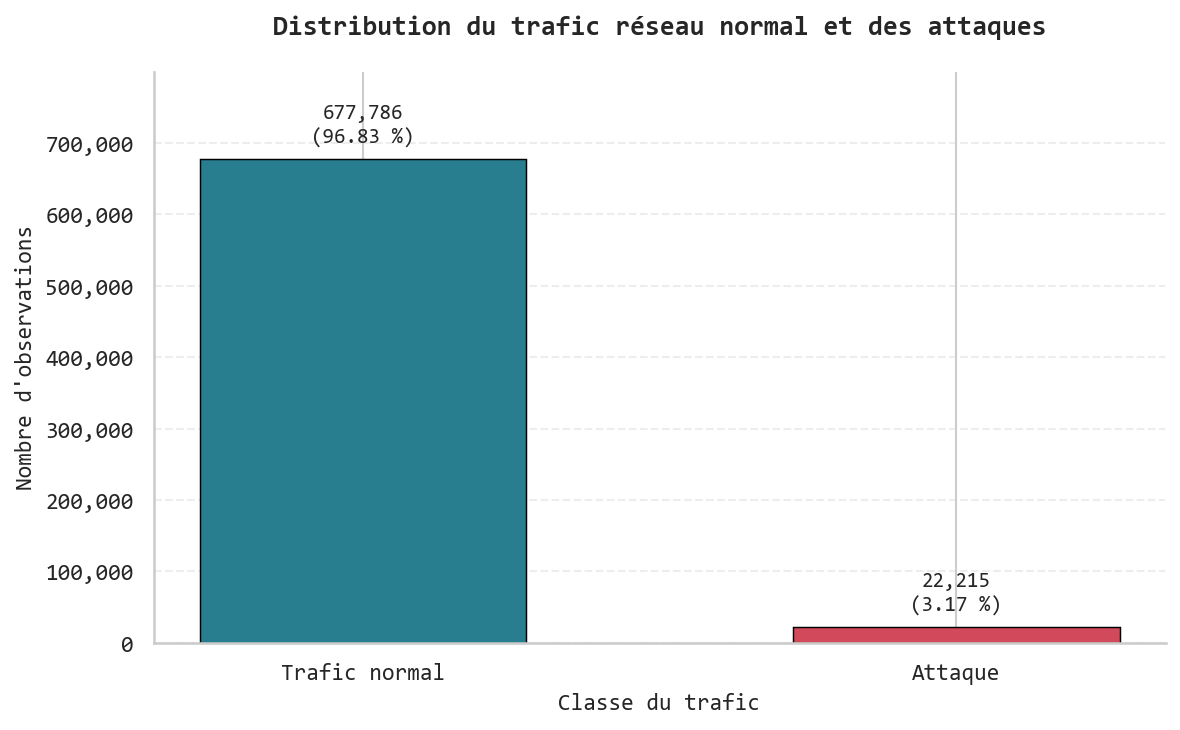

In [10]:
# Modèle : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Objectif : Distribution du trafic normal et des attaques
# ============================================================
# ------------------------------------------------------------
# 1. Vérification de la variable cible
# ------------------------------------------------------------

TARGET = "label"

if TARGET not in df.columns:
    raise ValueError(
        f"La variable cible '{TARGET}' est absente."
    )

# Conversion temporaire sans modifier le dataset original
y_audit = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

# ------------------------------------------------------------
# 2. Contrôle des valeurs manquantes
# ------------------------------------------------------------

missing_labels = int(
    y_audit.isna().sum()
)

if missing_labels > 0:
    raise ValueError(
        f"{missing_labels} étiquettes manquantes "
        "ou non numériques ont été détectées."
    )

# ------------------------------------------------------------
# 3. Vérification des classes
# ------------------------------------------------------------

expected_classes = {0, 1}

detected_classes = set(
    y_audit.unique().tolist()
)

if detected_classes != expected_classes:
    raise ValueError(
        "Classes inattendues ou classe absente. "
        f"Classes détectées : {detected_classes}. "
        "Classes attendues : {0, 1}."
    )

# Convention UNSW-NB15 :
# 0 = trafic normal
# 1 = attaque

CLASS_NAMES = {
    0: "Trafic normal",
    1: "Attaque"
}

# ------------------------------------------------------------
# 4. Effectifs par classe
# ------------------------------------------------------------

class_counts = (
    y_audit.value_counts()
    .reindex([0, 1], fill_value=0)
    .astype("int64")
)

total_observations = int(
    class_counts.sum()
)

normal_count = int(
    class_counts.loc[0]
)

attack_count = int(
    class_counts.loc[1]
)

class_percentages = (
    class_counts / total_observations * 100
)

# ------------------------------------------------------------
# 5. Tableau de distribution
# ------------------------------------------------------------

distribution_table = pd.DataFrame({
    "Classe": ["Trafic normal", "Attaque"],
    "Label": [0, 1],
    "Effectif": [
        normal_count,
        attack_count
    ],
    "Pourcentage": [
        float(class_percentages.loc[0]),
        float(class_percentages.loc[1])
    ]
})

print("\nDISTRIBUTION DES CLASSES")

display(
    distribution_table.style.format({
        "Effectif": "{:,.0f}",
        "Pourcentage": "{:.2f} %"
    })
)

# ------------------------------------------------------------
# 6. Indicateurs descriptifs
# ------------------------------------------------------------

print("\nNombre total d'observations :")
print(f"{total_observations:,}")

print("\nTrafic normal :")
print(
    f"{normal_count:,} observations "
    f"({class_percentages.loc[0]:.2f} %)"
)

print("\nAttaques :")
print(
    f"{attack_count:,} observations "
    f"({class_percentages.loc[1]:.2f} %)"
)

# ------------------------------------------------------------
# 7. Configuration du graphique scientifique
# ------------------------------------------------------------

palette = {
    "Trafic normal": "#287D8EFF",
    "Attaque": "#D1495B"
}

fig, ax = plt.subplots(
    figsize=(8, 5),
    dpi=150
)

bars = ax.bar(
    distribution_table["Classe"],
    distribution_table["Effectif"],
    color=[
        palette["Trafic normal"],
        palette["Attaque"]
    ],
    edgecolor="black",
    linewidth=0.7,
    width=0.55
)

# ------------------------------------------------------------
# 8. Valeurs au-dessus des barres
# ------------------------------------------------------------

max_count = int(
    distribution_table["Effectif"].max()
)

for bar, count, percentage in zip(
    bars,
    distribution_table["Effectif"],
    distribution_table["Pourcentage"]
):

    ax.annotate(
        f"{count:,}\n({percentage:.2f} %)",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontfamily=SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 9. Titres et axes en français
# ------------------------------------------------------------

ax.set_title(
    "Distribution du trafic réseau normal et des attaques",
    fontsize=13,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Classe du trafic",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylim(
    0,
    max_count * 1.18
)

ax.yaxis.set_major_formatter(
    mpl.ticker.StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 10. Sauvegarde de la figure
# ------------------------------------------------------------

figure_path = (
    FIGURES_DIR /
    "distribution_trafic_normal_attaques_DDAE.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 11. Export des résultats
# ------------------------------------------------------------

table_path = (
    TABLES_DIR /
    "distribution_classes_DDAE.csv"
)

distribution_table.to_csv(
    table_path,
    index=False,
    encoding="utf-8-sig"
)

distribution_report = {
    "dataset": DATASET_NAME,
    "total_observations": total_observations,
    "normal_observations": normal_count,
    "attack_observations": attack_count,
    "normal_percentage": float(
        class_percentages.loc[0]
    ),
    "attack_percentage": float(
        class_percentages.loc[1]
    ),
    "label_normal": 0,
    "label_attack": 1,
    "analysis_stage": "audit_before_split",
    "data_modified": False
}

with open(
    ARTIFACTS_DIR /
    "distribution_classes_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        distribution_report,
        file,
        indent=4,
        ensure_ascii=False
    )


Nombre de categories distinctes :
10

DISTRIBUTION DES CATEGORIES


,Categorie,Effectif,Pourcentage
0,Non renseignee,"677,786",96.83 %
1,Generic,"7,522",1.07 %
2,Exploits,"5,409",0.77 %
3,Fuzzers,"5,051",0.72 %
4,Reconnaissance,"1,759",0.25 %
5,DoS,"1,167",0.17 %
6,Backdoors,534,0.08 %
7,Analysis,526,0.08 %
8,Shellcode,223,0.03 %
9,Worms,24,0.00 %



CORRESPONDANCE ENTRE CATEGORIE ET LABEL


,Trafic_normal,Attaque,Total
attack_cat,,,
Analysis,0,526,526
Backdoors,0,534,534
DoS,0,1167,1167
Exploits,0,5409,5409
Fuzzers,0,5051,5051
Generic,0,7522,7522
Non renseignee,677786,0,677786
Reconnaissance,0,1759,1759
Shellcode,0,223,223



CATEGORIES DES OBSERVATIONS ETIQUETEES ATTAQUE


,Nombre d'attaques
attack_cat,
Worms,24
Shellcode,223
Analysis,526
Backdoors,534
DoS,1167
Reconnaissance,1759
Fuzzers,5051
Exploits,5409
Generic,7522


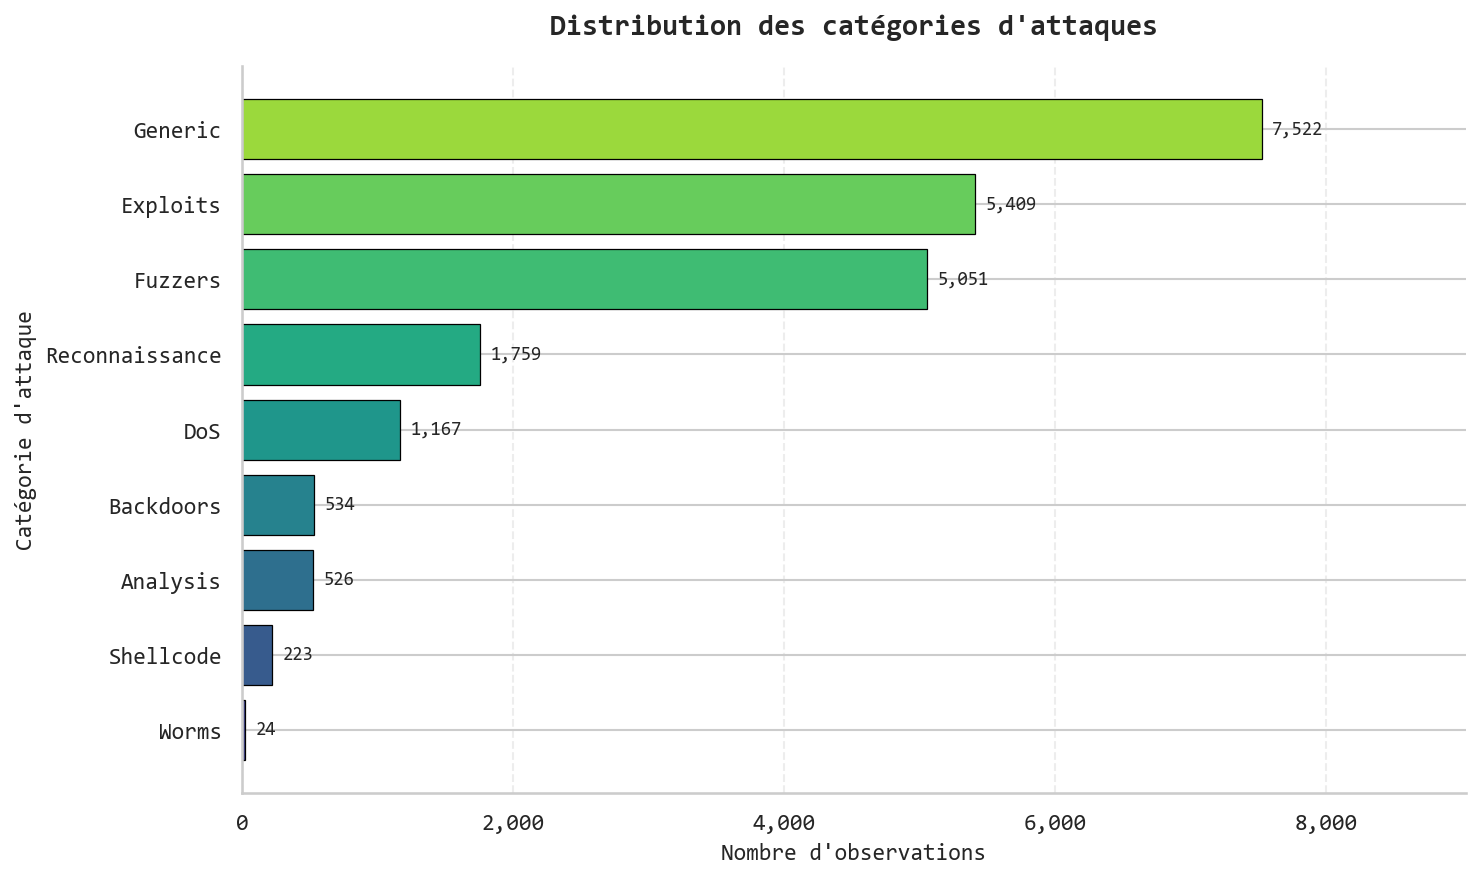

In [12]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Objectif : Audit de attack_cat et coherence avec label
# ============================================================


# ------------------------------------------------------------
# 1. Verification des variables
# ------------------------------------------------------------

TARGET = "label"
ATTACK_COLUMN = "attack_cat"

for column in [TARGET, ATTACK_COLUMN]:
    if column not in df.columns:
        raise ValueError(
            f"Colonne obligatoire absente : {column}"
        )

# ------------------------------------------------------------
# 2. Extraction sans modification du dataset
# ------------------------------------------------------------

y_audit = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

if y_audit.isna().any():
    raise ValueError(
        "La colonne label contient des valeurs invalides."
    )

if not set(y_audit.unique()).issubset({0, 1}):
    raise ValueError(
        "Les labels doivent etre 0 ou 1."
    )

attack_categories = (
    df[ATTACK_COLUMN]
    .astype("string")
    .str.strip()
)

# Representation standardisee pour l'audit uniquement
attack_categories = (
    attack_categories
    .mask(attack_categories.eq(""))
    .fillna("Non renseignee")
)

# ------------------------------------------------------------
# 3. Distribution des categories
# ------------------------------------------------------------

category_counts = (
    attack_categories
    .value_counts(dropna=False)
)

total_observations = len(df)

category_table = (
    category_counts
    .rename_axis("Categorie")
    .reset_index(name="Effectif")
)

category_table["Pourcentage"] = (
    category_table["Effectif"]
    / total_observations
    * 100
)

print("\nNombre de categories distinctes :")
print(len(category_table))

print("\nDISTRIBUTION DES CATEGORIES")

display(
    category_table.style.format({
        "Effectif": "{:,.0f}",
        "Pourcentage": "{:.2f} %"
    })
)

# ------------------------------------------------------------
# 4. Tableau croise categorie / label
# ------------------------------------------------------------

cross_table = pd.crosstab(
    attack_categories,
    y_audit,
    dropna=False
).reindex(
    columns=[0, 1],
    fill_value=0
)

cross_table.columns = [
    "Trafic_normal",
    "Attaque"
]

cross_table["Total"] = (
    cross_table["Trafic_normal"]
    + cross_table["Attaque"]
)

print("\nCORRESPONDANCE ENTRE CATEGORIE ET LABEL")

display(cross_table)

# ------------------------------------------------------------
# 5. Detection des incoherences
# ------------------------------------------------------------

# Les variantes de Normal sont acceptees.
# Une categorie non renseignee est signalee
# et non automatiquement consideree comme normale.

normal_category = (
    attack_categories
    .str.casefold()
    .eq("normal")
    .fillna(False)
)

inconsistent_normal = (
    (y_audit == 0)
    & (~normal_category)
)

inconsistent_attack = (
    (y_audit == 1)
    & normal_category
)

unreported_attack = (
    (y_audit == 1)
    & attack_categories.eq("Non renseignee")
)

n_inconsistent_normal = int(
    inconsistent_normal.sum()
)

n_inconsistent_attack = int(
    inconsistent_attack.sum()
)

n_unreported_attack = int(
    unreported_attack.sum()
)

total_inconsistent = (
    n_inconsistent_normal
    + n_inconsistent_attack
)

# ------------------------------------------------------------
# 6. Distribution des categories d'attaques
# ------------------------------------------------------------

attack_only_categories = (
    attack_categories.loc[y_audit == 1]
    .value_counts()
    .sort_values(ascending=True)
)

print("\nCATEGORIES DES OBSERVATIONS ETIQUETEES ATTAQUE")

display(
    attack_only_categories.rename(
        "Nombre d'attaques"
    ).to_frame()
)

# ------------------------------------------------------------
# 7. Visualisation scientifique
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

colors = plt.cm.viridis(
    np.linspace(
        0.20,
        0.85,
        len(attack_only_categories)
    )
)

bars = ax.barh(
    attack_only_categories.index.astype(str),
    attack_only_categories.values,
    color=colors,
    edgecolor="black",
    linewidth=0.6
)

# ------------------------------------------------------------
# 8. Annotation des barres
# ------------------------------------------------------------

for bar in bars:

    width = bar.get_width()

    ax.annotate(
        f"{int(width):,}",
        xy=(
            width,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontfamily=SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 9. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Distribution des catégories d'attaques",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=15
)

ax.set_xlabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Catégorie d'attaque",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.xaxis.set_major_formatter(
    mpl.ticker.StrMethodFormatter("{x:,.0f}")
)

max_effectif = (
    int(attack_only_categories.max())
    if not attack_only_categories.empty
    else 1
)

ax.set_xlim(
    0,
    max_effectif * 1.20
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 10. Sauvegarde du graphique
# ------------------------------------------------------------

figure_path = (
    FIGURES_DIR /
    "distribution_categories_attaques_DDAE.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 11. Export des tableaux
# ------------------------------------------------------------

category_table.to_csv(
    TABLES_DIR / "categories_attaques_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

cross_table.to_csv(
    TABLES_DIR / "coherence_labels_categories_DDAE.csv",
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Rapport scientifique
# ------------------------------------------------------------

attack_report = {
    "dataset": DATASET_NAME,
    "nombre_observations": int(len(df)),
    "nombre_categories": int(len(category_table)),
    "nombre_attaques": int((y_audit == 1).sum()),
    "normaux_categorie_inattendue": n_inconsistent_normal,
    "attaques_categorie_normal": n_inconsistent_attack,
    "attaques_categorie_non_renseignee": n_unreported_attack,
    "incoherences_binaires": total_inconsistent,
    "analyse": "descriptive_avant_separation",
    "transformations_appliquees": False
}

with open(
    ARTIFACTS_DIR / "audit_categories_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        attack_report,
        file,
        indent=4,
        ensure_ascii=False
    )

In [15]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
# Objectif : Prevention des fuites de cible
# ============================================================

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

TARGET = "label"
ATTACK_COLUMN = "attack_cat"

required_columns = [
    TARGET,
    ATTACK_COLUMN
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes obligatoires absentes : {missing_columns}"
    )

if not df.columns.is_unique:
    raise ValueError(
        "Les noms de colonnes ne sont pas uniques."
    )

# ------------------------------------------------------------
# 2. Definition des variables interdites
# ------------------------------------------------------------

EXCLUDED_COLUMNS = [
    "label",
    "attack_cat"
]

# ------------------------------------------------------------
# 3. Extraction des variables explicatives
# ------------------------------------------------------------

X = df.drop(
    columns=EXCLUDED_COLUMNS,
    errors="raise"
).copy()

# ------------------------------------------------------------
# 4. Extraction de la cible
# ------------------------------------------------------------

y = pd.to_numeric(
    df[TARGET],
    errors="raise"
).astype("int8").copy()

if y.isna().any():
    raise ValueError(
        "La cible contient des valeurs manquantes."
    )

if set(y.unique()) != {0, 1}:
    raise ValueError(
        "Classes attendues : 0 (normal) et 1 (attaque)."
    )

# ------------------------------------------------------------
# 5. Conservation des categories d'attaques
# ------------------------------------------------------------

attack_metadata = (
    df[ATTACK_COLUMN]
    .astype("string")
    .copy()
)



# ------------------------------------------------------------
# 6. Conservation des identifiants de lignes
# ------------------------------------------------------------


observation_ids = np.arange(
    len(df),
    dtype=np.int64
)

if len(observation_ids) != len(X):
    raise ValueError(
        "Incoherence des identifiants d'observations."
    )

# ------------------------------------------------------------
# 7. Controle des variables interdites
# ------------------------------------------------------------

leakage_columns = set(
    X.columns
).intersection(EXCLUDED_COLUMNS)

if leakage_columns:
    raise ValueError(
        f"Fuite directe de cible : {leakage_columns}"
    )

# ------------------------------------------------------------
# 8. Identification des variables a auditer
# ------------------------------------------------------------

sensitive_features = [
    "srcip",
    "dstip",
    "sport",
    "dsport",
    "Stime",
    "Ltime"
]

present_sensitive_features = [
    col for col in sensitive_features
    if col in X.columns
]

print("\nVariables necessitant un audit :")

for feature in present_sensitive_features:
    print(" -", feature)



# ------------------------------------------------------------
# 9. Tableau de tracabilite des caracteristiques
# ------------------------------------------------------------

feature_trace = pd.DataFrame({
    "Variable": df.columns,
    "Type_initial": [
        str(df[col].dtype)
        for col in df.columns
    ],
    "Statut": [
        "Exclue - etiquette"
        if col == TARGET
        else (
            "Exclue - categorie d'attaque"
            if col == ATTACK_COLUMN
            else "Candidate - audit requis"
        )
        for col in df.columns
    ],
    "Justification": [
        "Variable cible reservee a l'evaluation"
        if col == TARGET
        else (
            "Information de classe reservee a l'analyse"
            if col == ATTACK_COLUMN
            else (
                "Variable a examiner avant selection finale"
                if col in sensitive_features
                else "Variable candidate du trafic reseau"
            )
        )
        for col in df.columns
    ]
})

display(feature_trace)

# ------------------------------------------------------------
# 10. Dimensions et distribution
# ------------------------------------------------------------



# ------------------------------------------------------------
# 11. Export du tableau de tracabilite
# ------------------------------------------------------------

trace_path = (
    TABLES_DIR /
    "tracabilite_variables_DDAE.csv"
)

feature_trace.to_csv(
    trace_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Sauvegarde de la configuration
# ------------------------------------------------------------

feature_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "nombre_observations": int(len(X)),
    "nombre_variables_initiales": int(df.shape[1]),
    "nombre_variables_candidates": int(X.shape[1]),
    "variables_exclues": EXCLUDED_COLUMNS,
    "variables_candidates": X.columns.tolist(),
    "variables_a_auditer": present_sensitive_features,
    "encodage_effectue": False,
    "normalisation_effectuee": False,
    "separation_train_test_effectuee": False
}

config_path = (
    ARTIFACTS_DIR /
    "configuration_variables_DDAE.json"
)

with open(
    config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        feature_config,
        file,
        indent=4,
        ensure_ascii=False
    )



Variables necessitant un audit :
 - srcip
 - dstip
 - sport
 - dsport
 - Stime
 - Ltime


,Variable,Type_initial,Statut,Justification
0,srcip,object,Candidate - audit requis,Variable a examiner avant selection finale
1,sport,object,Candidate - audit requis,Variable a examiner avant selection finale
2,dstip,object,Candidate - audit requis,Variable a examiner avant selection finale
3,dsport,object,Candidate - audit requis,Variable a examiner avant selection finale
4,proto,object,Candidate - audit requis,Variable candidate du trafic reseau
5,state,object,Candidate - audit requis,Variable candidate du trafic reseau
6,dur,float64,Candidate - audit requis,Variable candidate du trafic reseau
7,sbytes,int64,Candidate - audit requis,Variable candidate du trafic reseau
8,dbytes,int64,Candidate - audit requis,Variable candidate du trafic reseau
9,sttl,int64,Candidate - audit requis,Variable candidate du trafic reseau


In [29]:
# ============================================================
# CELLULE 8 — DECOUPAGE INDEPENDANT PAR GROUPES
# VERSION CORRIGEE APRES AUDIT DES DOUBLONS
# ============================================================

from sklearn.model_selection import GroupShuffleSplit
from pandas.util import hash_pandas_object

print("=" * 70)
print("CELLULE 8 — DECOUPAGE PAR GROUPES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Parametres experimentaux
# ------------------------------------------------------------

SPLIT_RANDOM_STATE = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO,
    1.0
)

# ------------------------------------------------------------
# 2. Selection des caracteristiques de regroupement
# ------------------------------------------------------------

# Ces exclusions sont identiques a celles
# utilisees pour le DDAE dans la cellule 9.

EXCLUDED_FEATURES = [
    "srcip",
    "dstip",
    "Stime",
    "Ltime"
]

SELECTED_FEATURES = [
    col for col in X.columns
    if col not in EXCLUDED_FEATURES
]

assert len(SELECTED_FEATURES) == 43

# ------------------------------------------------------------
# 3. Construction des signatures
# ------------------------------------------------------------

# Aucun label n'intervient dans les signatures.
# Les valeurs manquantes et les types sont
# conserves tels quels a cette etape.

print("\nCalcul des signatures des observations...")

group_hashes = hash_pandas_object(
    X[SELECTED_FEATURES],
    index=False,
    categorize=True
).to_numpy(dtype=np.uint64)

# Une signature identique implique
# une affectation au meme ensemble.
# Les collisions eventuelles sont regroupees
# de maniere conservative.

group_ids, group_inverse = np.unique(
    group_hashes,
    return_inverse=True
)

print(
    "Nombre de groupes :",
    len(group_ids)
)

print(
    "Nombre d'observations :",
    len(X)
)

# ------------------------------------------------------------
# 4. Premiere separation : train / temporaire
# ------------------------------------------------------------

splitter_1 = GroupShuffleSplit(
    n_splits=1,
    train_size=TRAIN_RATIO,
    random_state=SPLIT_RANDOM_STATE
)

ids_train, ids_temp = next(
    splitter_1.split(
        X,
        y,
        groups=group_inverse
    )
)

# ------------------------------------------------------------
# 5. Deuxieme separation : validation / test
# ------------------------------------------------------------

splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SPLIT_RANDOM_STATE + 1
)

relative_val, relative_test = next(
    splitter_2.split(
        ids_temp,
        y.iloc[ids_temp],
        groups=group_inverse[ids_temp]
    )
)

ids_val = ids_temp[relative_val]
ids_test = ids_temp[relative_test]

# ------------------------------------------------------------
# 6. Construction des ensembles
# ------------------------------------------------------------

X_train_raw = X.iloc[ids_train].copy()
X_val_raw = X.iloc[ids_val].copy()
X_test_raw = X.iloc[ids_test].copy()

y_train_all = y.iloc[ids_train].copy()
y_val_all = y.iloc[ids_val].copy()
y_test = y.iloc[ids_test].copy()

# ------------------------------------------------------------
# 7. Selection one-class
# ------------------------------------------------------------

train_normal_mask = (
    y_train_all.to_numpy() == 0
)

val_normal_mask = (
    y_val_all.to_numpy() == 0
)

X_train_normal_raw = X_train_raw.iloc[
    np.flatnonzero(train_normal_mask)
].copy()

X_val_normal_raw = X_val_raw.iloc[
    np.flatnonzero(val_normal_mask)
].copy()

# ------------------------------------------------------------
# 8. Controle des groupes et des indices
# ------------------------------------------------------------

assert len(np.intersect1d(
    ids_train, ids_val
)) == 0

assert len(np.intersect1d(
    ids_train, ids_test
)) == 0

assert len(np.intersect1d(
    ids_val, ids_test
)) == 0

train_groups = np.unique(
    group_inverse[ids_train]
)

val_groups = np.unique(
    group_inverse[ids_val]
)

test_groups = np.unique(
    group_inverse[ids_test]
)

assert np.intersect1d(
    train_groups, val_groups
).size == 0

assert np.intersect1d(
    train_groups, test_groups
).size == 0

assert np.intersect1d(
    val_groups, test_groups
).size == 0

assert (
    len(ids_train) + len(ids_val) + len(ids_test)
    == len(X)
)

# Les classes indispensables doivent exister.

for name, labels in [
    ("Entrainement", y_train_all),
    ("Validation", y_val_all),
    ("Test", y_test)
]:
    if set(labels.unique()) != {0, 1}:
        raise ValueError(
            f"Classes insuffisantes dans {name}."
        )

# ------------------------------------------------------------
# 9. Tableau des effectifs reels
# ------------------------------------------------------------

split_report = pd.DataFrame({
    "Ensemble": [
        "Entrainement",
        "Validation",
        "Test"
    ],
    "Total": [
        len(ids_train),
        len(ids_val),
        len(ids_test)
    ],
    "Normaux": [
        int((y_train_all == 0).sum()),
        int((y_val_all == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Attaques": [
        int((y_train_all == 1).sum()),
        int((y_val_all == 1).sum()),
        int((y_test == 1).sum())
    ]
})

split_report["Proportion_pct"] = (
    split_report["Total"] / len(X) * 100
)

display(split_report)

# ------------------------------------------------------------
# 10. Sauvegarde du nouveau protocole
# ------------------------------------------------------------

SPLIT_DIR = ARTIFACTS_DIR / "split_commun"

SPLIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

np.save(SPLIT_DIR / "indices_train.npy", ids_train)
np.save(SPLIT_DIR / "indices_validation.npy", ids_val)
np.save(SPLIT_DIR / "indices_test.npy", ids_test)

np.save(
    SPLIT_DIR / "groupes_observations.npy",
    group_inverse
)

split_report.to_csv(
    TABLES_DIR / "repartition_train_validation_test.csv",
    index=False,
    encoding="utf-8-sig"
)

split_config = {
    "methode": "GroupShuffleSplit",
    "random_state": SPLIT_RANDOM_STATE,
    "train_ratio_cible": TRAIN_RATIO,
    "validation_ratio_cible": VAL_RATIO,
    "test_ratio_cible": TEST_RATIO,
    "nombre_groupes": int(len(group_ids)),
    "variables_regroupement": SELECTED_FEATURES,
    "groupes_disjoints": True,
    "pretraitement_ajuste_apres_split": True,
    "effectifs": split_report.to_dict(
        orient="records"
    )
}

with open(
    SPLIT_DIR / "configuration_split.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        split_config,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 11. Bilan
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NOUVEAU DECOUPAGE TERMINE")
print("=" * 70)

print("Entrainement :", len(ids_train))
print("Validation :", len(ids_val))
print("Test :", len(ids_test))

print("\nGroupes disjoints : OUI")
print("Indices disjoints : OUI")

print(
    "\nAttention : les proportions reelles "
    "peuvent differer des proportions cibles."
)

print(
    "Le controle des doublons apres nettoyage "
    "reste a effectuer."
)

print("=" * 70)


CELLULE 8 — DECOUPAGE PAR GROUPES

Calcul des signatures des observations...
Nombre de groupes : 636833
Nombre d'observations : 700001


,Ensemble,Total,Normaux,Attaques,Proportion_pct
0,Entrainement,490140,474263,15877,70.01990
1,Validation,104990,102016,2974,14.99855
2,Test,104871,101507,3364,14.98155



NOUVEAU DECOUPAGE TERMINE
Entrainement : 490140
Validation : 104990
Test : 104871

Groupes disjoints : OUI
Indices disjoints : OUI

Attention : les proportions reelles peuvent differer des proportions cibles.
Le controle des doublons apres nettoyage reste a effectuer.


In [30]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# IMPORTANT :
# Le pretraitement est ajuste exclusivement
# sur les observations normales d'entrainement.
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import joblib
import sklearn

# ------------------------------------------------------------
# 1. Verification des ensembles
# ------------------------------------------------------------

required_objects = [
    "X_train_raw",
    "X_val_raw",
    "X_test_raw",
    "X_train_normal_raw",
    "X_val_normal_raw",
    "ids_train",
    "ids_val",
    "ids_test"
]

for name in required_objects:
    if name not in globals():
        raise RuntimeError(
            f"Objet manquant : {name}. "
            "Executer d'abord la cellule 8."
        )

assert X_train_raw.columns.equals(X.columns)
assert X_val_raw.columns.equals(X.columns)
assert X_test_raw.columns.equals(X.columns)

# ------------------------------------------------------------
# 2. Selection des variables
# ------------------------------------------------------------

# Exclusions justifiees :
# - srcip et dstip : identifiants a forte cardinalite
# - Stime et Ltime : horodatages absolus
#
# Les colonnes label et attack_cat ont deja
# ete exclues dans la cellule 7.

EXCLUDED_FEATURES = [
    "srcip",
    "dstip",
    "Stime",
    "Ltime"
]

missing_exclusions = [
    col for col in EXCLUDED_FEATURES
    if col not in X_train_normal_raw.columns
]

if missing_exclusions:
    raise ValueError(
        "Colonnes attendues absentes : "
        f"{missing_exclusions}"
    )

SELECTED_FEATURES = [
    col for col in X_train_normal_raw.columns
    if col not in EXCLUDED_FEATURES
]

print("\nVariables candidates :", X.shape[1])
print("Variables supplementaires exclues :")
print(EXCLUDED_FEATURES)

print(
    "Variables conservees avant encodage :",
    len(SELECTED_FEATURES)
)

# ------------------------------------------------------------
# 3. Identification des categories
# ------------------------------------------------------------

CATEGORICAL_FEATURES = [
    "proto",
    "state",
    "service"
]

missing_categories = [
    col for col in CATEGORICAL_FEATURES
    if col not in SELECTED_FEATURES
]

if missing_categories:
    raise ValueError(
        "Variables categorielles attendues absentes : "
        f"{missing_categories}"
    )

NUMERIC_FEATURES = [
    col for col in SELECTED_FEATURES
    if col not in CATEGORICAL_FEATURES
]

print("\nVariables categorielles :")
print(CATEGORICAL_FEATURES)

print("\nNombre de variables numeriques :")
print(len(NUMERIC_FEATURES))

# ------------------------------------------------------------
# 4. Fonction de nettoyage reproductible
# ------------------------------------------------------------

def prepare_network_features(data):
    """
    Nettoyage deterministe des caracteristiques.

    Cette fonction n'apprend aucun parametre
    statistique et ne consulte aucune etiquette.

    Les parametres d'imputation et d'echelle
    seront ajustes uniquement sur train normal.
    """

    result = data.loc[
        :,
        SELECTED_FEATURES
    ].copy()

    # Conversion numerique controlee
    for col in NUMERIC_FEATURES:

        values = (
            result[col]
            .astype("string")
            .str.strip()
        )

        values = values.replace(
            ["", "-", "?", "nan", "None"],
            np.nan
        )

        result[col] = pd.to_numeric(
            values,
            errors="coerce"
        )

        result[col] = result[col].replace(
            [np.inf, -np.inf],
            np.nan
        )

    # Traitement des categories
    for col in CATEGORICAL_FEATURES:

        values = (
            result[col]
            .astype("string")
            .str.strip()
        )

        values = values.mask(
            values.isna()
            | values.isin(["", "-", "?", "nan", "None"]),
            other="__MANQUANT__"
        )

        result[col] = values.astype(str)

    return result

# ------------------------------------------------------------
# 5. Nettoyage du TRAIN NORMAL uniquement
# ------------------------------------------------------------

X_train_normal_clean = prepare_network_features(
    X_train_normal_raw
)

print("\nDimensions du train normal :")
print(X_train_normal_clean.shape)

# ------------------------------------------------------------
# 6. Controle de la conversion numerique
# ------------------------------------------------------------

conversion_audit = []

for col in NUMERIC_FEATURES:

    original = X_train_normal_raw[col]

    cleaned = X_train_normal_clean[col]

    conversion_audit.append({
        "Variable": col,
        "Valeurs_manquantes_initiales": int(
            original.isna().sum()
        ),
        "Valeurs_non_numeriques_ou_invalides": int(
            (cleaned.isna() & original.notna()).sum()
        ),
        "Total_a_imputer": int(
            cleaned.isna().sum()
        )
    })

conversion_report = pd.DataFrame(
    conversion_audit
)

print("\nAUDIT DES CONVERSIONS NUMERIQUES")

display(conversion_report)

# ------------------------------------------------------------
# 7. Verification des colonnes totalement manquantes
# ------------------------------------------------------------

all_missing_numeric = [
    col for col in NUMERIC_FEATURES
    if X_train_normal_clean[col].isna().all()
]

if all_missing_numeric:
    raise ValueError(
        "Variables numeriques sans aucune valeur valide : "
        f"{all_missing_numeric}"
    )

# ------------------------------------------------------------
# 8. Construction de l'encodeur categoriel
# ------------------------------------------------------------

# Compatibilite avec les versions de scikit-learn

sklearn_major_minor = tuple(
    int(part)
    for part in sklearn.__version__.split(".")[:2]
)

if sklearn_major_minor >= (1, 2):
    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
        dtype=np.float32
    )
else:
    onehot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True,
        dtype=np.float32
    )

# ------------------------------------------------------------
# 9. Pipeline numerique
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# ------------------------------------------------------------
# 10. Pipeline categoriel
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "encoder",
            onehot_encoder
        )
    ]
)

# ------------------------------------------------------------
# 11. Pretraitement commun
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop",
    sparse_threshold=1.0
)

# ------------------------------------------------------------
# 12. Ajustement sur TRAIN NORMAL uniquement
# ------------------------------------------------------------

print("\nAjustement du pretraitement...")

preprocessor.fit(
    X_train_normal_clean
)

print(
    "Pretraitement ajuste uniquement "
    "sur le trafic normal d'entrainement."
)

# ------------------------------------------------------------
# 13. Nombre final de caracteristiques
# ------------------------------------------------------------

OUTPUT_FEATURE_NAMES = (
    preprocessor.get_feature_names_out()
)

N_INPUT_FEATURES = len(
    OUTPUT_FEATURE_NAMES
)

print("\nNombre de variables avant encodage :")
print(len(SELECTED_FEATURES))

print("\nNombre de caracteristiques apres encodage :")
print(N_INPUT_FEATURES)

# ------------------------------------------------------------
# 14. Tableau de tracabilite final
# ------------------------------------------------------------

feature_trace_final = pd.DataFrame({
    "Variable": X.columns,
    "Statut": [
        "Exclue du modele"
        if col in EXCLUDED_FEATURES
        else (
            "Conservee - categorielle"
            if col in CATEGORICAL_FEATURES
            else "Conservee - numerique"
        )
        for col in X.columns
    ],
    "Justification": [
        (
            "Identifiant reseau a forte cardinalite"
            if col in ["srcip", "dstip"]
            else "Horodatage absolu exclu"
        )
        if col in EXCLUDED_FEATURES
        else (
            "Encodage One-Hot"
            if col in CATEGORICAL_FEATURES
            else "Imputation mediane et standardisation"
        )
        for col in X.columns
    ]
})

display(feature_trace_final)

# ------------------------------------------------------------
# 15. Sauvegarde des tableaux
# ------------------------------------------------------------

feature_trace_final.to_csv(
    TABLES_DIR / "variables_retenues_exclues_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

conversion_report.to_csv(
    TABLES_DIR / "audit_conversions_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({
    "Caracteristique_encodee": OUTPUT_FEATURE_NAMES
}).to_csv(
    TABLES_DIR / "caracteristiques_encodees_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 16. Sauvegarde du pretraitement ajuste
# ------------------------------------------------------------

PREPROCESSOR_PATH = (
    ARTIFACTS_DIR /
    "pretraitement_commun_DDAE_IsolationForest.joblib"
)

joblib.dump(
    {
        "preprocessor": preprocessor,
        "selected_features": SELECTED_FEATURES,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "excluded_features": EXCLUDED_FEATURES,
        "output_features": OUTPUT_FEATURE_NAMES.tolist()
    },
    PREPROCESSOR_PATH
)

# ------------------------------------------------------------
# 17. Configuration de tracabilite
# ------------------------------------------------------------

preprocessing_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "variables_candidates": int(X.shape[1]),
    "variables_exclues_supplementaires": EXCLUDED_FEATURES,
    "variables_avant_encodage": len(SELECTED_FEATURES),
    "variables_apres_encodage": N_INPUT_FEATURES,
    "variables_numeriques": NUMERIC_FEATURES,
    "variables_categorielles": CATEGORICAL_FEATURES,
    "encodage": "OneHotEncoder",
    "categories_inconnues": "ignore",
    "imputation_numerique": "mediane",
    "normalisation": "StandardScaler",
    "ajustement": "train_normal_uniquement",
    "validation_utilisee_pour_fit": False,
    "test_utilise_pour_fit": False,
    "version_sklearn": sklearn.__version__
}

with open(
    ARTIFACTS_DIR / "configuration_pretraitement_DDAE.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        preprocessing_config,
        file,
        indent=4,
        ensure_ascii=False
    )



Variables candidates : 47
Variables supplementaires exclues :
['srcip', 'dstip', 'Stime', 'Ltime']
Variables conservees avant encodage : 43

Variables categorielles :
['proto', 'state', 'service']

Nombre de variables numeriques :
40

Dimensions du train normal :
(474263, 43)

AUDIT DES CONVERSIONS NUMERIQUES


,Variable,Valeurs_manquantes_initiales,Valeurs_non_numeriques_ou_invalides,Total_a_imputer
0,sport,0,5,5
1,dsport,0,42,42
2,dur,0,0,0
3,sbytes,0,0,0
4,dbytes,0,0,0
5,sttl,0,0,0
6,dttl,0,0,0
7,sloss,0,0,0
8,dloss,0,0,0
9,Sload,0,0,0



Ajustement du pretraitement...
Pretraitement ajuste uniquement sur le trafic normal d'entrainement.

Nombre de variables avant encodage :
43

Nombre de caracteristiques apres encodage :
70


,Variable,Statut,Justification
0,srcip,Exclue du modele,Identifiant reseau a forte cardinalite
1,sport,Conservee - numerique,Imputation mediane et standardisation
2,dstip,Exclue du modele,Identifiant reseau a forte cardinalite
3,dsport,Conservee - numerique,Imputation mediane et standardisation
4,proto,Conservee - categorielle,Encodage One-Hot
5,state,Conservee - categorielle,Encodage One-Hot
6,dur,Conservee - numerique,Imputation mediane et standardisation
7,sbytes,Conservee - numerique,Imputation mediane et standardisation
8,dbytes,Conservee - numerique,Imputation mediane et standardisation
9,sttl,Conservee - numerique,Imputation mediane et standardisation


In [31]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# IMPORTANT :
# preprocessor a ete ajuste en cellule 9
# uniquement sur le trafic normal d'entrainement.
#
# Ici : transform() uniquement.
# Aucun fit() ni fit_transform().
# ============================================================

from scipy import sparse


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

required_objects = [
    "preprocessor",
    "prepare_network_features",
    "X_train_normal_raw",
    "X_val_normal_raw",
    "X_test_raw",
    "y_test",
    "ids_train",
    "ids_val",
    "ids_test",
    "N_INPUT_FEATURES"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Objets manquants : "
        f"{missing_objects}. "
        "Executer les cellules precedentes."
    )

# ------------------------------------------------------------
# 2. Nettoyage deterministe des ensembles
# ------------------------------------------------------------

# La fonction applique exclusivement
# les regles definies en cellule 9.
# Elle ne calcule aucun parametre statistique.

X_val_normal_clean = prepare_network_features(
    X_val_normal_raw
)

X_test_clean = prepare_network_features(
    X_test_raw
)

print("\nNettoyage deterministe termine.")

# ------------------------------------------------------------
# 3. Transformation avec le pretraitement ajuste
# ------------------------------------------------------------

# ATTENTION :
# Utiliser exclusivement transform().
#
# Les parametres du StandardScaler,
# les medianes et les categories One-Hot
# restent ceux appris sur train normal.

X_train_encoded = preprocessor.transform(
    X_train_normal_clean
)

X_val_encoded = preprocessor.transform(
    X_val_normal_clean
)

X_test_encoded = preprocessor.transform(
    X_test_clean
)

print("\nTransformation realisee sans nouvel ajustement.")

# ------------------------------------------------------------
# 4. Conversion en format sparse CSR
# ------------------------------------------------------------

# Le format sparse limite l'utilisation
# de la memoire pendant les transformations.
#
# La conversion dense pour TensorFlow
# sera traitee selon la memoire disponible.

def to_csr_float32(matrix):

    if sparse.issparse(matrix):

        result = matrix.tocsr().astype(
            np.float32
        )

    else:

        result = sparse.csr_matrix(
            np.asarray(
                matrix,
                dtype=np.float32
            )
        )

    return result


X_train_encoded = to_csr_float32(
    X_train_encoded
)

X_val_encoded = to_csr_float32(
    X_val_encoded
)

X_test_encoded = to_csr_float32(
    X_test_encoded
)

# ------------------------------------------------------------
# 5. Verification des dimensions
# ------------------------------------------------------------

expected_features = N_INPUT_FEATURES

for name, matrix in [
    ("Train normal", X_train_encoded),
    ("Validation normale", X_val_encoded),
    ("Test independant", X_test_encoded)
]:

    if matrix.shape[1] != expected_features:
        raise ValueError(
            f"Dimensions incompatibles pour {name} : "
            f"{matrix.shape[1]} au lieu de "
            f"{expected_features}."
        )

print("\nDIMENSIONS DES MATRICES")

print("Train normal :", X_train_encoded.shape)
print("Validation normale :", X_val_encoded.shape)
print("Test independant :", X_test_encoded.shape)

# ------------------------------------------------------------
# 6. Verification NaN / Inf
# ------------------------------------------------------------

def verify_matrix(matrix, name):

    # Dans CSR, les zeros implicites sont finis.
    # On controle les valeurs effectivement stockees.

    stored_values = matrix.data

    if not np.isfinite(stored_values).all():

        raise ValueError(
            f"Valeurs NaN ou infinies dans {name}."
        )

    print(
        f"{name} : aucune valeur NaN/Inf."
    )


verify_matrix(
    X_train_encoded,
    "Train normal"
)

verify_matrix(
    X_val_encoded,
    "Validation normale"
)

verify_matrix(
    X_test_encoded,
    "Test independant"
)

# ------------------------------------------------------------
# 7. Verification des effectifs
# ------------------------------------------------------------

assert (
    X_train_encoded.shape[0]
    == len(X_train_normal_raw)
)

assert (
    X_val_encoded.shape[0]
    == len(X_val_normal_raw)
)

assert (
    X_test_encoded.shape[0]
    == len(y_test)
)

# ------------------------------------------------------------
# 8. Conservation des identifiants exacts
# ------------------------------------------------------------

ids_train_normal = ids_train[
    y_train_all.to_numpy() == 0
]

ids_val_normal = ids_val[
    y_val_all.to_numpy() == 0
]

assert (
    len(ids_train_normal)
    == X_train_encoded.shape[0]
)

assert (
    len(ids_val_normal)
    == X_val_encoded.shape[0]
)

assert (
    len(ids_test)
    == X_test_encoded.shape[0]
)

assert np.array_equal(
    y.iloc[ids_test].to_numpy(),
    y_test.to_numpy()
)

# ------------------------------------------------------------
# 9. Sauvegarde des matrices
# ------------------------------------------------------------

MATRICES_DIR = (
    ARTIFACTS_DIR / "matrices_communes"
)

MATRICES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

sparse.save_npz(
    MATRICES_DIR / "X_train_normal.npz",
    X_train_encoded
)

sparse.save_npz(
    MATRICES_DIR / "X_validation_normal.npz",
    X_val_encoded
)

sparse.save_npz(
    MATRICES_DIR / "X_test_independant.npz",
    X_test_encoded
)

np.save(
    MATRICES_DIR / "y_test.npy",
    y_test.to_numpy(dtype=np.int8)
)

np.save(
    MATRICES_DIR / "ids_train_normal.npy",
    ids_train_normal
)

np.save(
    MATRICES_DIR / "ids_validation_normal.npy",
    ids_val_normal
)

np.save(
    MATRICES_DIR / "ids_test.npy",
    ids_test
)

# ------------------------------------------------------------
# 10. Rapport des ensembles transformes
# ------------------------------------------------------------

transformation_report = pd.DataFrame({
    "Ensemble": [
        "Train normal",
        "Validation normale",
        "Test independant"
    ],
    "Observations": [
        X_train_encoded.shape[0],
        X_val_encoded.shape[0],
        X_test_encoded.shape[0]
    ],
    "Caracteristiques": [
        X_train_encoded.shape[1],
        X_val_encoded.shape[1],
        X_test_encoded.shape[1]
    ],
    "Format": [
        "CSR float32",
        "CSR float32",
        "CSR float32"
    ],
    "Utilisation": [
        "Entrainement one-class",
        "Calibration du seuil",
        "Evaluation finale"
    ]
})

display(transformation_report)

transformation_report.to_csv(
    TABLES_DIR / "dimensions_matrices_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. Rapport de tracabilite
# ------------------------------------------------------------

transformation_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "pretraitement": "commun_DDAE_IsolationForest",
    "ajustement_pretraitement": "train_normal_uniquement",
    "methode_application": "transform",
    "nombre_caracteristiques": int(
        N_INPUT_FEATURES
    ),
    "train_normal": int(
        X_train_encoded.shape[0]
    ),
    "validation_normale": int(
        X_val_encoded.shape[0]
    ),
    "test_independant": int(
        X_test_encoded.shape[0]
    ),
    "nombre_normaux_test": int(
        (y_test == 0).sum()
    ),
    "nombre_attaques_test": int(
        (y_test == 1).sum()
    ),
    "format_matrices": "scipy_sparse_CSR_float32",
    "normalisation_refaite_sur_test": False,
    "encodage_refait_sur_test": False,
    "test_utilise_pour_entrainement": False,
    "test_utilise_pour_calibration": False
}

with open(
    ARTIFACTS_DIR /
    "configuration_transformation_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        transformation_config,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 12. Verification finale — VERSION CORRIGEE
# ------------------------------------------------------------

# Verification du nombre de caracteristiques

assert (
    X_train_encoded.shape[1]
    == X_val_encoded.shape[1]
    == X_test_encoded.shape[1]
), "Les matrices ne possedent pas le meme nombre de caracteristiques."

# Verification des identifiants independants

assert set(ids_train_normal).isdisjoint(
    set(ids_test)
), "Chevauchement entre entrainement et test."

assert set(ids_val_normal).isdisjoint(
    set(ids_test)
), "Chevauchement entre validation et test."

assert set(ids_train_normal).isdisjoint(
    set(ids_val_normal)
), "Chevauchement entre entrainement et validation."

# Verification de la dimension attendue

assert (
    X_train_encoded.shape[1] == N_INPUT_FEATURES
), "Nombre de caracteristiques inattendu."

# Verification des effectifs

assert (
    X_train_encoded.shape[0]
    == len(ids_train_normal)
)

assert (
    X_val_encoded.shape[0]
    == len(ids_val_normal)
)

assert (
    X_test_encoded.shape[0]
    == len(ids_test)
)


Nettoyage deterministe termine.

Transformation realisee sans nouvel ajustement.

DIMENSIONS DES MATRICES
Train normal : (474263, 70)
Validation normale : (102016, 70)
Test independant : (104871, 70)
Train normal : aucune valeur NaN/Inf.
Validation normale : aucune valeur NaN/Inf.
Test independant : aucune valeur NaN/Inf.


,Ensemble,Observations,Caracteristiques,Format,Utilisation
0,Train normal,474263,70,CSR float32,Entrainement one-class
1,Validation normale,102016,70,CSR float32,Calibration du seuil
2,Test independant,104871,70,CSR float32,Evaluation finale


In [28]:

# ============================================================
# DIAGNOSTIC — CHEVAUCHEMENT ENTRE LES ENSEMBLES
# ============================================================

print("=" * 70)
print("DIAGNOSTIC DES DOUBLONS INTER-PARTITIONS")
print("=" * 70)

diagnostic_columns = [
    "Representation",
    "Ensemble_A",
    "Ensemble_B",
    "Signatures_communes",
    "Observations_A_concernees",
    "Observations_B_concernees",
    "Pourcentage_A",
    "Pourcentage_B"
]

display(
    audit_duplicates[
        diagnostic_columns
    ].style.format({
        "Pourcentage_A": "{:.4f} %",
        "Pourcentage_B": "{:.4f} %"
    })
)

print("\nSIGNATURES COMMUNES SUR LES VARIABLES RETENUES")

print(
    "Train / Validation :",
    len(train_val_overlap)
)

print(
    "Train / Test :",
    len(train_test_overlap)
)

print(
    "Validation / Test :",
    len(val_test_overlap)
)

print("\nAudit valide :", DUPLICATE_AUDIT_PASSED)

print("=" * 70)


DIAGNOSTIC DES DOUBLONS INTER-PARTITIONS


,Representation,Ensemble_A,Ensemble_B,Signatures_communes,Observations_A_concernees,Observations_B_concernees,Pourcentage_A,Pourcentage_B
0,Variables brutes,Train,Validation,10058,20256,11849,4.1339 %,11.2848 %
1,Variables brutes,Train,Test,10143,20324,11983,4.1478 %,11.4123 %
2,Variables brutes,Validation,Test,3462,4358,4367,4.1505 %,4.1590 %
3,Variables retenues,Train,Validation,9536,24279,12095,4.9549 %,11.5190 %
4,Variables retenues,Train,Test,9697,24405,12248,4.9806 %,11.6647 %
5,Variables retenues,Validation,Test,3568,5215,5172,4.9667 %,4.9257 %



SIGNATURES COMMUNES SUR LES VARIABLES RETENUES
Train / Validation : 9536
Train / Test : 9697
Validation / Test : 3568

Audit valide : False


In [33]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Objectif : Detecter les doublons inter-partitions
#
# Aucune donnee n'est supprimee ou modifiee.
# ============================================================

import hashlib
from pandas.util import hash_pandas_object



# ------------------------------------------------------------
# 1. Verification des objets necessaires
# ------------------------------------------------------------

required_objects = [
    "X_train_raw",
    "X_val_raw",
    "X_test_raw",
    "ids_train",
    "ids_val",
    "ids_test",
    "SELECTED_FEATURES",
    "X_train_encoded",
    "X_val_encoded",
    "X_test_encoded"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Objets manquants : "
        f"{missing_objects}"
    )

# ------------------------------------------------------------
# 2. Controle des identifiants
# ------------------------------------------------------------

train_ids = np.asarray(ids_train, dtype=np.int64)
val_ids = np.asarray(ids_val, dtype=np.int64)
test_ids = np.asarray(ids_test, dtype=np.int64)

assert len(np.unique(train_ids)) == len(train_ids)
assert len(np.unique(val_ids)) == len(val_ids)
assert len(np.unique(test_ids)) == len(test_ids)

assert len(np.intersect1d(train_ids, val_ids)) == 0
assert len(np.intersect1d(train_ids, test_ids)) == 0
assert len(np.intersect1d(val_ids, test_ids)) == 0

assert len(train_ids) == len(X_train_raw)
assert len(val_ids) == len(X_val_raw)
assert len(test_ids) == len(X_test_raw)

print("\nControle des identifiants : VALIDE")
print("Train :", len(train_ids))
print("Validation :", len(val_ids))
print("Test :", len(test_ids))

# ------------------------------------------------------------
# 3. Fonction de calcul des empreintes de lignes
# ------------------------------------------------------------

# Les empreintes sont calculees sans utiliser
# l'indice pandas ni les etiquettes.
#
# Le hachage permet de detecter efficacement
# les lignes identiques, meme sur un grand dataset.
#
# Une collision de hachage reste theoriquement
# possible : le resultat est un audit de signatures.

def calculate_row_hashes(data, feature_columns):

    subset = data.loc[:, feature_columns]

    hashes = hash_pandas_object(
        subset,
        index=False,
        categorize=True
    )

    return hashes.to_numpy(dtype=np.uint64)

# ------------------------------------------------------------
# 4. Empreintes des variables brutes
# ------------------------------------------------------------

print("\nCalcul des empreintes brutes...")

raw_columns = X.columns.tolist()

hash_train_raw = calculate_row_hashes(
    X_train_raw,
    raw_columns
)

hash_val_raw = calculate_row_hashes(
    X_val_raw,
    raw_columns
)

hash_test_raw = calculate_row_hashes(
    X_test_raw,
    raw_columns
)

# ------------------------------------------------------------
# 5. Empreintes des variables selectionnees
# ------------------------------------------------------------

# Cette analyse exclut :
# srcip, dstip, Stime et Ltime.
#
# Ces quatre colonnes ne sont pas utilisees
# par le DDAE apres la cellule 9.

print("\nCalcul des empreintes des variables retenues...")

hash_train_selected = calculate_row_hashes(
    X_train_raw,
    SELECTED_FEATURES
)

hash_val_selected = calculate_row_hashes(
    X_val_raw,
    SELECTED_FEATURES
)

hash_test_selected = calculate_row_hashes(
    X_test_raw,
    SELECTED_FEATURES
)

# ------------------------------------------------------------
# 6. Fonction de comparaison entre ensembles
# ------------------------------------------------------------

def compare_partitions(
    hashes_a,
    hashes_b,
    ids_a,
    ids_b,
    name_a,
    name_b,
    representation
):
    """
    Compte les observations dont la signature
    est presente dans l'autre partition.

    Ce nombre n'est pas un nombre de paires.
    """

    common = np.intersect1d(
        np.unique(hashes_a),
        np.unique(hashes_b)
    )

    mask_a = np.isin(hashes_a, common)
    mask_b = np.isin(hashes_b, common)

    count_a = int(mask_a.sum())
    count_b = int(mask_b.sum())

    example_ids_a = (
        ids_a[mask_a][:10].tolist()
    )

    example_ids_b = (
        ids_b[mask_b][:10].tolist()
    )

    return {
        "Representation": representation,
        "Ensemble_A": name_a,
        "Ensemble_B": name_b,
        "Signatures_communes": int(len(common)),
        "Observations_A_concernees": count_a,
        "Observations_B_concernees": count_b,
        "Pourcentage_A": (
            100 * count_a / len(ids_a)
            if len(ids_a) else 0
        ),
        "Pourcentage_B": (
            100 * count_b / len(ids_b)
            if len(ids_b) else 0
        ),
        "Exemples_ID_A": str(example_ids_a),
        "Exemples_ID_B": str(example_ids_b)
    }

# ------------------------------------------------------------
# 7. Comparaison des trois partitions
# ------------------------------------------------------------

results = []

for representation, hashes in [
    (
        "Variables brutes",
        (
            hash_train_raw,
            hash_val_raw,
            hash_test_raw
        )
    ),
    (
        "Variables retenues",
        (
            hash_train_selected,
            hash_val_selected,
            hash_test_selected
        )
    )
]:

    h_train, h_val, h_test = hashes

    results.append(
        compare_partitions(
            h_train, h_val,
            train_ids, val_ids,
            "Train", "Validation",
            representation
        )
    )

    results.append(
        compare_partitions(
            h_train, h_test,
            train_ids, test_ids,
            "Train", "Test",
            representation
        )
    )

    results.append(
        compare_partitions(
            h_val, h_test,
            val_ids, test_ids,
            "Validation", "Test",
            representation
        )
    )

audit_duplicates = pd.DataFrame(results)

# ------------------------------------------------------------
# 8. Affichage du bilan
# ------------------------------------------------------------

summary_columns = [
    "Representation",
    "Ensemble_A",
    "Ensemble_B",
    "Signatures_communes",
    "Observations_A_concernees",
    "Observations_B_concernees",
    "Pourcentage_A",
    "Pourcentage_B"
]

print("\nRESULTATS DE L'AUDIT INTER-PARTITIONS")

display(
    audit_duplicates[summary_columns].style.format({
        "Pourcentage_A": "{:.4f} %",
        "Pourcentage_B": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 9. Doublons au sein de chaque partition
# ------------------------------------------------------------

within_results = []

for name, hashes in [
    ("Train", hash_train_selected),
    ("Validation", hash_val_selected),
    ("Test", hash_test_selected)
]:

    number_duplicates = int(
        pd.Series(hashes).duplicated().sum()
    )

    within_results.append({
        "Ensemble": name,
        "Observations": len(hashes),
        "Signatures_repetees": number_duplicates,
        "Pourcentage": (
            number_duplicates / len(hashes) * 100
            if len(hashes) else 0
        )
    })

within_report = pd.DataFrame(within_results)

print("\nDOUBLONS INTERNES AUX PARTITIONS")

display(within_report)

# ------------------------------------------------------------
# 10. Controle du chevauchement avec le test
# ------------------------------------------------------------

# Le chevauchement sur les variables retenues
# est prioritaire car il concerne directement
# les donnees exploitees par le modele.

train_test_overlap = np.intersect1d(
    np.unique(hash_train_selected),
    np.unique(hash_test_selected)
)

val_test_overlap = np.intersect1d(
    np.unique(hash_val_selected),
    np.unique(hash_test_selected)
)

train_val_overlap = np.intersect1d(
    np.unique(hash_train_selected),
    np.unique(hash_val_selected)
)

DUPLICATE_AUDIT_PASSED = (
    len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
    and len(train_val_overlap) == 0
)

if DUPLICATE_AUDIT_PASSED:

    print("\nAucune signature commune detectee")
    print("entre les trois partitions sur les")
    print("variables retenues.")

else:

    print("\nATTENTION : CHEVAUCHEMENTS DETECTES")

    print(
        "Train / Test :",
        len(train_test_overlap)
    )

    print(
        "Validation / Test :",
        len(val_test_overlap)
    )

    print(
        "Train / Validation :",
        len(train_val_overlap)
    )

    print(
        "\nLe decoupage doit etre reexamine "
        "avant l'entrainement definitif."
    )

# ------------------------------------------------------------
# 11. Audit des dependances reseau
# ------------------------------------------------------------

# L'existence de caracteristiques temporelles
# ou d'identifiants reseau suggere un risque
# de dependance entre observations.
#
# Leur presence seule ne prouve pas une fuite.

network_columns = [
    "srcip",
    "dstip",
    "sport",
    "dsport",
    "proto",
    "Stime",
    "Ltime"
]

available_network_columns = [
    col for col in network_columns
    if col in X.columns
]

network_dependency_report = {
    "variables_identifiees": available_network_columns,
    "risque_de_sessions_apparentees": (
        "Non exclu par le decoupage aleatoire"
    ),
    "independance_temporelle_prouvee": False,
    "independance_par_flux_prouvee": False
}

print("\nAUDIT DES DEPENDANCES RESEAU")

print(
    "Variables disponibles :",
    available_network_columns
)

print(
    "Independance par flux : "
    "non demontree a cette etape."
)

# ------------------------------------------------------------
# 12. Export des rapports
# ------------------------------------------------------------

audit_duplicates.to_csv(
    TABLES_DIR / "audit_doublons_inter_partitions.csv",
    index=False,
    encoding="utf-8-sig"
)

within_report.to_csv(
    TABLES_DIR / "audit_doublons_intra_partitions.csv",
    index=False,
    encoding="utf-8-sig"
)

audit_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "controle_identifiants": "valide",
    "methode": "hachage_pandas_64_bits",
    "colonnes_brutes": raw_columns,
    "colonnes_retenues": SELECTED_FEATURES,
    "audit_signatures_sans_chevauchement": bool(
        DUPLICATE_AUDIT_PASSED
    ),
    "signatures_communes_train_test": int(
        len(train_test_overlap)
    ),
    "signatures_communes_validation_test": int(
        len(val_test_overlap)
    ),
    "signatures_communes_train_validation": int(
        len(train_val_overlap)
    ),
    "independance_flux_demontree": False,
    "independance_temporelle_demontree": False,
    "donnees_modifiees": False,
    "audit_reseau": network_dependency_report
}

with open(
    ARTIFACTS_DIR / "audit_independance_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        audit_config,
        file,
        indent=4,
        ensure_ascii=False
    )



Controle des identifiants : VALIDE
Train : 490140
Validation : 104990
Test : 104871

Calcul des empreintes brutes...

Calcul des empreintes des variables retenues...

RESULTATS DE L'AUDIT INTER-PARTITIONS


,Representation,Ensemble_A,Ensemble_B,Signatures_communes,Observations_A_concernees,Observations_B_concernees,Pourcentage_A,Pourcentage_B
0,Variables brutes,Train,Validation,0,0,0,0.0000 %,0.0000 %
1,Variables brutes,Train,Test,0,0,0,0.0000 %,0.0000 %
2,Variables brutes,Validation,Test,0,0,0,0.0000 %,0.0000 %
3,Variables retenues,Train,Validation,0,0,0,0.0000 %,0.0000 %
4,Variables retenues,Train,Test,0,0,0,0.0000 %,0.0000 %
5,Variables retenues,Validation,Test,0,0,0,0.0000 %,0.0000 %



DOUBLONS INTERNES AUX PARTITIONS


,Ensemble,Observations,Signatures_repetees,Pourcentage
0,Train,490140,44357,9.049863
1,Validation,104990,9465,9.015144
2,Test,104871,9346,8.911901



Aucune signature commune detectee
entre les trois partitions sur les
variables retenues.

AUDIT DES DEPENDANCES RESEAU
Variables disponibles : ['srcip', 'dstip', 'sport', 'dsport', 'proto', 'Stime', 'Ltime']
Independance par flux : non demontree a cette etape.


In [35]:
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Verifier les conditions indispensables avant
# l'entrainement definitif du modele.
#
# Aucun entrainement ni calibration du seuil.
# ============================================================

from pandas.util import hash_pandas_object
from scipy import sparse

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

required_objects = [
    "X",
    "y",
    "ids_train",
    "ids_val",
    "ids_test",
    "X_train_normal_raw",
    "X_val_normal_raw",
    "X_test_raw",
    "X_train_encoded",
    "X_val_encoded",
    "X_test_encoded",
    "y_test",
    "preprocessor",
    "SELECTED_FEATURES",
    "N_INPUT_FEATURES",
    "DUPLICATE_AUDIT_PASSED"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Objets manquants : "
        f"{missing}. "
        "Verifier les cellules 8 a 11."
    )

if not DUPLICATE_AUDIT_PASSED:
    raise RuntimeError(
        "L'audit de la cellule 11 n'est pas valide. "
        "Ne pas poursuivre l'entrainement."
    )

print("\nPreconditions : OK")

# ------------------------------------------------------------
# 2. Verification des identifiants
# ------------------------------------------------------------

ids_train = np.asarray(
    ids_train,
    dtype=np.int64
)

ids_val = np.asarray(
    ids_val,
    dtype=np.int64
)

ids_test = np.asarray(
    ids_test,
    dtype=np.int64
)

all_ids = np.concatenate([
    ids_train,
    ids_val,
    ids_test
])

assert len(all_ids) == len(X)

assert len(np.unique(all_ids)) == len(X)

assert np.array_equal(
    np.sort(all_ids),
    np.arange(len(X))
)

print("Indices disjoints et exhaustifs : OK")

# ------------------------------------------------------------
# 3. Verification des groupes
# ------------------------------------------------------------

if "group_inverse" not in globals():
    raise RuntimeError(
        "Groupes absents. Executer la nouvelle cellule 8."
    )

train_groups = np.unique(
    group_inverse[ids_train]
)

val_groups = np.unique(
    group_inverse[ids_val]
)

test_groups = np.unique(
    group_inverse[ids_test]
)

assert np.intersect1d(
    train_groups, val_groups
).size == 0

assert np.intersect1d(
    train_groups, test_groups
).size == 0

assert np.intersect1d(
    val_groups, test_groups
).size == 0

print("Groupes disjoints : OK")

# ------------------------------------------------------------
# 4. Verification des variables interdites
# ------------------------------------------------------------

FORBIDDEN_FEATURES = [
    "label",
    "attack_cat"
]

assert not set(
    FORBIDDEN_FEATURES
).intersection(SELECTED_FEATURES)

assert X_train_encoded.shape[1] == N_INPUT_FEATURES

assert (
    X_train_encoded.shape[1]
    == X_val_encoded.shape[1]
    == X_test_encoded.shape[1]
)

print("Variables cibles exclues : OK")
print("Dimensions des matrices : OK")

# ------------------------------------------------------------
# 5. Verification du principe one-class
# ------------------------------------------------------------

assert (
    y_train_all.loc[
        X_train_normal_raw.index
    ] == 0
).all()

assert (
    y_val_all.loc[
        X_val_normal_raw.index
    ] == 0
).all()

assert (
    X_train_encoded.shape[0]
    == len(X_train_normal_raw)
)

assert (
    X_val_encoded.shape[0]
    == len(X_val_normal_raw)
)

assert X_test_encoded.shape[0] == len(y_test)

print("Entrainement reserve aux normales : OK")
print("Validation normale disponible : OK")

# ------------------------------------------------------------
# 6. Controle des valeurs non finies
# ------------------------------------------------------------

def check_finite(matrix, name):

    if sparse.issparse(matrix):
        values = matrix.data
    else:
        values = np.asarray(matrix)

    if not np.isfinite(values).all():
        raise ValueError(
            f"NaN ou infini detecte dans : {name}"
        )

for name, matrix in [
    ("Train", X_train_encoded),
    ("Validation", X_val_encoded),
    ("Test", X_test_encoded)
]:
    check_finite(matrix, name)

print("Valeurs numeriques finies : OK")

# ------------------------------------------------------------
# 7. Controle apres nettoyage deterministe
# ------------------------------------------------------------

# Les memes caracteristiques selectionnees
# doivent etre comparees apres les conversions
# definies dans la cellule 9.
#
# Cette verification ne modifie aucun ensemble.

def cleaned_signatures(data):

    clean = prepare_network_features(data)

    return hash_pandas_object(
        clean[SELECTED_FEATURES],
        index=False,
        categorize=True
    ).to_numpy(dtype=np.uint64)

print("\nVerification des signatures apres nettoyage...")

clean_train_hashes = cleaned_signatures(
    X_train_raw
)

clean_val_hashes = cleaned_signatures(
    X_val_raw
)

clean_test_hashes = cleaned_signatures(
    X_test_raw
)

clean_overlaps = {
    "train_validation": int(
        np.intersect1d(
            clean_train_hashes,
            clean_val_hashes
        ).size
    ),
    "train_test": int(
        np.intersect1d(
            clean_train_hashes,
            clean_test_hashes
        ).size
    ),
    "validation_test": int(
        np.intersect1d(
            clean_val_hashes,
            clean_test_hashes
        ).size
    )
}

print("\nSignatures communes apres nettoyage :")

for name, count in clean_overlaps.items():
    print(f" - {name} : {count}")

CLEAN_AUDIT_PASSED = all(
    count == 0
    for count in clean_overlaps.values()
)

if not CLEAN_AUDIT_PASSED:
    raise RuntimeError(
        "Chevauchement de signatures apres nettoyage. "
        "Ne pas entrainer le modele. "
        "Examiner les valeurs concernées avant "
        "toute modification du decoupage."
    )

print("Audit apres nettoyage : OK")

# ------------------------------------------------------------
# 8. Verification des identifiants sauvegardes
# ------------------------------------------------------------

saved_train = np.load(
    SPLIT_DIR / "indices_train.npy"
)

saved_val = np.load(
    SPLIT_DIR / "indices_validation.npy"
)

saved_test = np.load(
    SPLIT_DIR / "indices_test.npy"
)

assert np.array_equal(
    saved_train, ids_train
)

assert np.array_equal(
    saved_val, ids_val
)

assert np.array_equal(
    saved_test, ids_test
)

print("Indices sauvegardes conformes : OK")

# ------------------------------------------------------------
# 9. Synthese des effectifs
# ------------------------------------------------------------

protocol_table = pd.DataFrame({
    "Ensemble": [
        "Entrainement",
        "Validation",
        "Test"
    ],
    "Observations": [
        len(ids_train),
        len(ids_val),
        len(ids_test)
    ],
    "Normaux": [
        int((y_train_all == 0).sum()),
        int((y_val_all == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Attaques": [
        int((y_train_all == 1).sum()),
        int((y_val_all == 1).sum()),
        int((y_test == 1).sum())
    ]
})

print("\nREPARTITION EXPERIMENTALE DEFINITIVE")

display(protocol_table)

protocol_table.to_csv(
    TABLES_DIR / "protocole_experimental_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. Rapport de validation
# ------------------------------------------------------------

PROTOCOL_VALIDATED = True

protocol_report = {
    "modele": MODEL_NAME,
    "dataset": DATASET_NAME,
    "protocole": "one-class",
    "decoupage": "GroupShuffleSplit",
    "total_observations": int(len(X)),
    "caracteristiques_finales": int(
        N_INPUT_FEATURES
    ),
    "indices_disjoints": True,
    "groupes_disjoints": True,
    "signatures_nettoyees_disjointes": True,
    "train_normal_uniquement": True,
    "validation_normale_pour_calibration": True,
    "calibration_percentile": 95,
    "test_reserve": True,
    "independance_sessions_demontree": False,
    "pretraitement_fit_train_normal": (
        "Configuration des cellules 9-10 ; "
        "a verifier par revue du code"
    ),
    "audit_apres_nettoyage": clean_overlaps,
    "controle_structurel_valide": PROTOCOL_VALIDATED
}

REPORT_PATH = (
    ARTIFACTS_DIR /
    "validation_protocole_DDAE.json"
)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        protocol_report,
        file,
        indent=4,
        ensure_ascii=False
    )


Preconditions : OK
Indices disjoints et exhaustifs : OK
Groupes disjoints : OK
Variables cibles exclues : OK
Dimensions des matrices : OK
Entrainement reserve aux normales : OK
Validation normale disponible : OK
Valeurs numeriques finies : OK

Verification des signatures apres nettoyage...

Signatures communes apres nettoyage :
 - train_validation : 0
 - train_test : 0
 - validation_test : 0
Audit apres nettoyage : OK
Indices sauvegardes conformes : OK

REPARTITION EXPERIMENTALE DEFINITIVE


,Ensemble,Observations,Normaux,Attaques
0,Entrainement,490140,474263,15877
1,Validation,104990,102016,2974
2,Test,104871,101507,3364


In [37]:
# Modele : Deep Dense Autoencoder
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Preparer l'entrainement TensorFlow sans utiliser
# le jeu de test et sans conversion dense globale.
# ============================================================

import gc
import math
from scipy import sparse


# ------------------------------------------------------------
# 1. Validation du protocole
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Protocole non valide. "
        "Executer et valider la cellule 12."
    )

if not globals().get("CLEAN_AUDIT_PASSED", False):
    raise RuntimeError(
        "L'audit des doublons apres nettoyage "
        "n'a pas ete valide."
    )

# ------------------------------------------------------------
# 2. Configuration experimentale
# ------------------------------------------------------------

BATCH_SIZE = 256

EPOCHS = 50

LEARNING_RATE = 0.001

INPUT_DIM = int(N_INPUT_FEATURES)

print("\nCONFIGURATION")

print("Nombre de caracteristiques :", INPUT_DIM)
print("Taille des lots :", BATCH_SIZE)
print("Epoques maximales :", EPOCHS)
print("Taux d'apprentissage :", LEARNING_RATE)

# ------------------------------------------------------------
# 3. Verification des matrices
# ------------------------------------------------------------

training_matrices = {
    "Entrainement normal": X_train_encoded,
    "Validation normale": X_val_encoded
}

for name, matrix in training_matrices.items():

    if matrix.shape[1] != INPUT_DIM:
        raise ValueError(
            f"Dimension incorrecte : {name}"
        )

    if matrix.shape[0] == 0:
        raise ValueError(
            f"Matrice vide : {name}"
        )

    values = (
        matrix.data
        if sparse.issparse(matrix)
        else np.asarray(matrix)
    )

    if not np.isfinite(values).all():
        raise ValueError(
            f"Valeurs non finies : {name}"
        )

print("\nMatrices d'entrainement verifiees.")

# ------------------------------------------------------------
# 4. Conversion en CSR float32
# ------------------------------------------------------------

# Pas de conversion dense de tout le dataset.
# Seuls les lots seront convertis en tableaux NumPy.

def ensure_csr_float32(matrix):

    if sparse.issparse(matrix):
        return matrix.tocsr().astype(
            np.float32,
            copy=False
        )

    return sparse.csr_matrix(
        np.asarray(matrix, dtype=np.float32)
    )


X_train_csr = ensure_csr_float32(
    X_train_encoded
)

X_val_csr = ensure_csr_float32(
    X_val_encoded
)

# ------------------------------------------------------------
# 5. Generateur Keras par lots
# ------------------------------------------------------------

class AutoencoderSequence(tf.keras.utils.Sequence):

    def __init__(
        self,
        matrix,
        batch_size=256,
        shuffle=False,
        seed=42
    ):

        self.matrix = matrix
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)

        self.rng = np.random.default_rng(seed)

        self.indices = np.arange(
            matrix.shape[0],
            dtype=np.int64
        )

        self.on_epoch_end()

    def __len__(self):

        return math.ceil(
            len(self.indices) / self.batch_size
        )

    def __getitem__(self, index):

        start = index * self.batch_size
        end = min(
            (index + 1) * self.batch_size,
            len(self.indices)
        )

        batch_indices = self.indices[start:end]

        batch = self.matrix[
            batch_indices
        ].toarray().astype(
            np.float32,
            copy=False
        )

        # Autoencodeur : entree = sortie cible
        return batch, batch

    def on_epoch_end(self):

        if self.shuffle:
            self.rng.shuffle(self.indices)

# ------------------------------------------------------------
# 6. Preparation du train normal
# ------------------------------------------------------------

train_generator = AutoencoderSequence(
    matrix=X_train_csr,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=RANDOM_STATE
)

# ------------------------------------------------------------
# 7. Preparation de la validation normale
# ------------------------------------------------------------

validation_generator = AutoencoderSequence(
    matrix=X_val_csr,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=RANDOM_STATE
)

# ------------------------------------------------------------
# 8. Verification des premiers lots
# ------------------------------------------------------------

train_batch_x, train_batch_y = (
    train_generator[0]
)

val_batch_x, val_batch_y = (
    validation_generator[0]
)

assert train_batch_x.shape[1] == INPUT_DIM
assert val_batch_x.shape[1] == INPUT_DIM

assert np.array_equal(
    train_batch_x,
    train_batch_y
)

assert np.array_equal(
    val_batch_x,
    val_batch_y
)

assert np.isfinite(train_batch_x).all()
assert np.isfinite(val_batch_x).all()

print("\nPREMIERS LOTS")

print(
    "Entrainement :",
    train_batch_x.shape
)

print(
    "Validation :",
    val_batch_x.shape
)

# ------------------------------------------------------------
# 9. Verification du principe one-class
# ------------------------------------------------------------

assert (
    y_train_all.loc[
        X_train_normal_raw.index
    ] == 0
).all()

assert (
    y_val_all.loc[
        X_val_normal_raw.index
    ] == 0
).all()

print("\nOne-class : confirme.")
print("Aucune attaque dans les generateurs.")

# ------------------------------------------------------------
# 10. Nombre de lots
# ------------------------------------------------------------

TRAIN_STEPS = len(train_generator)

VALIDATION_STEPS = len(validation_generator)

print("\nNombre de lots d'entrainement :")
print(TRAIN_STEPS)

print("\nNombre de lots de validation :")
print(VALIDATION_STEPS)

# ------------------------------------------------------------
# 11. Estimation de la memoire d'un lot
# ------------------------------------------------------------

batch_memory_mb = (
    BATCH_SIZE
    * INPUT_DIM
    * np.dtype(np.float32).itemsize
    / (1024 ** 2)
)

print("\nMemoire theorique d'un lot :")
print(f"{batch_memory_mb:.3f} Mo")

# ------------------------------------------------------------
# 12. Sauvegarde de la configuration
# ------------------------------------------------------------

training_config = {
    "dataset": DATASET_NAME,
    "model": MODEL_NAME,
    "protocol": "one-class",
    "input_features": INPUT_DIM,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "MSE",
    "training_observations": int(
        X_train_csr.shape[0]
    ),
    "validation_observations": int(
        X_val_csr.shape[0]
    ),
    "training_steps": TRAIN_STEPS,
    "validation_steps": VALIDATION_STEPS,
    "training_labels": "normal_only",
    "validation_labels": "normal_only",
    "test_used_for_training": False,
    "test_used_for_validation": False,
    "data_format": "CSR_float32",
    "batch_conversion": "dense_float32"
}

with open(
    ARTIFACTS_DIR / "configuration_entrainement_DDAE.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_config,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 13. Nettoyage des variables temporaires
# ------------------------------------------------------------

del train_batch_x, train_batch_y
del val_batch_x, val_batch_y

gc.collect()


CONFIGURATION
Nombre de caracteristiques : 70
Taille des lots : 256
Epoques maximales : 50
Taux d'apprentissage : 0.001

Matrices d'entrainement verifiees.

PREMIERS LOTS
Entrainement : (256, 70)
Validation : (256, 70)

One-class : confirme.
Aucune attaque dans les generateurs.

Nombre de lots d'entrainement :
1853

Nombre de lots de validation :
399

Memoire theorique d'un lot :
0.068 Mo


41

In [39]:
# ============================================================
# CELLULE 14 — ARCHITECTURE DU DEEP DENSE AUTOENCODER
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Architecture :
# Input(n) -> Dense(32) -> Dense(16)
#          -> Dense(32) -> Dense(n)
#
# Cette cellule construit et compile le modele.
# Aucun entrainement n'est effectue ici.
# ============================================================

# ------------------------------------------------------------
# 1. Verification du protocole
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole experimental n'est pas valide. "
        "Executer correctement la cellule 12."
    )

if not globals().get("CLEAN_AUDIT_PASSED", False):
    raise RuntimeError(
        "L'audit d'independance apres nettoyage "
        "n'est pas valide."
    )

required_objects = [
    "INPUT_DIM",
    "LEARNING_RATE",
    "train_generator",
    "validation_generator"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}. "
        "Executer la cellule 13."
    )

# ------------------------------------------------------------
# 2. Configuration de l'architecture
# ------------------------------------------------------------

INPUT_DIM = int(INPUT_DIM)

ENCODER_UNITS = 32
LATENT_DIM = 16
DECODER_UNITS = 32

if INPUT_DIM <= 32:
    raise ValueError(
        "L'architecture 32-16-32 ne constitue pas "
        "une compression initiale pour cette entree. "
        "Verifier les caracteristiques."
    )

print("\nCONFIGURATION DE L'ARCHITECTURE")

print("Entree :", INPUT_DIM)
print("Encodeur :", ENCODER_UNITS)
print("Espace latent :", LATENT_DIM)
print("Decodeur :", DECODER_UNITS)
print("Sortie :", INPUT_DIM)

# ------------------------------------------------------------
# 3. Definition de la couche d'entree
# ------------------------------------------------------------

input_layer = Input(
    shape=(INPUT_DIM,),
    dtype="float32",
    name="entree_trafic_reseau"
)

# ------------------------------------------------------------
# 4. Encodeur
# ------------------------------------------------------------

encoded = Dense(
    units=ENCODER_UNITS,
    activation="relu",
    name="encodeur_dense_32"
)(input_layer)

# ------------------------------------------------------------
# 5. Representation latente
# ------------------------------------------------------------

latent = Dense(
    units=LATENT_DIM,
    activation="relu",
    name="representation_latente_16"
)(encoded)

# ------------------------------------------------------------
# 6. Decodeur
# ------------------------------------------------------------

decoded = Dense(
    units=DECODER_UNITS,
    activation="relu",
    name="decodeur_dense_32"
)(latent)

# ------------------------------------------------------------
# 7. Couche de reconstruction
# ------------------------------------------------------------

output_layer = Dense(
    units=INPUT_DIM,
    activation="linear",
    name="reconstruction_trafic"
)(decoded)

# ------------------------------------------------------------
# 8. Construction du modele complet
# ------------------------------------------------------------

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer,
    name="Deep_Dense_Autoencoder"
)

# ------------------------------------------------------------
# 9. Modele encodeur pour analyse latente
# ------------------------------------------------------------

encoder = Model(
    inputs=input_layer,
    outputs=latent,
    name="DDAE_Encodeur"
)

# ------------------------------------------------------------
# 10. Compilation
# ------------------------------------------------------------

optimizer = Adam(
    learning_rate=LEARNING_RATE
)

autoencoder.compile(
    optimizer=optimizer,
    loss="mse"
)

# ------------------------------------------------------------
# 11. Resume de l'architecture
# ------------------------------------------------------------

print("\nARCHITECTURE DU MODELE")

autoencoder.summary()

# ------------------------------------------------------------
# 12. Verification des dimensions
# ------------------------------------------------------------

assert autoencoder.input_shape == (
    None,
    INPUT_DIM
)

assert autoencoder.output_shape == (
    None,
    INPUT_DIM
)

assert encoder.output_shape == (
    None,
    LATENT_DIM
)

# ------------------------------------------------------------
# 13. Verification du nombre de parametres
# ------------------------------------------------------------

TOTAL_PARAMETERS = int(
    autoencoder.count_params()
)

EXPECTED_PARAMETERS = (
    (INPUT_DIM + 1) * ENCODER_UNITS
    + (ENCODER_UNITS + 1) * LATENT_DIM
    + (LATENT_DIM + 1) * DECODER_UNITS
    + (DECODER_UNITS + 1) * INPUT_DIM
)

assert (
    TOTAL_PARAMETERS == EXPECTED_PARAMETERS
)

print("\nPARAMETRES DU MODELE")

print(
    "Nombre total de parametres :",
    f"{TOTAL_PARAMETERS:,}"
)

print(
    "Nombre de neurones latents :",
    LATENT_DIM
)

# ------------------------------------------------------------
# 14. Sauvegarde de la configuration
# ------------------------------------------------------------

architecture_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "architecture": [
        INPUT_DIM,
        ENCODER_UNITS,
        LATENT_DIM,
        DECODER_UNITS,
        INPUT_DIM
    ],
    "activation_encodeur": "relu",
    "activation_latente": "relu",
    "activation_decodeur": "relu",
    "activation_sortie": "linear",
    "optimiseur": "Adam",
    "learning_rate": float(LEARNING_RATE),
    "loss": "MSE",
    "nombre_parametres": TOTAL_PARAMETERS,
    "entraine": False
}

architecture_path = (
    ARTIFACTS_DIR /
    "architecture_DDAE.json"
)

with open(
    architecture_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        architecture_config,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. Sauvegarde du resume textuel
# ------------------------------------------------------------

summary_path = (
    ARTIFACTS_DIR /
    "resume_architecture_DDAE.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    autoencoder.summary(
        print_fn=lambda line: file.write(
            line + "\n"
        )
    )


CONFIGURATION DE L'ARCHITECTURE
Entree : 70
Encodeur : 32
Espace latent : 16
Decodeur : 32
Sortie : 70

ARCHITECTURE DU MODELE
Model: "Deep_Dense_Autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 entree_trafic_reseau (Inpu  [(None, 70)]              0         
 tLayer)                                                         
                                                                 
 encodeur_dense_32 (Dense)   (None, 32)                2272      
                                                                 
 representation_latente_16   (None, 16)                528       
 (Dense)                                                         
                                                                 
 decodeur_dense_32 (Dense)   (None, 32)                544       
                                                                 
 reconstruction_trafic (Den  (None, 70)         

In [40]:

# ============================================================
# CELLULE 15 — ENTRAINEMENT DU DEEP DENSE AUTOENCODER
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Entrainement : trafic normal uniquement
# Validation : trafic normal uniquement
# Test independant : strictement reserve
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    TerminateOnNaN
)

# ------------------------------------------------------------
# 1. Verification du protocole experimental
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole experimental n'est pas valide. "
        "Verifier la cellule 12."
    )

if not globals().get("CLEAN_AUDIT_PASSED", False):
    raise RuntimeError(
        "L'audit d'independance n'est pas valide."
    )

required_objects = [
    "autoencoder",
    "train_generator",
    "validation_generator",
    "X_train_csr",
    "X_val_csr",
    "EPOCHS",
    "BATCH_SIZE",
    "INPUT_DIM"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Verification des donnees one-class
# ------------------------------------------------------------

assert (
    y_train_all.loc[
        X_train_normal_raw.index
    ] == 0
).all(), "Attaques detectees dans l'entrainement."

assert (
    y_val_all.loc[
        X_val_normal_raw.index
    ] == 0
).all(), "Attaques detectees dans la validation."

assert X_train_csr.shape[1] == INPUT_DIM
assert X_val_csr.shape[1] == INPUT_DIM

assert len(train_generator) > 0
assert len(validation_generator) > 0

print("\nVerification one-class : OK")

print(
    "Observations normales d'entrainement :",
    X_train_csr.shape[0]
)

print(
    "Observations normales de validation :",
    X_val_csr.shape[0]
)

# ------------------------------------------------------------
# 3. Configuration de l'entrainement
# ------------------------------------------------------------

MAX_EPOCHS = int(EPOCHS)

EARLY_STOPPING_PATIENCE = 8

MIN_DELTA = 1e-4

print("\nPARAMETRES D'ENTRAINEMENT")

print("Epoques maximales :", MAX_EPOCHS)
print("Batch size :", BATCH_SIZE)
print("Patience :", EARLY_STOPPING_PATIENCE)
print("Delta minimum :", MIN_DELTA)

# ------------------------------------------------------------
# 4. Preparation des fichiers de sauvegarde
# ------------------------------------------------------------

TRAINING_DIR = RESULTS_DIR / "entrainement"

TRAINING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    MODELS_DIR / "DDAE_meilleur_modele.keras"
)

FINAL_MODEL_PATH = (
    MODELS_DIR / "DDAE_modele_final.keras"
)

HISTORY_PATH = (
    TABLES_DIR / "historique_entrainement_DDAE.csv"
)

# ------------------------------------------------------------
# 5. Arret anticipe
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    min_delta=MIN_DELTA,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------------------------
# 6. Sauvegarde du meilleur modele
# ------------------------------------------------------------

model_checkpoint = ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

# ------------------------------------------------------------
# 7. Interruption si perte invalide
# ------------------------------------------------------------

terminate_on_nan = TerminateOnNaN()

callbacks = [
    early_stopping,
    model_checkpoint,
    terminate_on_nan
]

# ------------------------------------------------------------
# 8. Entrainement du modele
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DEMARRAGE DE L'ENTRAINEMENT")
print("=" * 70)

start_time = time.perf_counter()

history = autoencoder.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

training_duration = (
    time.perf_counter() - start_time
)

print("\nEntrainement termine.")

# ------------------------------------------------------------
# 9. Extraction de l'historique
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "Epoque",
    np.arange(
        1,
        len(history_df) + 1
    )
)

if "loss" not in history_df.columns:
    raise RuntimeError(
        "Historique de perte d'entrainement absent."
    )

if "val_loss" not in history_df.columns:
    raise RuntimeError(
        "Historique de validation absent."
    )

if not np.isfinite(
    history_df[["loss", "val_loss"]].to_numpy()
).all():
    raise RuntimeError(
        "Des pertes non finies ont ete detectees."
    )

# ------------------------------------------------------------
# 10. Identification de la meilleure epoque
# ------------------------------------------------------------

best_epoch_index = int(
    history_df["val_loss"].idxmin()
)

BEST_EPOCH = int(
    history_df.loc[
        best_epoch_index,
        "Epoque"
    ]
)

BEST_VAL_LOSS = float(
    history_df.loc[
        best_epoch_index,
        "val_loss"
    ]
)

BEST_TRAIN_LOSS = float(
    history_df.loc[
        best_epoch_index,
        "loss"
    ]
)

ACTUAL_EPOCHS = len(history_df)

print("\nRESULTATS DE L'ENTRAINEMENT")

print("Epoques executees :", ACTUAL_EPOCHS)
print("Meilleure epoque :", BEST_EPOCH)

print(
    "Perte entrainement a la meilleure epoque :",
    f"{BEST_TRAIN_LOSS:.6f}"
)

print(
    "Meilleure perte validation :",
    f"{BEST_VAL_LOSS:.6f}"
)

print(
    "Duree de l'entrainement :",
    f"{training_duration / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 11. Chargement du meilleur modele sauvegarde
# ------------------------------------------------------------

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Le meilleur modele n'a pas ete sauvegarde."
    )

# Le checkpoint correspondant a la meilleure
# val_loss constitue notre modele final retenu.

autoencoder = tf.keras.models.load_model(
    str(BEST_MODEL_PATH)
)

# Reconstruire la vue encodeur a partir
# du meilleur modele sauvegarde.

encoder = tf.keras.Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer(
        "representation_latente_16"
    ).output,
    name="DDAE_Encodeur"
)

# ------------------------------------------------------------
# 12. Sauvegarde du modele final retenu
# ------------------------------------------------------------

autoencoder.save(
    str(FINAL_MODEL_PATH)
)

print("\nModele retenu sauvegarde :")
print(FINAL_MODEL_PATH)

# ------------------------------------------------------------
# 13. Sauvegarde de l'historique
# ------------------------------------------------------------

history_df.to_csv(
    HISTORY_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Rapport experimental
# ------------------------------------------------------------

training_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "architecture": [
        INPUT_DIM,
        32,
        16,
        32,
        INPUT_DIM
    ],
    "optimiseur": "Adam",
    "learning_rate": float(LEARNING_RATE),
    "loss": "MSE",
    "batch_size": int(BATCH_SIZE),
    "epochs_max": MAX_EPOCHS,
    "epochs_executed": ACTUAL_EPOCHS,
    "best_epoch": BEST_EPOCH,
    "best_training_loss": BEST_TRAIN_LOSS,
    "best_validation_loss": BEST_VAL_LOSS,
    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),
    "early_stopping_min_delta": MIN_DELTA,
    "training_duration_seconds": float(
        training_duration
    ),
    "train_normal_observations": int(
        X_train_csr.shape[0]
    ),
    "validation_normal_observations": int(
        X_val_csr.shape[0]
    ),
    "test_used_for_training": False,
    "test_used_for_model_selection": False,
    "test_used_for_threshold": False,
    "checkpoint_path": str(
        BEST_MODEL_PATH
    )
}

REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_entrainement_DDAE.json"
)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. Verification finale
# ------------------------------------------------------------

assert (
    autoencoder.input_shape[-1]
    == INPUT_DIM
)

assert (
    autoencoder.output_shape[-1]
    == INPUT_DIM
)

assert np.isfinite(BEST_VAL_LOSS)

TRAINING_COMPLETED = True

print("\n" + "=" * 70)
print("CELLULE 15 — ENTRAINEMENT TERMINE")
print("=" * 70)

print("Modele :", MODEL_NAME)

print(
    "Architecture :",
    f"{INPUT_DIM} -> 32 -> 16 -> 32 -> {INPUT_DIM}"
)

print("Epoques executees :", ACTUAL_EPOCHS)
print("Meilleure epoque :", BEST_EPOCH)

print(
    "Meilleure perte de validation :",
    f"{BEST_VAL_LOSS:.6f}"
)

print(
    "Duree :",
    f"{training_duration / 60:.2f} minutes"
)

print("\nMeilleur modele :", BEST_MODEL_PATH)
print("Modele final :", FINAL_MODEL_PATH)
print("Historique :", HISTORY_PATH)
print("Rapport :", REPORT_PATH)

print("\nTest independant utilise : NON")

print("=" * 70)
print("CELLULE 15 EXECUTEE AVEC SUCCES")
print("=" * 70)



Verification one-class : OK
Observations normales d'entrainement : 474263
Observations normales de validation : 102016

PARAMETRES D'ENTRAINEMENT
Epoques maximales : 50
Batch size : 256
Patience : 8
Delta minimum : 0.0001

DEMARRAGE DE L'ENTRAINEMENT
Epoch 1/50

1839/1853 [============================>.] - ETA: 0s - loss: 0.1411
Epoch 1: val_loss improved from inf to 0.05725, saving model to C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\modeles\DDAE_meilleur_modele.keras
1853/1853 [==============================] - 9s 4ms/step - loss: 0.1405 - val_loss: 0.0573
Epoch 2/50
1844/1853 [============================>.] - ETA: 0s - loss: 0.0628
Epoch 2: val_loss improved from 0.05725 to 0.04003, saving model to C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\modeles\DDAE_meilleur_modele.keras
1853/1853 [==============================] - 8s 4ms/step - loss: 0.0627 - val_loss: 0.0400
Epoch 3/50
1849/1853 [============================>.] - ETA: 0s -


RESULTATS
Epoques executees : 50
Meilleure epoque : 45
Perte entrainement a la meilleure epoque : 0.014281
Meilleure perte de validation : 0.011150


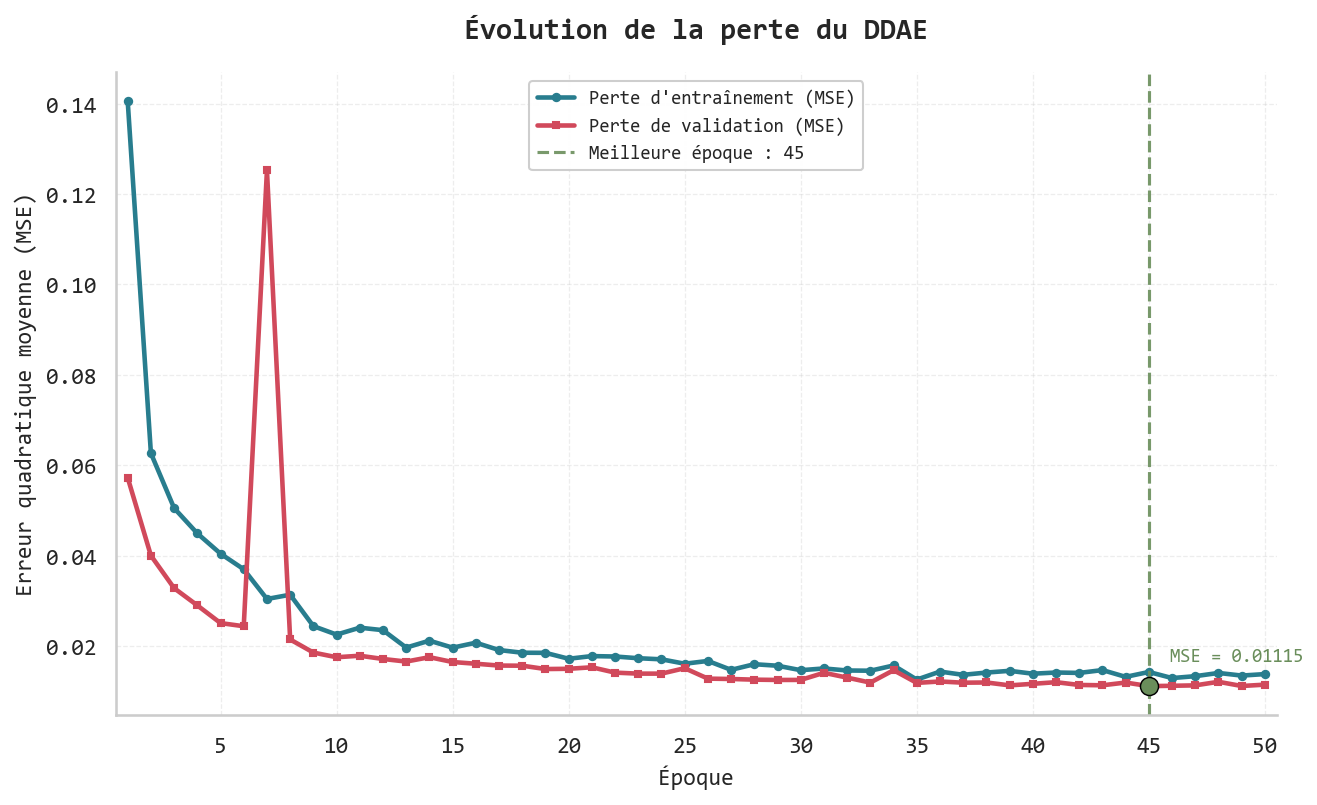

,Epoque,Perte_entrainement_MSE,Perte_validation_MSE,Ecart_validation_entrainement
40,41,0.014160,0.012022,-0.002138
41,42,0.014073,0.011407,-0.002666
42,43,0.014699,0.011334,-0.003365
43,44,0.013195,0.011941,-0.001255
44,45,0.014281,0.011150,-0.003132
45,46,0.012934,0.011225,-0.001709
46,47,0.013351,0.011318,-0.002033
47,48,0.014063,0.012106,-0.001957
48,49,0.013482,0.011179,-0.002303
49,50,0.013812,0.011476,-0.002337



EVOLUTION DES PERTES
Perte entrainement initiale : 0.140543
Perte entrainement finale : 0.013812
Perte validation initiale : 0.057253
Meilleure perte validation : 0.011150
Perte validation derniere epoque : 0.011476
Ecart a la meilleure epoque : -0.003132


In [42]:
# ============================================================
# CELLULE 16 — EVOLUTION DES PERTES DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Visualiser l'evolution des pertes MSE
# d'entrainement et de validation.
#
# Aucune utilisation du test independant.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import json


# ------------------------------------------------------------
# 1. Verification de l'entrainement
# ------------------------------------------------------------

if not globals().get("TRAINING_COMPLETED", False):
    raise RuntimeError(
        "L'entrainement n'est pas termine. "
        "Executer correctement la cellule 15."
    )

if "history_df" not in globals():
    raise RuntimeError(
        "Historique absent. Verifier la cellule 15."
    )

required_columns = [
    "Epoque",
    "loss",
    "val_loss"
]

missing_columns = [
    col for col in required_columns
    if col not in history_df.columns
]

if missing_columns:
    raise ValueError(
        f"Colonnes manquantes : {missing_columns}"
    )

# ------------------------------------------------------------
# 2. Extraction des pertes reelles
# ------------------------------------------------------------

epochs_values = history_df[
    "Epoque"
].to_numpy(dtype=int)

train_loss = history_df[
    "loss"
].to_numpy(dtype=float)

val_loss = history_df[
    "val_loss"
].to_numpy(dtype=float)

if len(epochs_values) == 0:
    raise ValueError(
        "L'historique d'entrainement est vide."
    )

if not (
    np.isfinite(train_loss).all()
    and np.isfinite(val_loss).all()
):
    raise ValueError(
        "Des pertes non finies ont ete detectees."
    )

# ------------------------------------------------------------
# 3. Identification de la meilleure epoque
# ------------------------------------------------------------

best_index = int(
    np.argmin(val_loss)
)

best_epoch = int(
    epochs_values[best_index]
)

best_validation_loss = float(
    val_loss[best_index]
)

best_training_loss = float(
    train_loss[best_index]
)

print("\nRESULTATS")

print("Epoques executees :", len(epochs_values))
print("Meilleure epoque :", best_epoch)

print(
    "Perte entrainement a la meilleure epoque :",
    f"{best_training_loss:.6f}"
)

print(
    "Meilleure perte de validation :",
    f"{best_validation_loss:.6f}"
)

# ------------------------------------------------------------
# 4. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False
})

# Palette sobre et scientifique

COLOR_TRAIN = "#287D8E"
COLOR_VALIDATION = "#D1495B"
COLOR_BEST = "#6A8E5B"

# ------------------------------------------------------------
# 5. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5),
    dpi=150
)

# Courbe d'entrainement

ax.plot(
    epochs_values,
    train_loss,
    color=COLOR_TRAIN,
    linewidth=2.2,
    marker="o",
    markersize=3.5,
    label="Perte d'entraînement (MSE)"
)

# Courbe de validation

ax.plot(
    epochs_values,
    val_loss,
    color=COLOR_VALIDATION,
    linewidth=2.2,
    marker="s",
    markersize=3.2,
    label="Perte de validation (MSE)"
)

# ------------------------------------------------------------
# 6. Identification de la meilleure epoque
# ------------------------------------------------------------

ax.axvline(
    x=best_epoch,
    color=COLOR_BEST,
    linestyle="--",
    linewidth=1.5,
    alpha=0.9,
    label=f"Meilleure époque : {best_epoch}"
)

ax.scatter(
    [best_epoch],
    [best_validation_loss],
    color=COLOR_BEST,
    s=75,
    edgecolor="black",
    linewidth=0.7,
    zorder=5
)

ax.annotate(
    f"MSE = {best_validation_loss:.5f}",
    xy=(best_epoch, best_validation_loss),
    xytext=(10, 12),
    textcoords="offset points",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT,
    color=COLOR_BEST
)

# ------------------------------------------------------------
# 7. Titres et axes
# ------------------------------------------------------------

ax.set_title(
    "Évolution de la perte du DDAE",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax.set_xlabel(
    "Époque",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Erreur quadratique moyenne (MSE)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

# ------------------------------------------------------------
# 8. Configuration des axes
# ------------------------------------------------------------

ax.set_xlim(
    max(0.5, epochs_values.min() - 0.5),
    epochs_values.max() + 0.5
)

ax.xaxis.set_major_locator(
    mpl.ticker.MaxNLocator(
        nbins=10,
        integer=True
    )
)

ax.yaxis.set_major_formatter(
    mpl.ticker.ScalarFormatter(
        useOffset=False
    )
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 9. Legende
# ------------------------------------------------------------

ax.legend(
    loc="best",
    fontsize=9,
    frameon=True,
    fancybox=True,
    framealpha=0.95
)

plt.tight_layout()

# ------------------------------------------------------------
# 10. Sauvegarde haute resolution
# ------------------------------------------------------------

FIGURE_NAME = "evolution_pertes_DDAE"

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 11. Tableau des pertes
# ------------------------------------------------------------

loss_table = pd.DataFrame({
    "Epoque": epochs_values,
    "Perte_entrainement_MSE": train_loss,
    "Perte_validation_MSE": val_loss,
    "Ecart_validation_entrainement": (
        val_loss - train_loss
    )
})

display(loss_table.tail(10))

loss_table.to_csv(
    TABLES_DIR / "pertes_entrainement_validation_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Analyse descriptive des pertes
# ------------------------------------------------------------

initial_train_loss = float(train_loss[0])
final_train_loss = float(train_loss[-1])

initial_val_loss = float(val_loss[0])
final_val_loss = float(val_loss[-1])

train_reduction_pct = (
    (
        initial_train_loss - final_train_loss
    ) / initial_train_loss * 100
    if initial_train_loss != 0
    else None
)

val_reduction_pct = (
    (
        initial_val_loss - best_validation_loss
    ) / initial_val_loss * 100
    if initial_val_loss != 0
    else None
)

print("\nEVOLUTION DES PERTES")

print(
    "Perte entrainement initiale :",
    f"{initial_train_loss:.6f}"
)

print(
    "Perte entrainement finale :",
    f"{final_train_loss:.6f}"
)

print(
    "Perte validation initiale :",
    f"{initial_val_loss:.6f}"
)

print(
    "Meilleure perte validation :",
    f"{best_validation_loss:.6f}"
)

print(
    "Perte validation derniere epoque :",
    f"{final_val_loss:.6f}"
)

print(
    "Ecart a la meilleure epoque :",
    f"{best_validation_loss - best_training_loss:.6f}"
)

# ------------------------------------------------------------
# 13. Rapport scientifique
# ------------------------------------------------------------

loss_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "fonction_perte": "MSE",
    "nombre_epoques": int(len(epochs_values)),
    "meilleure_epoque": best_epoch,
    "perte_entrainement_initiale": initial_train_loss,
    "perte_entrainement_finale": final_train_loss,
    "perte_validation_initiale": initial_val_loss,
    "meilleure_perte_validation": best_validation_loss,
    "perte_validation_finale": final_val_loss,
    "reduction_entrainement_pct": train_reduction_pct,
    "reduction_validation_pct": val_reduction_pct,
    "test_utilise": False
}

with open(
    ARTIFACTS_DIR / "rapport_pertes_DDAE.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        loss_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 14. Verification finale
# ------------------------------------------------------------

assert best_epoch in epochs_values

assert np.isclose(
    best_validation_loss,
    np.min(val_loss)
)


In [44]:
# ============================================================
# CELLULE 17 — SCORES MSE SUR VALIDATION NORMALE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Calculer les erreurs individuelles de
# reconstruction sur validation normale.
#
# Aucun acces au test independant.
# Aucun seuil calibre dans cette cellule.
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy import sparse



# ------------------------------------------------------------
# 1. Verification du protocole
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole experimental n'est pas valide."
    )

if not globals().get("TRAINING_COMPLETED", False):
    raise RuntimeError(
        "Le DDAE n'a pas termine son entrainement."
    )

if not globals().get("CLEAN_AUDIT_PASSED", False):
    raise RuntimeError(
        "L'audit d'independance n'est pas valide."
    )

# ------------------------------------------------------------
# 2. Verification des objets necessaires
# ------------------------------------------------------------

required_objects = [
    "X_val_csr",
    "X_val_normal_raw",
    "y_val_all",
    "ids_val_normal",
    "INPUT_DIM",
    "BEST_MODEL_PATH",
    "BATCH_SIZE"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 3. Verification des donnees de validation
# ------------------------------------------------------------

assert X_val_csr.shape[1] == INPUT_DIM

assert (
    X_val_csr.shape[0]
    == len(ids_val_normal)
)

assert (
    y_val_all.loc[
        X_val_normal_raw.index
    ] == 0
).all(), (
    "Des attaques existent dans la validation normale."
)

if not sparse.isspmatrix_csr(X_val_csr):
    X_val_csr = X_val_csr.tocsr()

if not np.isfinite(X_val_csr.data).all():
    raise ValueError(
        "Valeurs non finies dans la validation."
    )

print("\nValidation normale :", X_val_csr.shape)

# ------------------------------------------------------------
# 4. Chargement du meilleur modele
# ------------------------------------------------------------

if not BEST_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Le checkpoint du meilleur DDAE est absent."
    )

ddae_scoring_model = tf.keras.models.load_model(
    str(BEST_MODEL_PATH),
    compile=False
)

assert (
    ddae_scoring_model.input_shape[-1]
    == INPUT_DIM
)

assert (
    ddae_scoring_model.output_shape[-1]
    == INPUT_DIM
)

print("\nMeilleur modele charge :")
print(BEST_MODEL_PATH)

# ------------------------------------------------------------
# 5. Fonction reutilisable de calcul MSE
# ------------------------------------------------------------

def compute_reconstruction_mse(
    model,
    matrix,
    batch_size=256
):
    """
    Calcule le MSE individuel des observations.

    Les conversions au format dense sont
    effectuees uniquement par lots.

    Convention :
    score eleve = observation plus anormale.
    """

    if not sparse.isspmatrix_csr(matrix):
        matrix = sparse.csr_matrix(matrix)

    n_samples = matrix.shape[0]

    scores = np.empty(
        n_samples,
        dtype=np.float64
    )

    if n_samples == 0:
        raise ValueError(
            "Impossible de calculer des scores "
            "sur une matrice vide."
        )

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        end = min(
            start + batch_size,
            n_samples
        )

        batch = matrix[
            start:end
        ].toarray().astype(
            np.float32,
            copy=False
        )

        reconstructed = model(
            batch,
            training=False
        ).numpy()

        if reconstructed.shape != batch.shape:
            raise ValueError(
                "Dimensions de reconstruction incorrectes."
            )

        if not np.isfinite(reconstructed).all():
            raise ValueError(
                "Reconstruction non finie detectee."
            )

        # Calcul du MSE par observation
        difference = (
            batch.astype(np.float64)
            - reconstructed.astype(np.float64)
        )

        batch_mse = np.mean(
            np.square(difference),
            axis=1,
            dtype=np.float64
        )

        scores[start:end] = batch_mse

    if not np.isfinite(scores).all():
        raise ValueError(
            "Scores MSE non finis."
        )

    if np.any(scores < 0):
        raise ValueError(
            "Des scores MSE negatifs ont ete detectes."
        )

    return scores

# ------------------------------------------------------------
# 6. Calcul des scores de validation
# ------------------------------------------------------------

print("\nCalcul des erreurs de reconstruction...")

start_time = time.perf_counter()

mse_val_normal = compute_reconstruction_mse(
    model=ddae_scoring_model,
    matrix=X_val_csr,
    batch_size=BATCH_SIZE
)

scoring_duration = (
    time.perf_counter() - start_time
)

print("\nCalcul termine.")

print(
    "Duree :",
    f"{scoring_duration:.2f} secondes"
)

# ------------------------------------------------------------
# 7. Verification des effectifs
# ------------------------------------------------------------

assert len(mse_val_normal) == (
    X_val_csr.shape[0]
)

assert len(mse_val_normal) == (
    len(ids_val_normal)
)

assert np.isfinite(
    mse_val_normal
).all()

# ------------------------------------------------------------
# 8. Statistiques descriptives
# ------------------------------------------------------------

score_statistics = pd.DataFrame({
    "Statistique": [
        "Effectif",
        "Minimum",
        "Moyenne",
        "Mediane",
        "Ecart-type",
        "Maximum"
    ],
    "Valeur": [
        float(len(mse_val_normal)),
        float(np.min(mse_val_normal)),
        float(np.mean(mse_val_normal)),
        float(np.median(mse_val_normal)),
        float(np.std(mse_val_normal)),
        float(np.max(mse_val_normal))
    ]
})

print("\nSTATISTIQUES DES SCORES MSE")

display(score_statistics)

# ------------------------------------------------------------
# 9. Tableau individuel des scores
# ------------------------------------------------------------

validation_scores_table = pd.DataFrame({
    "ID_observation": ids_val_normal,
    "Classe_reelle": np.zeros(
        len(mse_val_normal),
        dtype=np.int8
    ),
    "Score_MSE": mse_val_normal
})

print("\nAPERÇU DES SCORES INDIVIDUELS")

display(
    validation_scores_table.head(10)
)

# ------------------------------------------------------------
# 10. Sauvegarde des scores
# ------------------------------------------------------------

SCORES_DIR = RESULTS_DIR / "scores"

SCORES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SCORES_PATH = (
    SCORES_DIR / "scores_MSE_validation_normale_DDAE.npy"
)

np.save(
    SCORES_PATH,
    mse_val_normal
)

validation_scores_table.to_csv(
    TABLES_DIR / "scores_validation_normale_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

score_statistics.to_csv(
    TABLES_DIR / "statistiques_MSE_validation_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. Rapport de tracabilite
# ------------------------------------------------------------

scoring_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "population": "validation_normale",
    "score": "MSE_individuel",
    "orientation": "score_eleve_plus_anormal",
    "nombre_observations": int(
        len(mse_val_normal)
    ),
    "nombre_caracteristiques": int(INPUT_DIM),
    "score_minimum": float(
        np.min(mse_val_normal)
    ),
    "score_moyen": float(
        np.mean(mse_val_normal)
    ),
    "score_median": float(
        np.median(mse_val_normal)
    ),
    "score_ecart_type": float(
        np.std(mse_val_normal)
    ),
    "score_maximum": float(
        np.max(mse_val_normal)
    ),
    "scoring_duration_seconds": float(
        scoring_duration
    ),
    "modele_utilise": str(BEST_MODEL_PATH),
    "test_utilise": False,
    "seuil_calibre": False
}

REPORT_PATH_SCORES = (
    ARTIFACTS_DIR /
    "rapport_scores_validation_DDAE.json"
)

with open(
    REPORT_PATH_SCORES,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        scoring_report,
        file,
        indent=4,
        ensure_ascii=False
    )




Validation normale : (102016, 70)

Meilleur modele charge :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\modeles\DDAE_meilleur_modele.keras

Calcul des erreurs de reconstruction...

Calcul termine.
Duree : 1.62 secondes

STATISTIQUES DES SCORES MSE


,Statistique,Valeur
0,Effectif,102016.000000
1,Minimum,0.000082
2,Moyenne,0.011150
3,Mediane,0.004802
4,Ecart-type,0.032122
5,Maximum,2.141587



APERÇU DES SCORES INDIVIDUELS


,ID_observation,Classe_reelle,Score_MSE
0,5,0,0.015079
1,15,0,0.009369
2,16,0,0.007683
3,24,0,0.007558
4,49,0,0.018745
5,50,0,0.014625
6,52,0,0.009396
7,69,0,0.011570
8,74,0,0.008028
9,83,0,0.008260


In [46]:

# ============================================================
# CELLULE 18 — CALIBRATION DU SEUIL D'ANOMALIE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Methode :
# 95e percentile des scores MSE
# des observations normales de validation.
#
# ATTENTION :
# Aucun score du test independant n'est utilise.
# ============================================================

import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole experimental n'est pas valide."
    )

if not globals().get("TRAINING_COMPLETED", False):
    raise RuntimeError(
        "Le modele DDAE n'a pas ete entraine."
    )

if not globals().get("VALIDATION_SCORES_READY", False):
    raise RuntimeError(
        "Les scores de validation ne sont pas disponibles. "
        "Executer la cellule 17."
    )

# ------------------------------------------------------------
# 2. Recuperation des scores MSE
# ------------------------------------------------------------

validation_scores = np.asarray(
    mse_val_normal,
    dtype=np.float64
)

if validation_scores.ndim != 1:
    raise ValueError(
        "Les scores MSE doivent former un vecteur."
    )

if validation_scores.size == 0:
    raise ValueError(
        "Le vecteur des scores est vide."
    )

if not np.isfinite(validation_scores).all():
    raise ValueError(
        "Les scores contiennent des NaN ou des infinis."
    )

if np.any(validation_scores < 0):
    raise ValueError(
        "Les scores MSE ne peuvent pas etre negatifs."
    )

if len(validation_scores) != len(ids_val_normal):
    raise ValueError(
        "Le nombre de scores ne correspond pas "
        "aux observations normales de validation."
    )

print("\nPopulation : validation normale")
print("Nombre de scores :", len(validation_scores))

# ------------------------------------------------------------
# 3. Configuration de la calibration
# ------------------------------------------------------------

CALIBRATION_PERCENTILE = 95

ANOMALY_SCORE_DIRECTION = "higher_is_more_anomalous"

DECISION_OPERATOR = ">"

print("\nPolitique de calibration :")
print(
    f"Percentile : {CALIBRATION_PERCENTILE}"
)

print(
    "Orientation : score eleve = anomalie"
)

print(
    "Regle : anomalie si MSE > seuil"
)

# ------------------------------------------------------------
# 4. Calcul du seuil
# ------------------------------------------------------------

THRESHOLD_DDAE = float(
    np.percentile(
        validation_scores,
        CALIBRATION_PERCENTILE,
        method="linear"
    )
)

if not np.isfinite(THRESHOLD_DDAE):
    raise ValueError(
        "Le seuil calcule n'est pas fini."
    )

if THRESHOLD_DDAE < 0:
    raise ValueError(
        "Le seuil MSE calcule est negatif."
    )

print("\nSEUIL D'ANOMALIE DDAE")

print(
    f"95e percentile : {THRESHOLD_DDAE:.10f}"
)

# ------------------------------------------------------------
# 5. Application de la regle sur validation
# ------------------------------------------------------------

# Cette evaluation porte uniquement
# sur les donnees normales de calibration.
#
# Ce n'est PAS une evaluation finale
# des performances du DDAE.

validation_predictions = (
    validation_scores > THRESHOLD_DDAE
).astype(np.int8)

n_validation = len(validation_scores)

n_above_threshold = int(
    np.sum(validation_predictions == 1)
)

n_below_threshold = int(
    np.sum(validation_predictions == 0)
)

observed_exceedance_rate = (
    n_above_threshold / n_validation * 100
)

print("\nCONTROLE DU DEPASSEMENT DU SEUIL")

print(
    "Observations normales de validation :",
    n_validation
)

print(
    "Scores superieurs au seuil :",
    n_above_threshold
)

print(
    "Scores inferieurs ou egaux au seuil :",
    n_below_threshold
)

print(
    "Taux de depassement observe :",
    f"{observed_exceedance_rate:.4f} %"
)

# ------------------------------------------------------------
# 6. Controle du comportement du percentile
# ------------------------------------------------------------

# Le taux de depassement est generalement
# proche de 5 %, mais peut etre inferieur
# si de nombreux scores sont egaux au seuil.

if observed_exceedance_rate > 5.01:
    print(
        "\nAttention : taux de depassement "
        "superieur a la valeur attendue. "
        "Verifier les calculs."
    )

print(
    "\nCe taux est mesure sur l'ensemble "
    "ayant servi a calibrer le seuil."
)

print(
    "Il ne represente pas le taux de fausses "
    "alertes sur le test independant."
)

# ------------------------------------------------------------
# 7. Statistiques de calibration
# ------------------------------------------------------------

percentiles_to_report = [
    0, 25, 50, 75, 90, 95, 99, 100
]

percentile_values = np.percentile(
    validation_scores,
    percentiles_to_report,
    method="linear"
)

calibration_statistics = pd.DataFrame({
    "Percentile": percentiles_to_report,
    "Score_MSE": percentile_values
})

print("\nSTATISTIQUES DES PERCENTILES")

display(calibration_statistics)

# ------------------------------------------------------------
# 8. Tableau recapitulatif
# ------------------------------------------------------------

calibration_summary = pd.DataFrame({
    "Parametre": [
        "Modele",
        "Population de calibration",
        "Nombre d'observations",
        "Score d'anomalie",
        "Percentile de calibration",
        "Seuil obtenu",
        "Regle de decision",
        "Depassements observes",
        "Taux de depassement (%)"
    ],
    "Valeur": [
        MODEL_NAME,
        "Validation normale",
        str(n_validation),
        "MSE individuel",
        str(CALIBRATION_PERCENTILE),
        f"{THRESHOLD_DDAE:.10f}",
        "MSE > seuil",
        str(n_above_threshold),
        f"{observed_exceedance_rate:.4f}"
    ]
})

print("\nRESUME DE LA CALIBRATION")

display(calibration_summary)

# ------------------------------------------------------------
# 9. Sauvegarde des predictions de validation
# ------------------------------------------------------------

validation_calibration_table = pd.DataFrame({
    "ID_observation": ids_val_normal,
    "Classe_reelle": np.zeros(
        n_validation,
        dtype=np.int8
    ),
    "Score_MSE": validation_scores,
    "Seuil_DDAE": THRESHOLD_DDAE,
    "Prediction": validation_predictions
})

validation_calibration_table.to_csv(
    TABLES_DIR / "calibration_validation_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. Sauvegarde du seuil
# ------------------------------------------------------------

THRESHOLD_PATH = (
    ARTIFACTS_DIR / "seuil_DDAE_95e_percentile.json"
)

threshold_config = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "score": "MSE_individuel",
    "orientation": ANOMALY_SCORE_DIRECTION,
    "population_calibration": "validation_normale",
    "nombre_observations_calibration": int(n_validation),
    "percentile": int(CALIBRATION_PERCENTILE),
    "quantile_method": "linear",
    "seuil": float(THRESHOLD_DDAE),
    "operateur_decision": DECISION_OPERATOR,
    "taux_depassement_validation_pct": float(
        observed_exceedance_rate
    ),
    "nombre_depassements_validation": int(
        n_above_threshold
    ),
    "jeu_test_utilise": False,
    "seuil_selectionne_par_f1_test": False,
    "politique_commune_isolation_forest": True
}

with open(
    THRESHOLD_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        threshold_config,
        file,
        indent=4,
        ensure_ascii=False
    )

np.save(
    ARTIFACTS_DIR / "seuil_DDAE.npy",
    np.array(
        THRESHOLD_DDAE,
        dtype=np.float64
    )
)

calibration_statistics.to_csv(
    TABLES_DIR / "percentiles_MSE_validation_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

calibration_summary.to_csv(
    TABLES_DIR / "resume_calibration_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. Verification de la sauvegarde
# ------------------------------------------------------------

with open(
    THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    saved_threshold_config = json.load(file)

assert np.isclose(
    saved_threshold_config["seuil"],
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

assert (
    saved_threshold_config["percentile"] == 95
)

assert (
    saved_threshold_config["jeu_test_utilise"] is False
)

# ------------------------------------------------------------
# 12. Validation finale
# ------------------------------------------------------------

CALIBRATION_COMPLETED = True


print("Modele :", MODEL_NAME)
print("Score utilise : MSE individuel")

print(
    "Observations de calibration :",
    n_validation
)

print(
    "Seuil 95e percentile :",
    f"{THRESHOLD_DDAE:.10f}"
)

print(
    "Taux de depassement sur validation :",
    f"{observed_exceedance_rate:.4f} %"
)

print("\nRegle : anomalie si MSE > seuil")

print("\nSeuil sauvegarde :")
print(THRESHOLD_PATH)


Population : validation normale
Nombre de scores : 102016

Politique de calibration :
Percentile : 95
Orientation : score eleve = anomalie
Regle : anomalie si MSE > seuil

SEUIL D'ANOMALIE DDAE
95e percentile : 0.0352576726

CONTROLE DU DEPASSEMENT DU SEUIL
Observations normales de validation : 102016
Scores superieurs au seuil : 5101
Scores inferieurs ou egaux au seuil : 96915
Taux de depassement observe : 5.0002 %

Ce taux est mesure sur l'ensemble ayant servi a calibrer le seuil.
Il ne represente pas le taux de fausses alertes sur le test independant.

STATISTIQUES DES PERCENTILES


,Percentile,Score_MSE
0,0,0.000082
1,25,0.002517
2,50,0.004802
3,75,0.010699
4,90,0.020405
5,95,0.035258
6,99,0.129028
7,100,2.141587



RESUME DE LA CALIBRATION


,Parametre,Valeur
0,Modele,Deep Dense Autoencoder
1,Population de calibration,Validation normale
2,Nombre d'observations,102016
3,Score d'anomalie,MSE individuel
4,Percentile de calibration,95
5,Seuil obtenu,0.0352576726
6,Regle de decision,MSE > seuil
7,Depassements observes,5101
8,Taux de depassement (%),5.0002


Modele : Deep Dense Autoencoder
Score utilise : MSE individuel
Observations de calibration : 102016
Seuil 95e percentile : 0.0352576726
Taux de depassement sur validation : 5.0002 %

Regle : anomalie si MSE > seuil

Seuil sauvegarde :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\artefacts\seuil_DDAE_95e_percentile.json



Observations de validation : 102016
Seuil MSE : 0.0352576726

STATISTIQUES DES SCORES
Moyenne : 0.01114975
Mediane : 0.00480160
95e percentile : 0.03525767
99e percentile : 0.12902761
Maximum : 2.14158708


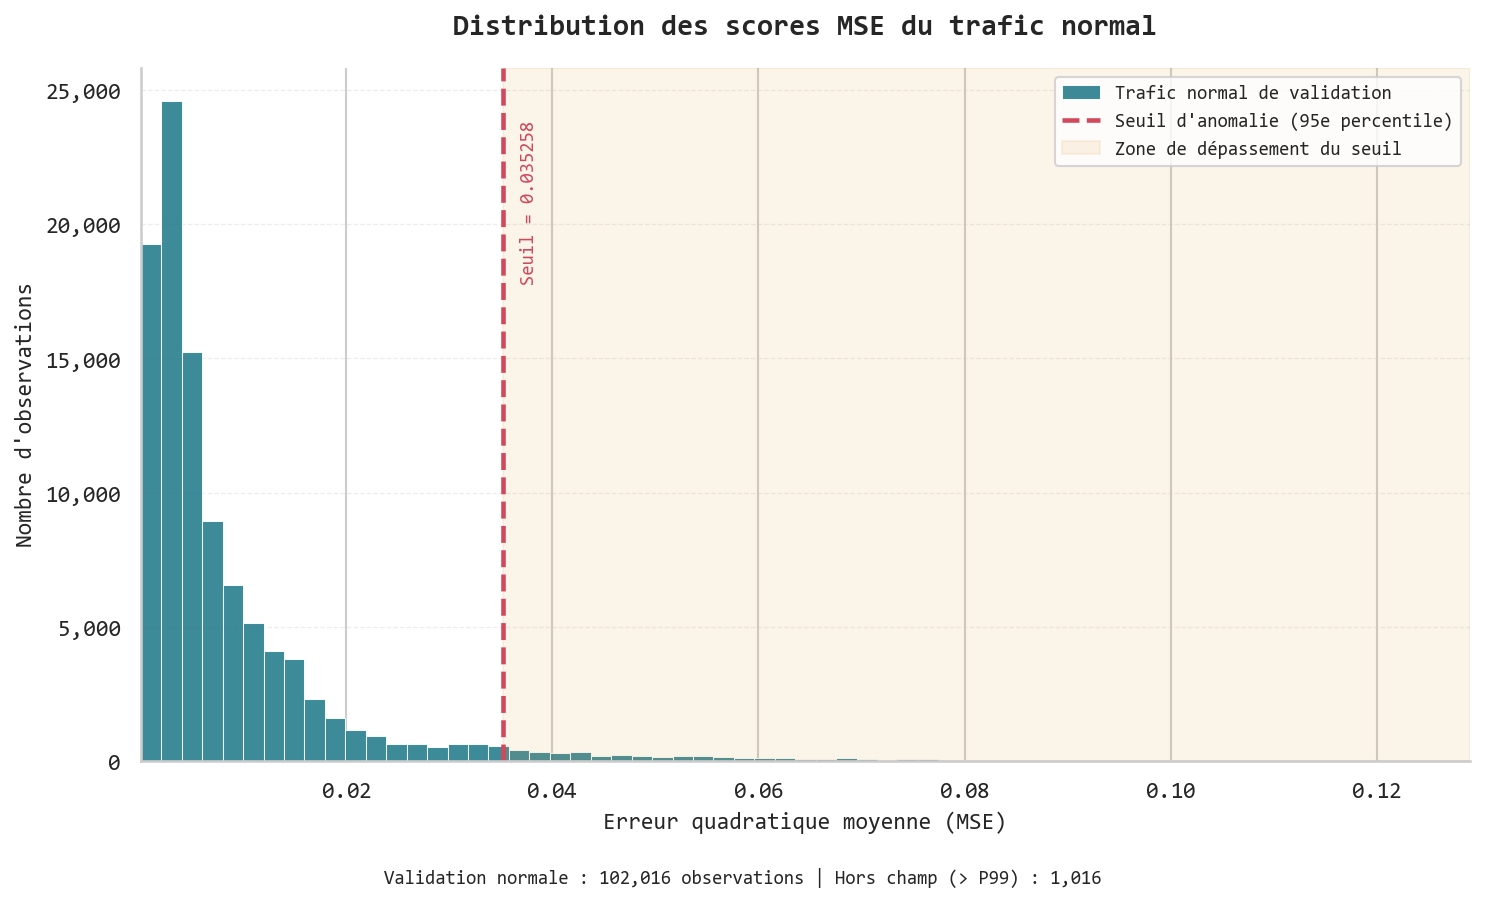


STATISTIQUES DE LA FIGURE


,Indicateur,Valeur
0,Nombre d'observations,102016.000000
1,MSE moyen,0.011150
2,MSE median,0.004802
3,95e percentile,0.035258
4,99e percentile,0.129028
5,MSE maximal,2.141587
6,Observations hors champ,1016.000000



FIGURE DE CALIBRATION TERMINEE
Population : trafic normal de validation
Seuil conserve : 0.0352576726

Figure PNG : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\distribution_scores_MSE_validation_DDAE.png
Figure PDF : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\distribution_scores_MSE_validation_DDAE.pdf
Figure SVG : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\distribution_scores_MSE_validation_DDAE.svg

Test independant utilise : NON
Seuil modifie : NON


In [48]:

# ============================================================
# CELLULE 19 — DISTRIBUTION DES SCORES MSE DE VALIDATION
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Figure :
# Distribution des scores MSE du trafic normal
# de validation et seuil au 95e percentile.
#
# Aucun score de test utilise.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import json

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "Le seuil d'anomalie n'a pas ete calibre. "
        "Executer la cellule 18."
    )

if not globals().get("VALIDATION_SCORES_READY", False):
    raise RuntimeError(
        "Les scores de validation sont indisponibles."
    )

# ------------------------------------------------------------
# 2. Extraction des scores et du seuil
# ------------------------------------------------------------

scores = np.asarray(
    mse_val_normal,
    dtype=np.float64
)

threshold = float(THRESHOLD_DDAE)

if scores.ndim != 1 or scores.size == 0:
    raise ValueError(
        "Vecteur de scores invalide."
    )

if not np.isfinite(scores).all():
    raise ValueError(
        "Scores MSE non finis."
    )

if np.any(scores < 0):
    raise ValueError(
        "Scores MSE negatifs."
    )

if not np.isfinite(threshold):
    raise ValueError(
        "Seuil invalide."
    )

# Verification de l'immutabilite du seuil

threshold_check = float(
    np.percentile(
        scores,
        95,
        method="linear"
    )
)

assert np.isclose(
    threshold,
    threshold_check,
    rtol=1e-12,
    atol=0
), "Le seuil ne correspond plus a la calibration."

print("\nObservations de validation :", len(scores))
print("Seuil MSE :", f"{threshold:.10f}")

# ------------------------------------------------------------
# 3. Statistiques descriptives
# ------------------------------------------------------------

P50 = float(np.percentile(scores, 50))
P95 = float(np.percentile(scores, 95))
P99 = float(np.percentile(scores, 99))

mean_score = float(np.mean(scores))
max_score = float(np.max(scores))

print("\nSTATISTIQUES DES SCORES")

print("Moyenne :", f"{mean_score:.8f}")
print("Mediane :", f"{P50:.8f}")
print("95e percentile :", f"{P95:.8f}")
print("99e percentile :", f"{P99:.8f}")
print("Maximum :", f"{max_score:.8f}")

# ------------------------------------------------------------
# 4. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_NORMAL = "#287D8E"
COLOR_THRESHOLD = "#D1495B"
COLOR_TAIL = "#E4A547"

# ------------------------------------------------------------
# 5. Choix de la zone principale d'affichage
# ------------------------------------------------------------

# Le 99e percentile est utilise uniquement
# pour cadrer la figure.
#
# Il ne modifie pas la calibration ni
# le seuil de decision.

plot_min = float(np.min(scores))

plot_max = float(
    np.percentile(scores, 99)
)

if plot_max <= plot_min:
    plot_max = max(
        max_score,
        plot_min + 1e-9
    )

# La figure principale conserve les valeurs
# situees dans cette fenetre.
#
# Le nombre d'observations hors champ
# sera indique explicitement.

visible_mask = (
    (scores >= plot_min)
    & (scores <= plot_max)
)

visible_scores = scores[visible_mask]

n_outside = int(
    (~visible_mask).sum()
)

# ------------------------------------------------------------
# 6. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

ax.hist(
    visible_scores,
    bins=65,
    color=COLOR_NORMAL,
    edgecolor="white",
    linewidth=0.5,
    alpha=0.90,
    label="Trafic normal de validation"
)

# ------------------------------------------------------------
# 7. Seuil d'anomalie
# ------------------------------------------------------------

ax.axvline(
    threshold,
    color=COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label=(
        "Seuil d'anomalie "
        "(95e percentile)"
    )
)

# ------------------------------------------------------------
# 8. Zone au-dela du seuil
# ------------------------------------------------------------

if threshold < plot_max:

    ax.axvspan(
        threshold,
        plot_max,
        color=COLOR_TAIL,
        alpha=0.12,
        label="Zone de dépassement du seuil"
    )

# ------------------------------------------------------------
# 9. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Distribution des scores MSE du trafic normal",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax.set_xlabel(
    "Erreur quadratique moyenne (MSE)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_xlim(
    plot_min,
    plot_max
)

ax.xaxis.set_major_formatter(
    mpl.ticker.ScalarFormatter(
        useMathText=True
    )
)

ax.ticklabel_format(
    axis="x",
    style="sci",
    scilimits=(-3, 3)
)

ax.yaxis.set_major_formatter(
    mpl.ticker.StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 10. Annotation du seuil
# ------------------------------------------------------------

ax.annotate(
    f"Seuil = {threshold:.5g}",
    xy=(threshold, 0.96),
    xycoords=(
        "data",
        "axes fraction"
    ),
    xytext=(8, -12),
    textcoords="offset points",
    rotation=90,
    ha="left",
    va="top",
    fontsize=9,
    color=COLOR_THRESHOLD,
    fontfamily=SCIENTIFIC_FONT
)

# ------------------------------------------------------------
# 11. Legende et note scientifique
# ------------------------------------------------------------

ax.legend(
    loc="upper right",
    fontsize=9,
    frameon=True
)

figure_note = (
    f"Validation normale : {len(scores):,} observations"
    f" | Hors champ (> P99) : {n_outside:,}"
)

fig.text(
    0.5,
    0.01,
    figure_note,
    ha="center",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.04, 1, 1)
)

# ------------------------------------------------------------
# 12. Sauvegarde de la figure
# ------------------------------------------------------------

FIGURE_NAME = (
    "distribution_scores_MSE_validation_DDAE"
)

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    dpi=300,
    format="png",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 13. Tableau des statistiques
# ------------------------------------------------------------

plot_statistics = pd.DataFrame({
    "Indicateur": [
        "Nombre d'observations",
        "MSE moyen",
        "MSE median",
        "95e percentile",
        "99e percentile",
        "MSE maximal",
        "Observations hors champ"
    ],
    "Valeur": [
        float(len(scores)),
        mean_score,
        P50,
        P95,
        P99,
        max_score,
        float(n_outside)
    ]
})

print("\nSTATISTIQUES DE LA FIGURE")

display(plot_statistics)

plot_statistics.to_csv(
    TABLES_DIR /
    "statistiques_distribution_MSE_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Rapport de tracabilite
# ------------------------------------------------------------

figure_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "figure": FIGURE_NAME,
    "population": "validation_normale",
    "nombre_observations": int(len(scores)),
    "score": "MSE_individuel",
    "seuil": threshold,
    "percentile_calibration": 95,
    "borne_superieure_affichage": plot_max,
    "observations_hors_champ": n_outside,
    "mise_a_echelle": "lineaire",
    "test_utilise": False,
    "seuil_modifie": False,
    "figure_normal_attaque": False
}

with open(
    ARTIFACTS_DIR /
    "rapport_figure_scores_validation_DDAE.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        figure_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. Verification finale
# ------------------------------------------------------------

assert np.isclose(
    threshold,
    THRESHOLD_DDAE
)

assert len(visible_scores) + n_outside == len(scores)

print("\n" + "=" * 70)
print("FIGURE DE CALIBRATION TERMINEE")
print("=" * 70)

print("Population : trafic normal de validation")
print("Seuil conserve :", f"{threshold:.10f}")

print("\nFigure PNG :", png_path)
print("Figure PDF :", pdf_path)
print("Figure SVG :", svg_path)

print("\nTest independant utilise : NON")
print("Seuil modifie : NON")


In [50]:

# ============================================================
# CELLULE 20 — SCORES MSE SUR LE TEST INDEPENDANT
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Calculer les scores MSE individuels sur le test
# reserve et appliquer le seuil deja calibre.
#
# INTERDICTIONS :
# - Aucun fit() sur le test
# - Aucun nouvel entrainement
# - Aucun recalibrage du seuil
# - Aucune optimisation des hyperparametres
# ============================================================

import time
import json
import hashlib
import numpy as np
import pandas as pd

from scipy import sparse


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Protocole experimental non valide."
    )

if not globals().get("CLEAN_AUDIT_PASSED", False):
    raise RuntimeError(
        "Audit d'independance non valide."
    )

if not globals().get("TRAINING_COMPLETED", False):
    raise RuntimeError(
        "Entrainement du DDAE non termine."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "Calibration du seuil non terminee."
    )

required_objects = [
    "X_test_encoded",
    "y_test",
    "ids_test",
    "INPUT_DIM",
    "THRESHOLD_DDAE",
    "ddae_scoring_model",
    "compute_reconstruction_mse",
    "BATCH_SIZE",
    "SCORES_DIR",
    "THRESHOLD_PATH"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Verification du test independant
# ------------------------------------------------------------

X_test_csr = (
    X_test_encoded.tocsr()
    if sparse.issparse(X_test_encoded)
    else sparse.csr_matrix(
        X_test_encoded,
        dtype=np.float32
    )
)

if X_test_csr.shape[1] != INPUT_DIM:
    raise ValueError(
        "Dimension du test incompatible avec le DDAE."
    )

if len(ids_test) != X_test_csr.shape[0]:
    raise ValueError(
        "Nombre d'identifiants incorrect."
    )

if len(y_test) != X_test_csr.shape[0]:
    raise ValueError(
        "Nombre d'etiquettes incorrect."
    )

if not np.isfinite(X_test_csr.data).all():
    raise ValueError(
        "Valeurs non finies detectees dans le test."
    )

y_test_array = y_test.to_numpy(
    dtype=np.int8
)

if not set(np.unique(y_test_array)).issubset({0, 1}):
    raise ValueError(
        "Etiquettes de test invalides."
    )

assert np.array_equal(
    y.iloc[ids_test].to_numpy(dtype=np.int8),
    y_test_array
)

print("\nDIMENSIONS DU TEST")

print("Observations :", X_test_csr.shape[0])
print("Caracteristiques :", X_test_csr.shape[1])

print("\nRepartition du test :")
print("Normaux :", int((y_test_array == 0).sum()))
print("Attaques :", int((y_test_array == 1).sum()))

# ------------------------------------------------------------
# 3. Verification du seuil sauvegarde
# ------------------------------------------------------------

with open(
    THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    threshold_config = json.load(file)

FIXED_THRESHOLD = float(
    threshold_config["seuil"]
)

if not np.isclose(
    FIXED_THRESHOLD,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
):
    raise RuntimeError(
        "Le seuil sauvegarde differe du seuil "
        "calibre a la cellule 18."
    )

if threshold_config["percentile"] != 95:
    raise RuntimeError(
        "Politique de calibration incorrecte."
    )

if threshold_config["population_calibration"] != (
    "validation_normale"
):
    raise RuntimeError(
        "Population de calibration incorrecte."
    )

print("\nSEUIL FIXE")

print(
    "95e percentile validation normale :",
    f"{FIXED_THRESHOLD:.10f}"
)

# ------------------------------------------------------------
# 4. Verification du modele
# ------------------------------------------------------------

if ddae_scoring_model.input_shape[-1] != INPUT_DIM:
    raise ValueError(
        "Modele incompatible avec le test."
    )

if ddae_scoring_model.output_shape[-1] != INPUT_DIM:
    raise ValueError(
        "Reconstruction de dimension incorrecte."
    )

# Empreinte du fichier de modele retenu

def sha256_file(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()


MODEL_SHA256 = sha256_file(
    BEST_MODEL_PATH
)

print("\nEmpreinte SHA-256 du modele :")
print(MODEL_SHA256)

# ------------------------------------------------------------
# 5. Calcul des scores individuels
# ------------------------------------------------------------

# La fonction a ete definie en cellule 17.
# Elle applique le modele sans entrainement.

print("\nCalcul des scores du test...")

start_time = time.perf_counter()

mse_test = compute_reconstruction_mse(
    model=ddae_scoring_model,
    matrix=X_test_csr,
    batch_size=BATCH_SIZE
)

test_scoring_duration = (
    time.perf_counter() - start_time
)

print("\nCalcul termine.")

print(
    "Duree :",
    f"{test_scoring_duration:.2f} secondes"
)

# ------------------------------------------------------------
# 6. Verification des scores
# ------------------------------------------------------------

assert mse_test.ndim == 1

assert len(mse_test) == len(ids_test)

assert np.isfinite(mse_test).all()

assert np.all(mse_test >= 0)

print("\nStatistiques globales des scores :")

print("Minimum :", float(np.min(mse_test)))
print("Moyenne :", float(np.mean(mse_test)))
print("Mediane :", float(np.median(mse_test)))
print("Maximum :", float(np.max(mse_test)))

# ------------------------------------------------------------
# 7. Application du seuil fixe
# ------------------------------------------------------------

# 0 = normal
# 1 = anomalie / attaque potentielle
#
# Aucune optimisation du seuil sur y_test.

y_pred_test = (
    mse_test > FIXED_THRESHOLD
).astype(np.int8)

assert len(y_pred_test) == len(y_test_array)

print("\nPREDICTIONS AVEC LE SEUIL FIXE")

print(
    "Predictions normales :",
    int((y_pred_test == 0).sum())
)

print(
    "Predictions anomalies :",
    int((y_pred_test == 1).sum())
)

# ------------------------------------------------------------
# 8. Preparation du tableau individuel
# ------------------------------------------------------------

test_scores_table = pd.DataFrame({
    "ID_observation": ids_test,
    "Classe_reelle": y_test_array,
    "Score_MSE": mse_test,
    "Seuil_DDAE": FIXED_THRESHOLD,
    "Prediction_DDAE": y_pred_test
})

# Metadonnees exclusivement pour analyse finale
# et non pour ajuster les predictions.

test_attack_categories = (
    attack_metadata.iloc[ids_test]
    .to_numpy()
)

test_scores_table["Categorie_attaque"] = (
    test_attack_categories
)

print("\nAPERÇU DES RESULTATS")

display(test_scores_table.head(10))

# ------------------------------------------------------------
# 9. Sauvegarde des scores et predictions
# ------------------------------------------------------------

SCORES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

np.save(
    SCORES_DIR / "scores_MSE_test_DDAE.npy",
    mse_test
)

np.save(
    SCORES_DIR / "predictions_test_DDAE.npy",
    y_pred_test
)

test_scores_table.to_csv(
    TABLES_DIR / "scores_individuels_test_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. Rapport de tracabilite
# ------------------------------------------------------------

test_scoring_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "ensemble": "test_independant",
    "nombre_observations": int(len(ids_test)),
    "nombre_caracteristiques": int(INPUT_DIM),
    "nombre_normaux": int(
        (y_test_array == 0).sum()
    ),
    "nombre_attaques": int(
        (y_test_array == 1).sum()
    ),
    "score": "MSE_individuel",
    "orientation": "score_eleve_plus_anormal",
    "seuil": float(FIXED_THRESHOLD),
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "operateur_decision": ">",
    "modele_sha256": MODEL_SHA256,
    "duree_scoring_secondes": float(
        test_scoring_duration
    ),
    "aucun_fit_sur_test": True,
    "aucun_recalibrage_sur_test": True,
    "aucune_selection_hyperparametres_sur_test": True
}

TEST_REPORT_PATH = (
    ARTIFACTS_DIR / "rapport_evaluation_test_DDAE.json"
)

with open(
    TEST_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        test_scoring_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 11. Verification des exports
# ------------------------------------------------------------

saved_scores = np.load(
    SCORES_DIR / "scores_MSE_test_DDAE.npy"
)

saved_predictions = np.load(
    SCORES_DIR / "predictions_test_DDAE.npy"
)

assert np.array_equal(
    saved_scores,
    mse_test
)

assert np.array_equal(
    saved_predictions,
    y_pred_test
)

# ------------------------------------------------------------
# 12. Bilan final
# ------------------------------------------------------------

TEST_SCORES_READY = True

print("\n" + "=" * 70)
print("EVALUATION DU TEST — SCORES CALCULES")
print("=" * 70)

print("Observations du test :", len(ids_test))
print("Caracteristiques :", INPUT_DIM)

print(
    "Seuil applique :",
    f"{FIXED_THRESHOLD:.10f}"
)

print(
    "Scores finis :",
    bool(np.isfinite(mse_test).all())
)

print("\nFichiers sauvegardes :")
print(SCORES_DIR)
print(TEST_REPORT_PATH)



DIMENSIONS DU TEST
Observations : 104871
Caracteristiques : 70

Repartition du test :
Normaux : 101507
Attaques : 3364

SEUIL FIXE
95e percentile validation normale : 0.0352576726

Empreinte SHA-256 du modele :
3e08f999f9151652d79beabd74ff1f3dd72c92514f65afca56211962a8dae39a

Calcul des scores du test...

Calcul termine.
Duree : 1.28 secondes

Statistiques globales des scores :
Minimum : 7.84249279392421e-05
Moyenne : 0.038457381898222134
Mediane : 0.00499778871850391
Maximum : 369.4549854525829

PREDICTIONS AVEC LE SEUIL FIXE
Predictions normales : 96691
Predictions anomalies : 8180

APERÇU DES RESULTATS


,ID_observation,Classe_reelle,Score_MSE,Seuil_DDAE,Prediction_DDAE,Categorie_attaque
0,0,0,0.008440,0.035258,0,<NA>
1,2,0,0.015330,0.035258,0,<NA>
2,4,0,0.010701,0.035258,0,<NA>
3,7,0,2.619276,0.035258,1,<NA>
4,10,0,2.619276,0.035258,1,<NA>
5,11,0,2.619276,0.035258,1,<NA>
6,12,0,2.619276,0.035258,1,<NA>
7,31,0,0.007779,0.035258,0,<NA>
8,37,0,0.003821,0.035258,0,<NA>
9,56,0,0.016201,0.035258,0,<NA>



EVALUATION DU TEST — SCORES CALCULES
Observations du test : 104871
Caracteristiques : 70
Seuil applique : 0.0352576726
Scores finis : True

Fichiers sauvegardes :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\scores
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\artefacts\rapport_evaluation_test_DDAE.json



POPULATIONS DU TEST
Trafic normal : 101,507
Attaques : 3,364
Seuil fixe : 0.0352576726

STATISTIQUES COMPARATIVES


,Population,Effectif,Minimum,Moyenne,Mediane,P25,P75,P95,P99,Maximum,Au_dessus_du_seuil,Taux_depassement_pct
0,Trafic normal,101507,0.000078,0.028738,0.004776,0.002508,0.010433,0.034684,0.137027,369.454985,4974,4.900155
1,Attaques,3364,0.008358,0.331744,0.130841,0.085004,0.183162,0.614972,2.391848,95.883841,3206,95.303210


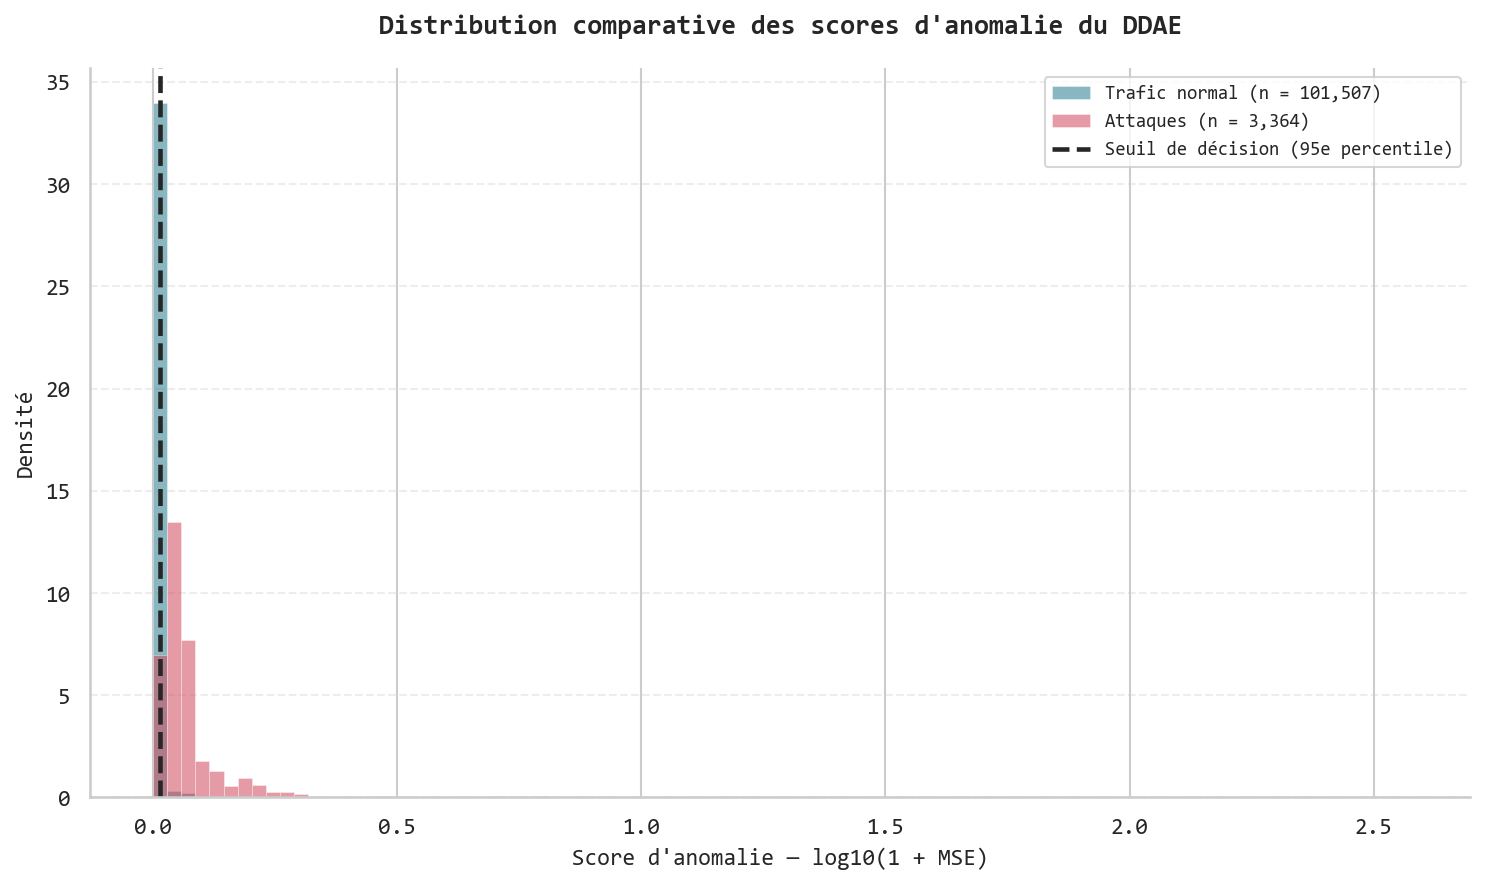

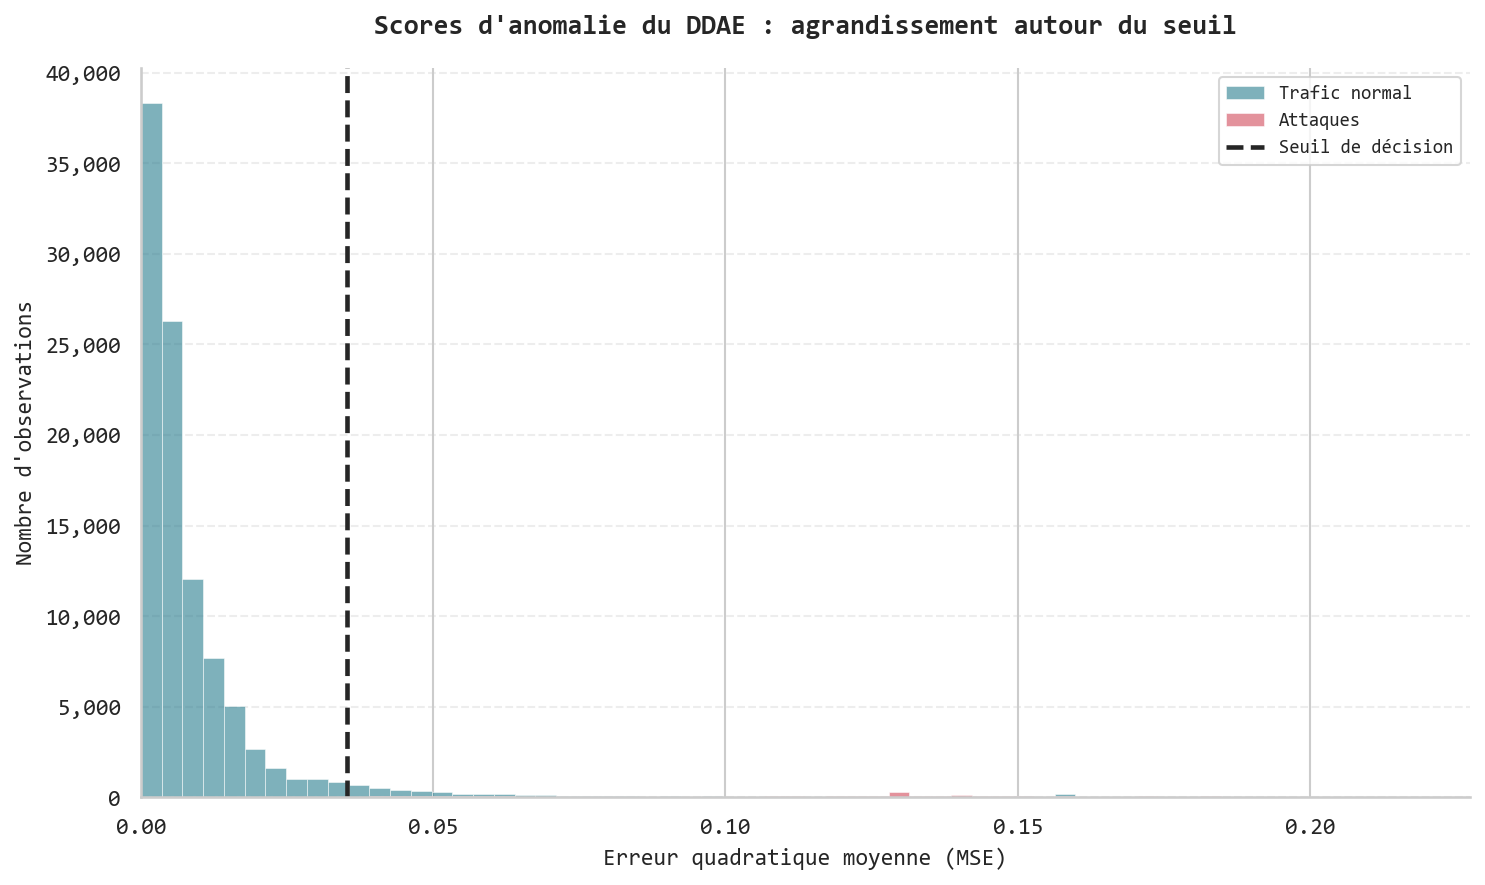


CONTROLE DE LA FIGURE AGRANDIE
Normaux hors champ : 383
Attaques hors champ : 623
Borne inferieure : 0.0
Borne superieure : 0.2273517011752124

FIGURES COMPARATIVES TERMINEES

Figure complete :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\distribution_scores_normal_attaques_DDAE

Figure agrandie :
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\zoom_scores_normal_attaques_DDAE

Seuil conserve : 0.0352576726

Modele modifie : NON
Pretraitement modifie : NON
Seuil recalibre : NON


In [53]:

# ============================================================
# CELLULE 21 — DISTRIBUTION DES SCORES D'ANOMALIE DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Comparer la distribution des scores MSE
# du trafic normal et des attaques sur le
# test independant, avec le seuil de decision.
#
# Aucune modification du modele ou du seuil.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Les scores du test ne sont pas disponibles. "
        "Executer la cellule 20."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "La calibration n'est pas terminee."
    )

required_objects = [
    "mse_test",
    "y_test_array",
    "THRESHOLD_DDAE",
    "FIXED_THRESHOLD",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Recuperation des scores
# ------------------------------------------------------------

scores = np.asarray(
    mse_test,
    dtype=np.float64
)

labels = np.asarray(
    y_test_array,
    dtype=np.int8
)

threshold = float(FIXED_THRESHOLD)

assert np.isclose(
    threshold,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
), "Le seuil de calibration a ete modifie."

if scores.ndim != 1:
    raise ValueError(
        "Les scores doivent etre un vecteur."
    )

if len(scores) != len(labels):
    raise ValueError(
        "Scores et etiquettes incompatibles."
    )

if not np.isfinite(scores).all():
    raise ValueError(
        "Scores MSE non finis."
    )

if np.any(scores < 0):
    raise ValueError(
        "Scores MSE negatifs detectes."
    )

if set(np.unique(labels)) != {0, 1}:
    raise ValueError(
        "Les deux classes doivent etre presentes."
    )

# ------------------------------------------------------------
# 3. Separation des populations
# ------------------------------------------------------------

scores_normal = scores[
    labels == 0
]

scores_attack = scores[
    labels == 1
]

n_normal = len(scores_normal)
n_attack = len(scores_attack)

print("\nPOPULATIONS DU TEST")

print("Trafic normal :", f"{n_normal:,}")
print("Attaques :", f"{n_attack:,}")
print("Seuil fixe :", f"{threshold:.10f}")

# ------------------------------------------------------------
# 4. Statistiques descriptives
# ------------------------------------------------------------

def describe_scores(values, population):

    return {
        "Population": population,
        "Effectif": int(len(values)),
        "Minimum": float(np.min(values)),
        "Moyenne": float(np.mean(values)),
        "Mediane": float(np.median(values)),
        "P25": float(np.percentile(values, 25)),
        "P75": float(np.percentile(values, 75)),
        "P95": float(np.percentile(values, 95)),
        "P99": float(np.percentile(values, 99)),
        "Maximum": float(np.max(values)),
        "Au_dessus_du_seuil": int(
            np.sum(values > threshold)
        ),
        "Taux_depassement_pct": float(
            100 * np.mean(values > threshold)
        )
    }


distribution_statistics = pd.DataFrame([
    describe_scores(
        scores_normal,
        "Trafic normal"
    ),
    describe_scores(
        scores_attack,
        "Attaques"
    )
])

print("\nSTATISTIQUES COMPARATIVES")

display(distribution_statistics)

# ------------------------------------------------------------
# 5. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_NORMAL = "#287D8E"
COLOR_ATTACK = "#D1495B"
COLOR_THRESHOLD = "#262626"

# ------------------------------------------------------------
# 6. Bornes communes pour les histogrammes
# ------------------------------------------------------------

# Une echelle logarithmique x permet de
# mieux representer les scores tres asymetriques.
#
# log10(1 + score) reste defini pour MSE >= 0.
#
# Les scores d'origine ne sont pas modifies.

normal_log = np.log10(
    1.0 + scores_normal
)

attack_log = np.log10(
    1.0 + scores_attack
)

threshold_log = np.log10(
    1.0 + threshold
)

all_log = np.concatenate([
    normal_log,
    attack_log
])

x_min = float(np.min(all_log))
x_max = float(np.max(all_log))

if np.isclose(x_min, x_max):
    x_max = x_min + 1e-6

bins = np.linspace(
    x_min,
    x_max,
    90
)

# ------------------------------------------------------------
# 7. FIGURE A — DISTRIBUTION COMPLETE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

ax.hist(
    normal_log,
    bins=bins,
    density=True,
    alpha=0.55,
    color=COLOR_NORMAL,
    edgecolor="white",
    linewidth=0.3,
    label=(
        f"Trafic normal (n = {n_normal:,})"
    )
)

ax.hist(
    attack_log,
    bins=bins,
    density=True,
    alpha=0.55,
    color=COLOR_ATTACK,
    edgecolor="white",
    linewidth=0.3,
    label=(
        f"Attaques (n = {n_attack:,})"
    )
)

ax.axvline(
    threshold_log,
    color=COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label="Seuil de décision (95e percentile)"
)

ax.set_title(
    "Distribution comparative des scores d'anomalie du DDAE",
    fontsize=13,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax.set_xlabel(
    "Score d'anomalie — log10(1 + MSE)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Densité",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.legend(
    fontsize=9,
    loc="best",
    frameon=True
)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# Sauvegarde figure A

FIGURE_A = (
    FIGURES_DIR /
    "distribution_scores_normal_attaques_DDAE"
)

for extension in ["png", "pdf", "svg"]:

    fig.savefig(
        FIGURE_A.with_suffix("." + extension),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 8. FIGURE B — ZOOM AUTOUR DU SEUIL
# ------------------------------------------------------------

# Les quantiles ci-dessous servent uniquement
# a determiner les limites d'affichage.
# Ils ne modifient pas le seuil de decision.

lower_bound = float(
    np.percentile(scores_normal, 50)
)

upper_bound = float(
    np.percentile(
        np.concatenate([
            scores_normal,
            scores_attack
        ]),
        99
    )
)

# Le seuil doit toujours rester visible.
lower_bound = min(
    lower_bound,
    threshold
)

upper_bound = max(
    upper_bound,
    threshold
)

# Marges pour eviter de coller le seuil au bord.

display_range = max(
    upper_bound - lower_bound,
    1e-9
)

lower_bound = max(
    0.0,
    lower_bound - 0.05 * display_range
)

upper_bound = (
    upper_bound + 0.05 * display_range
)

normal_zoom = scores_normal[
    (scores_normal >= lower_bound)
    & (scores_normal <= upper_bound)
]

attack_zoom = scores_attack[
    (scores_attack >= lower_bound)
    & (scores_attack <= upper_bound)
]

zoom_bins = np.linspace(
    lower_bound,
    upper_bound,
    65
)

fig_zoom, ax_zoom = plt.subplots(
    figsize=(10, 6),
    dpi=150
)

ax_zoom.hist(
    normal_zoom,
    bins=zoom_bins,
    density=False,
    alpha=0.60,
    color=COLOR_NORMAL,
    edgecolor="white",
    linewidth=0.4,
    label="Trafic normal"
)

ax_zoom.hist(
    attack_zoom,
    bins=zoom_bins,
    density=False,
    alpha=0.60,
    color=COLOR_ATTACK,
    edgecolor="white",
    linewidth=0.4,
    label="Attaques"
)

ax_zoom.axvline(
    threshold,
    color=COLOR_THRESHOLD,
    linestyle="--",
    linewidth=2.2,
    label="Seuil de décision"
)

ax_zoom.set_title(
    "Scores d'anomalie du DDAE : agrandissement autour du seuil",
    fontsize=13,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax_zoom.set_xlabel(
    "Erreur quadratique moyenne (MSE)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax_zoom.set_ylabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax_zoom.set_xlim(
    lower_bound,
    upper_bound
)

ax_zoom.yaxis.set_major_formatter(
    mpl.ticker.StrMethodFormatter("{x:,.0f}")
)

ax_zoom.ticklabel_format(
    axis="x",
    style="sci",
    scilimits=(-3, 3)
)

ax_zoom.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax_zoom.legend(
    fontsize=9,
    loc="best"
)

sns.despine(
    ax=ax_zoom,
    top=True,
    right=True
)

plt.tight_layout()

# Sauvegarde figure B

FIGURE_B = (
    FIGURES_DIR /
    "zoom_scores_normal_attaques_DDAE"
)

for extension in ["png", "pdf", "svg"]:

    fig_zoom.savefig(
        FIGURE_B.with_suffix("." + extension),
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()

# ------------------------------------------------------------
# 9. Controle des observations hors champ
# ------------------------------------------------------------

normal_outside = int(
    n_normal - len(normal_zoom)
)

attack_outside = int(
    n_attack - len(attack_zoom)
)

print("\nCONTROLE DE LA FIGURE AGRANDIE")

print(
    "Normaux hors champ :",
    normal_outside
)

print(
    "Attaques hors champ :",
    attack_outside
)

print(
    "Borne inferieure :",
    lower_bound
)

print(
    "Borne superieure :",
    upper_bound
)

# ------------------------------------------------------------
# 10. Export des statistiques
# ------------------------------------------------------------

distribution_statistics.to_csv(
    TABLES_DIR /
    "statistiques_scores_normal_attaques_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. Rapport des figures
# ------------------------------------------------------------

figure_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "score": "MSE_individuel",
    "normal_count": n_normal,
    "attack_count": n_attack,
    "seuil": threshold,
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "figure_complete": str(FIGURE_A),
    "figure_agrandie": str(FIGURE_B),
    "axe_figure_complete": "log10(1+MSE)",
    "axe_figure_agrandie": "MSE",
    "normal_hors_champ_zoom": normal_outside,
    "attaques_hors_champ_zoom": attack_outside,
    "seuil_modifie": False,
    "modele_modifie": False,
    "pretraitement_modifie": False
}

with open(
    ARTIFACTS_DIR /
    "rapport_figures_scores_test_DDAE.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        figure_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 12. Verification finale
# ------------------------------------------------------------

assert len(scores_normal) + len(scores_attack) == (
    len(mse_test)
)

assert np.isclose(
    threshold,
    THRESHOLD_DDAE
)

FIGURE_SCORES_TEST_READY = True

print("\n" + "=" * 70)
print("FIGURES COMPARATIVES TERMINEES")
print("=" * 70)

print("\nFigure complete :")
print(FIGURE_A)

print("\nFigure agrandie :")
print(FIGURE_B)

print("\nSeuil conserve :", f"{threshold:.10f}")

print("\nModele modifie : NON")
print("Pretraitement modifie : NON")
print("Seuil recalibre : NON")


Controles de coherence : VALIDES

MATRICE DE CONFUSION
[[96533  4974]
 [  158  3206]]

EFFECTIFS
Observations : 104,871
Trafic normal : 101,507
Attaques : 3,364

Vrais negatifs (TN) : 96,533
Faux positifs (FP) : 4,974
Faux negatifs (FN) : 158
Vrais positifs (TP) : 3,206

TAUX DE CLASSIFICATION
Taux de fausses alertes (FPR) : 4.9002 %
Taux d'attaques manquees (FNR) : 4.6968 %
Specificite (TNR) : 95.0998 %
Rappel des attaques (TPR) : 95.3032 %

TABLEAU DE CONFUSION


,Prédit : normal,Prédit : attaque
Réel : normal,96533,4974
Réel : attaque,158,3206


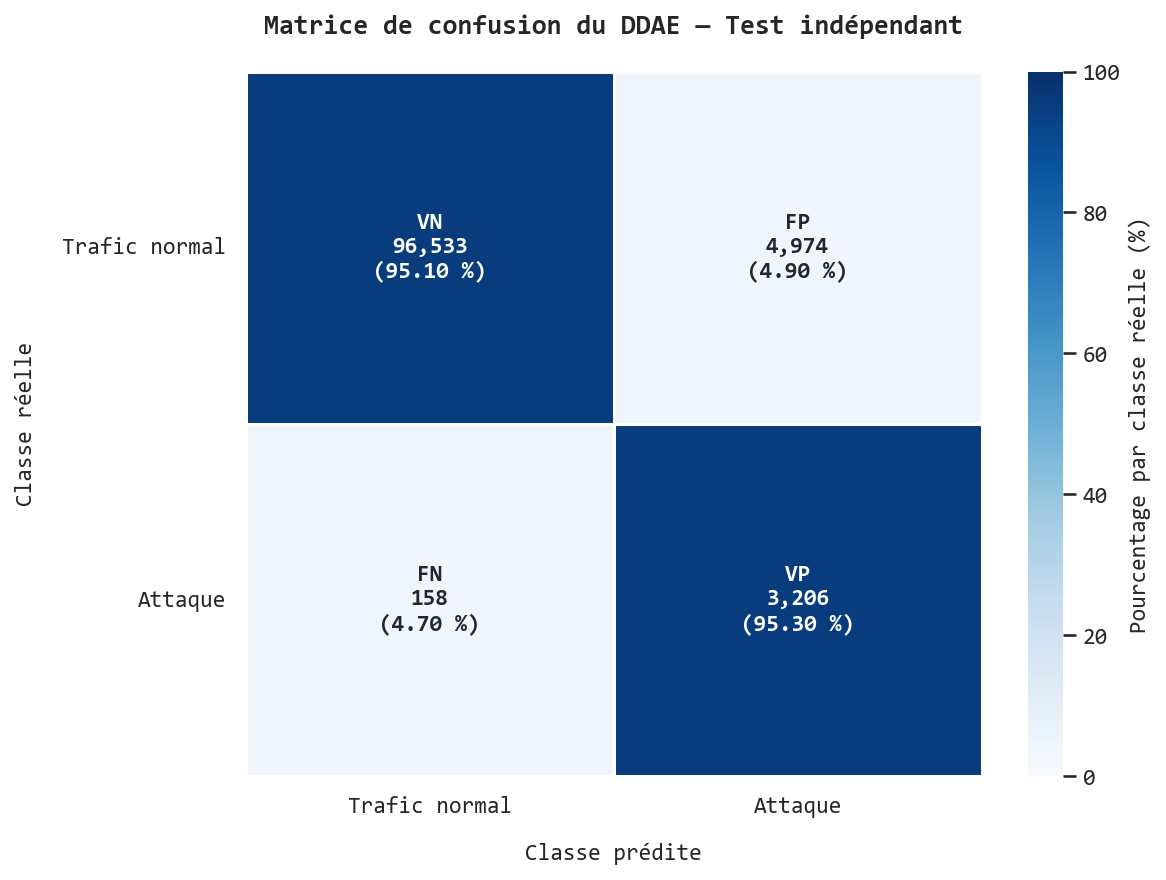


MATRICE DE CONFUSION CALCULEE
Vrais negatifs : 96533
Faux positifs : 4974
Faux negatifs : 158
Vrais positifs : 3206

Taux de fausses alertes : 4.9002 %
Taux d'attaques manquees : 4.6968 %

Figure PNG : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\matrice_confusion_DDAE_test_independant.png
Figure PDF : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\matrice_confusion_DDAE_test_independant.pdf
Figure SVG : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\figures\matrice_confusion_DDAE_test_independant.svg


In [55]:

# ============================================================
# CELLULE 22 — MATRICE DE CONFUSION DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation : test independant
# Seuil : 95e percentile de validation normale
#
# Aucune modification du modele ou du seuil.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Les scores du test sont indisponibles. "
        "Executer la cellule 20."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "Le seuil n'a pas ete calibre."
    )

required_objects = [
    "y_test_array",
    "y_pred_test",
    "mse_test",
    "THRESHOLD_DDAE",
    "FIXED_THRESHOLD",
    "ids_test",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Recuperation des resultats du test
# ------------------------------------------------------------

y_true = np.asarray(
    y_test_array,
    dtype=np.int8
)

y_pred = np.asarray(
    y_pred_test,
    dtype=np.int8
)

test_scores = np.asarray(
    mse_test,
    dtype=np.float64
)

threshold = float(
    FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. Controles de coherence
# ------------------------------------------------------------

assert y_true.ndim == 1
assert y_pred.ndim == 1

assert len(y_true) == len(y_pred)
assert len(y_true) == len(test_scores)
assert len(y_true) == len(ids_test)

assert set(np.unique(y_true)) == {0, 1}

assert set(np.unique(y_pred)).issubset({0, 1})

assert np.isfinite(test_scores).all()

assert np.isclose(
    threshold,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
), "Le seuil a ete modifie."

# Les predictions doivent correspondre
# exactement au seuil fixe de validation.

expected_predictions = (
    test_scores > threshold
).astype(np.int8)

assert np.array_equal(
    y_pred,
    expected_predictions
), (
    "Les predictions ne correspondent pas "
    "au seuil fixe."
)

print("\nControles de coherence : VALIDES")

# ------------------------------------------------------------
# 4. Calcul de la matrice de confusion
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

TN, FP, FN, TP = cm.ravel()

TN = int(TN)
FP = int(FP)
FN = int(FN)
TP = int(TP)

print("\nMATRICE DE CONFUSION")

print(cm)

# ------------------------------------------------------------
# 5. Verification des effectifs
# ------------------------------------------------------------

n_total = len(y_true)

n_normal = int(
    np.sum(y_true == 0)
)

n_attack = int(
    np.sum(y_true == 1)
)

assert TN + FP == n_normal
assert FN + TP == n_attack

assert TN + FP + FN + TP == n_total

print("\nEFFECTIFS")

print("Observations :", f"{n_total:,}")
print("Trafic normal :", f"{n_normal:,}")
print("Attaques :", f"{n_attack:,}")

print("\nVrais negatifs (TN) :", f"{TN:,}")
print("Faux positifs (FP) :", f"{FP:,}")
print("Faux negatifs (FN) :", f"{FN:,}")
print("Vrais positifs (TP) :", f"{TP:,}")

# ------------------------------------------------------------
# 6. Taux d'erreurs
# ------------------------------------------------------------

FPR = (
    FP / (FP + TN)
    if FP + TN > 0
    else np.nan
)

FNR = (
    FN / (FN + TP)
    if FN + TP > 0
    else np.nan
)

TNR = (
    TN / (TN + FP)
    if TN + FP > 0
    else np.nan
)

TPR = (
    TP / (TP + FN)
    if TP + FN > 0
    else np.nan
)

print("\nTAUX DE CLASSIFICATION")

print(f"Taux de fausses alertes (FPR) : {FPR*100:.4f} %")
print(f"Taux d'attaques manquees (FNR) : {FNR*100:.4f} %")
print(f"Specificite (TNR) : {TNR*100:.4f} %")
print(f"Rappel des attaques (TPR) : {TPR*100:.4f} %")

# ------------------------------------------------------------
# 7. Tableau de confusion
# ------------------------------------------------------------

class_names = [
    "Trafic normal",
    "Attaque"
]

confusion_table = pd.DataFrame(
    cm,
    index=[
        "Réel : normal",
        "Réel : attaque"
    ],
    columns=[
        "Prédit : normal",
        "Prédit : attaque"
    ]
)

print("\nTABLEAU DE CONFUSION")

display(confusion_table)

# ------------------------------------------------------------
# 8. Normalisation par classe reelle
# ------------------------------------------------------------

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm.astype(np.float64),
    row_totals,
    out=np.zeros_like(
        cm,
        dtype=np.float64
    ),
    where=row_totals != 0
) * 100

# ------------------------------------------------------------
# 9. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(
    style="white"
)

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 10. Annotations : effectifs et pourcentages
# ------------------------------------------------------------

annotations = np.empty(
    (2, 2),
    dtype=object
)

cell_labels = np.array([
    ["VN", "FP"],
    ["FN", "VP"]
])

for i in range(2):
    for j in range(2):

        annotations[i, j] = (
            f"{cell_labels[i, j]}\n"
            f"{cm[i, j]:,}\n"
            f"({cm_normalized[i, j]:.2f} %)"
        )

# ------------------------------------------------------------
# 11. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6),
    dpi=150
)

sns.heatmap(
    cm_normalized,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=1.2,
    linecolor="white",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={
        "label": "Pourcentage par classe réelle (%)"
    },
    annot_kws={
        "fontsize": 11,
        "fontfamily": SCIENTIFIC_FONT,
        "fontweight": "bold"
    },
    ax=ax
)

# ------------------------------------------------------------
# 12. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Matrice de confusion du DDAE — Test indépendant",
    fontsize=13,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Classe prédite",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_ylabel(
    "Classe réelle",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_xticklabels(
    class_names,
    rotation=0
)

ax.set_yticklabels(
    class_names,
    rotation=0
)

plt.tight_layout()

# ------------------------------------------------------------
# 13. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = "matrice_confusion_DDAE_test_independant"

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 14. Export des tableaux
# ------------------------------------------------------------

confusion_table.to_csv(
    TABLES_DIR / "matrice_confusion_DDAE.csv",
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm_normalized,
    index=confusion_table.index,
    columns=confusion_table.columns
).to_csv(
    TABLES_DIR / "matrice_confusion_normalisee_DDAE.csv",
    encoding="utf-8-sig"
)

confusion_indicators = pd.DataFrame({
    "Indicateur": [
        "TN",
        "FP",
        "FN",
        "TP",
        "FPR",
        "FNR",
        "TNR",
        "TPR"
    ],
    "Valeur": [
        TN,
        FP,
        FN,
        TP,
        FPR,
        FNR,
        TNR,
        TPR
    ]
})

confusion_indicators.to_csv(
    TABLES_DIR / "indicateurs_confusion_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. Rapport experimental
# ------------------------------------------------------------

confusion_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "ensemble": "test_independant",
    "observations": n_total,
    "normaux": n_normal,
    "attaques": n_attack,
    "seuil": threshold,
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "TN": TN,
    "FP": FP,
    "FN": FN,
    "TP": TP,
    "FPR": float(FPR),
    "FNR": float(FNR),
    "TNR": float(TNR),
    "TPR": float(TPR),
    "matrice": cm.tolist(),
    "modele_modifie": False,
    "seuil_modifie": False,
    "test_utilise_pour_optimisation": False
}

REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_matrice_confusion_DDAE.json"
)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        confusion_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. Validation finale
# ------------------------------------------------------------

CONFUSION_MATRIX_READY = True

print("\n" + "=" * 70)
print("MATRICE DE CONFUSION CALCULEE")
print("=" * 70)

print("Vrais negatifs :", TN)
print("Faux positifs :", FP)
print("Faux negatifs :", FN)
print("Vrais positifs :", TP)

print(f"\nTaux de fausses alertes : {FPR*100:.4f} %")
print(f"Taux d'attaques manquees : {FNR*100:.4f} %")

print("\nFigure PNG :", png_path)
print("Figure PDF :", pdf_path)
print("Figure SVG :", svg_path)

In [58]:

# ============================================================
# CELLULE 23 — METRIQUES GLOBALES DE PERFORMANCE DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation : test independant
# Seuil : 95e percentile de validation normale
#
# Aucune optimisation du seuil sur le test.
# ============================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("CONFUSION_MATRIX_READY", False):
    raise RuntimeError(
        "La matrice de confusion n'est pas disponible. "
        "Executer la cellule 22."
    )

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Les scores du test sont indisponibles."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "La calibration n'est pas terminee."
    )

# ------------------------------------------------------------
# 2. Recuperation des donnees
# ------------------------------------------------------------

y_true = np.asarray(
    y_test_array,
    dtype=np.int8
)

y_pred = np.asarray(
    y_pred_test,
    dtype=np.int8
)

scores = np.asarray(
    mse_test,
    dtype=np.float64
)

threshold = float(FIXED_THRESHOLD)

# ------------------------------------------------------------
# 3. Verification de coherence
# ------------------------------------------------------------

assert y_true.ndim == 1
assert y_pred.ndim == 1
assert scores.ndim == 1

assert len(y_true) == len(y_pred) == len(scores)

assert set(np.unique(y_true)) == {0, 1}

assert set(np.unique(y_pred)).issubset({0, 1})

assert np.isfinite(scores).all()

assert np.isclose(
    threshold,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

assert np.array_equal(
    y_pred,
    (scores > threshold).astype(np.int8)
)

# ------------------------------------------------------------
# 4. Verification de la matrice de confusion
# ------------------------------------------------------------

cm_check = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = (
    int(v) for v in cm_check.ravel()
)

assert (
    (tn, fp, fn, tp)
    == (TN, FP, FN, TP)
), "Incoherence avec la cellule 22."

# ------------------------------------------------------------
# 5. Calcul des metriques de classification
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

false_positive_rate = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else np.nan
)

false_negative_rate = (
    fn / (fn + tp)
    if (fn + tp) > 0
    else np.nan
)

# ------------------------------------------------------------
# 6. Metriques sans seuil
# ------------------------------------------------------------

# Les scores MSE sont continus.
# Score eleve = observation plus anormale.
#
# Les etiquettes ne servent ici qu'a
# mesurer la discrimination du score.

roc_auc = roc_auc_score(
    y_true,
    scores
)

average_precision = average_precision_score(
    y_true,
    scores
)

# Prevalence des attaques : reference utile
# pour interpreter l'Average Precision.

attack_prevalence = float(
    np.mean(y_true == 1)
)

# ------------------------------------------------------------
# 7. Tableau principal des performances
# ------------------------------------------------------------

performance_metrics = pd.DataFrame({
    "Metrique": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Specificity",
        "Balanced Accuracy",
        "ROC-AUC",
        "Average Precision",
        "FPR",
        "FNR"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        specificity,
        balanced_accuracy,
        roc_auc,
        average_precision,
        false_positive_rate,
        false_negative_rate
    ]
})

performance_metrics["Score (%)"] = (
    performance_metrics["Score"] * 100
)

print("\nPERFORMANCES GLOBALES DU DDAE")

display(
    performance_metrics[
        ["Metrique", "Score (%)"]
    ].style.format({
        "Score (%)": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 8. Affichage detaille des indicateurs
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("INDICATEURS PRINCIPAUX")
print("-" * 70)

print(f"Accuracy          : {accuracy*100:.4f} %")
print(f"Precision         : {precision*100:.4f} %")
print(f"Recall            : {recall*100:.4f} %")
print(f"F1-score          : {f1*100:.4f} %")
print(f"Specificity       : {specificity*100:.4f} %")
print(f"Balanced Accuracy : {balanced_accuracy*100:.4f} %")
print(f"ROC-AUC           : {roc_auc:.6f}")
print(f"Average Precision : {average_precision:.6f}")

print("\nTAUX D'ERREURS")

print(f"FPR : {false_positive_rate*100:.4f} %")
print(f"FNR : {false_negative_rate*100:.4f} %")

print(
    "\nPrevalence des attaques :",
    f"{attack_prevalence*100:.4f} %"
)

# ------------------------------------------------------------
# 9. Rapport de classification
# ------------------------------------------------------------

classification_text = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=[
        "Trafic normal",
        "Attaque"
    ],
    digits=4,
    zero_division=0
)

print("\nRAPPORT DE CLASSIFICATION")

print(classification_text)

classification_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=[
        "Trafic normal",
        "Attaque"
    ],
    output_dict=True,
    zero_division=0
)

# ------------------------------------------------------------
# 10. Verifications mathematiques
# ------------------------------------------------------------

assert np.isclose(
    recall,
    tp / (tp + fn)
)

assert np.isclose(
    accuracy,
    (tp + tn) / len(y_true)
)

assert np.isclose(
    balanced_accuracy,
    (recall + specificity) / 2
)

assert np.isclose(
    false_positive_rate + specificity,
    1.0
)

assert np.isclose(
    false_negative_rate + recall,
    1.0
)

for metric in performance_metrics["Score"]:
    if not np.isfinite(metric):
        raise ValueError(
            "Une metrique non finie a ete detectee."
        )

# ------------------------------------------------------------
# 11. Export des performances
# ------------------------------------------------------------

performance_path = (
    TABLES_DIR /
    "performances_globales_DDAE.csv"
)

performance_metrics.to_csv(
    performance_path,
    index=False,
    encoding="utf-8-sig"
)

classification_path = (
    TABLES_DIR /
    "rapport_classification_DDAE.csv"
)

pd.DataFrame(
    classification_dict
).transpose().to_csv(
    classification_path,
    encoding="utf-8-sig"
)

# Rapport texte

text_report_path = (
    ARTIFACTS_DIR /
    "rapport_classification_DDAE.txt"
)

with open(
    text_report_path,
    "w",
    encoding="utf-8"
) as file:
    file.write(classification_text)

# ------------------------------------------------------------
# 12. Rapport experimental JSON
# ------------------------------------------------------------

metrics_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "protocole": "one-class",
    "ensemble": "test_independant",
    "nombre_observations": int(len(y_true)),
    "normaux": int((y_true == 0).sum()),
    "attaques": int((y_true == 1).sum()),
    "seuil": float(threshold),
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "specificity": float(specificity),
    "balanced_accuracy": float(balanced_accuracy),
    "roc_auc": float(roc_auc),
    "average_precision": float(average_precision),
    "attack_prevalence": attack_prevalence,
    "fpr": float(false_positive_rate),
    "fnr": float(false_negative_rate),
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "score_orientation": "higher_is_more_anomalous",
    "test_used_for_training": False,
    "test_used_for_threshold_selection": False,
    "test_used_for_hyperparameter_selection": False
}

METRICS_REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_performances_DDAE.json"
)

with open(
    METRICS_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metrics_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 13. Variables reutilisables
# ------------------------------------------------------------

DDAE_METRICS = {
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1-score": float(f1),
    "Specificity": float(specificity),
    "Balanced Accuracy": float(balanced_accuracy),
    "ROC-AUC": float(roc_auc),
    "Average Precision": float(average_precision),
    "FPR": float(false_positive_rate),
    "FNR": float(false_negative_rate)
}

METRICS_READY = True



PERFORMANCES GLOBALES DU DDAE


,Metrique,Score (%)
0,Accuracy,95.1064 %
1,Precision,39.1932 %
2,Recall,95.3032 %
3,F1-score,55.5440 %
4,Specificity,95.0998 %
5,Balanced Accuracy,95.2015 %
6,ROC-AUC,98.5124 %
7,Average Precision,57.4567 %
8,FPR,4.9002 %
9,FNR,4.6968 %



----------------------------------------------------------------------
INDICATEURS PRINCIPAUX
----------------------------------------------------------------------
Accuracy          : 95.1064 %
Precision         : 39.1932 %
Recall            : 95.3032 %
F1-score          : 55.5440 %
Specificity       : 95.0998 %
Balanced Accuracy : 95.2015 %
ROC-AUC           : 0.985124
Average Precision : 0.574567

TAUX D'ERREURS
FPR : 4.9002 %
FNR : 4.6968 %

Prevalence des attaques : 3.2078 %

RAPPORT DE CLASSIFICATION
               precision    recall  f1-score   support

Trafic normal     0.9984    0.9510    0.9741    101507
      Attaque     0.3919    0.9530    0.5554      3364

     accuracy                         0.9511    104871
    macro avg     0.6951    0.9520    0.7648    104871
 weighted avg     0.9789    0.9511    0.9607    104871




METRIQUES UTILISEES DANS LA FIGURE


,Libelle_francais,Valeur_pct
0,Exactitude,95.1064 %
1,Précision,39.1932 %
2,Rappel,95.3032 %
3,Score F1,55.5440 %
4,Spécificité,95.0998 %
5,Exactitude équilibrée,95.2015 %


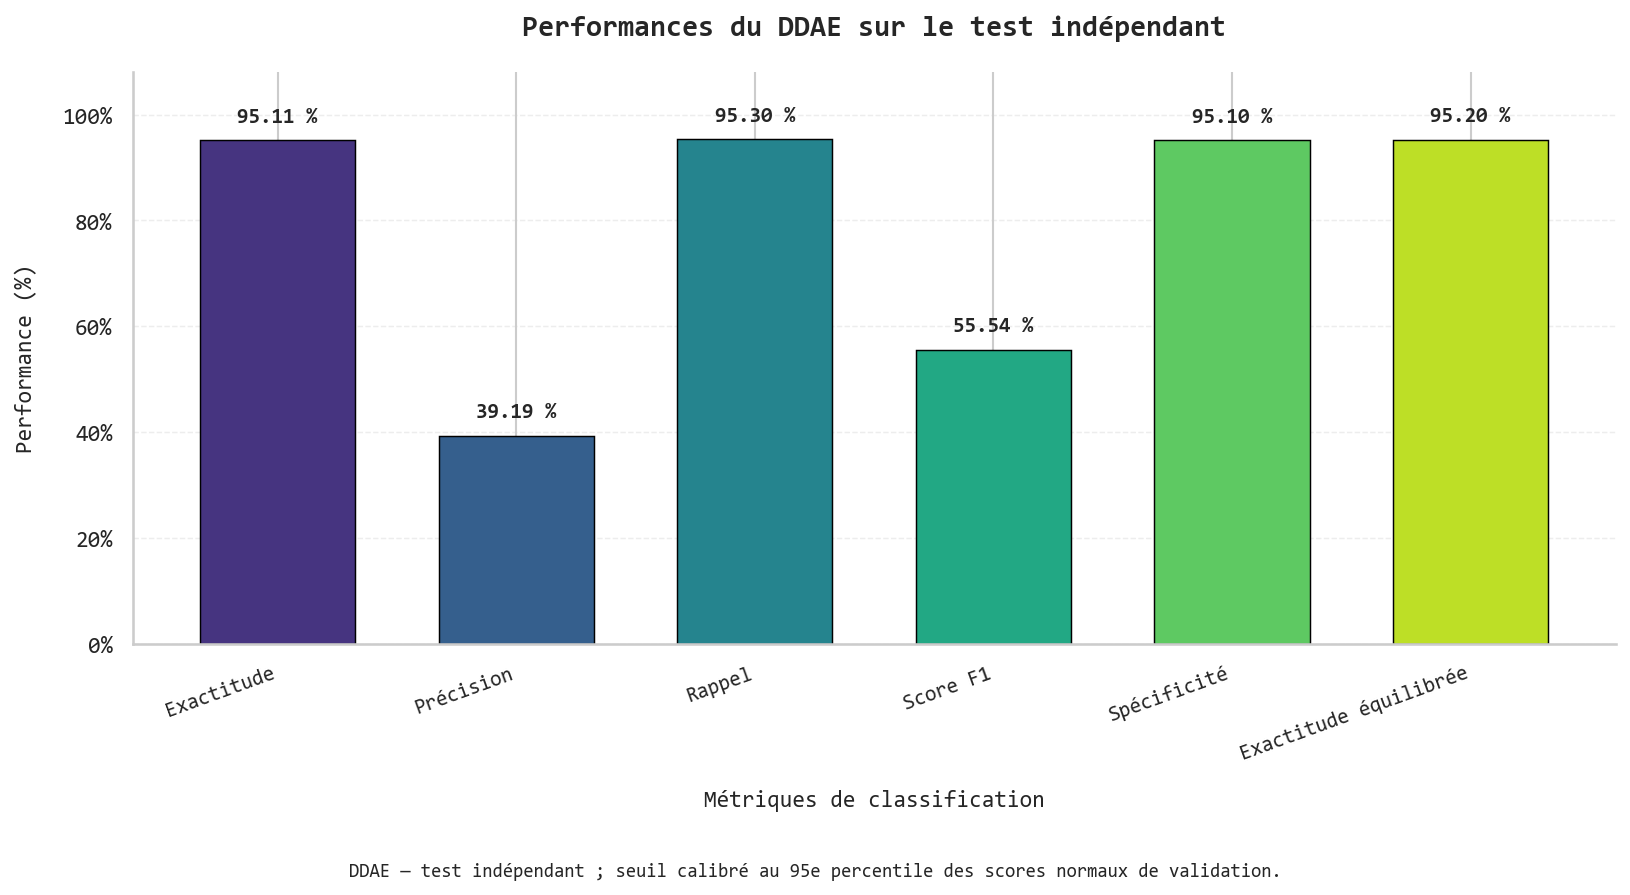

In [60]:

# ============================================================
# CELLULE 24 — GRAPHIQUE DES PERFORMANCES DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
# Evaluation : Test independant
#
# Objectif :
# Visualiser les principales metriques de classification.
#
# Aucune modification du modele, du test ou du seuil.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("METRICS_READY", False):
    raise RuntimeError(
        "Les metriques ne sont pas disponibles. "
        "Executer correctement la cellule 23."
    )

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "L'evaluation sur le test n'est pas terminee."
    )

required_objects = [
    "performance_metrics",
    "DDAE_METRICS",
    "THRESHOLD_DDAE",
    "FIXED_THRESHOLD",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR",
    "SCIENTIFIC_FONT"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Selection des metriques de classification
# ------------------------------------------------------------

METRICS_TO_PLOT = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Specificity",
    "Balanced Accuracy"
]

# Traduction scientifique en francais

METRIC_LABELS = {
    "Accuracy": "Exactitude",
    "Precision": "Précision",
    "Recall": "Rappel",
    "F1-score": "Score F1",
    "Specificity": "Spécificité",
    "Balanced Accuracy": "Exactitude équilibrée"
}

# ------------------------------------------------------------
# 3. Extraction des valeurs reelles
# ------------------------------------------------------------

metric_values = np.array(
    [
        DDAE_METRICS[metric]
        for metric in METRICS_TO_PLOT
    ],
    dtype=np.float64
)

if not np.isfinite(metric_values).all():
    raise ValueError(
        "Les metriques contiennent des valeurs non finies."
    )

if np.any(metric_values < 0) or np.any(
    metric_values > 1
):
    raise ValueError(
        "Les metriques doivent etre comprises entre 0 et 1."
    )

metric_percentages = metric_values * 100

metric_names_fr = [
    METRIC_LABELS[metric]
    for metric in METRICS_TO_PLOT
]

# ------------------------------------------------------------
# 4. Tableau des valeurs du graphique
# ------------------------------------------------------------

graph_metrics_table = pd.DataFrame({
    "Metrique": METRICS_TO_PLOT,
    "Libelle_francais": metric_names_fr,
    "Valeur": metric_values,
    "Valeur_pct": metric_percentages
})

print("\nMETRIQUES UTILISEES DANS LA FIGURE")

display(
    graph_metrics_table[
        ["Libelle_francais", "Valeur_pct"]
    ].style.format({
        "Valeur_pct": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 5. Controle de coherence avec la cellule 23
# ------------------------------------------------------------

reference_metrics = (
    performance_metrics
    .set_index("Metrique")["Score"]
)

for metric, value in zip(
    METRICS_TO_PLOT,
    metric_values
):

    if metric not in reference_metrics.index:
        raise ValueError(
            f"Metrique absente : {metric}"
        )

    assert np.isclose(
        value,
        reference_metrics.loc[metric],
        rtol=1e-12,
        atol=1e-12
    ), (
        f"Incoherence de valeur pour {metric}."
    )

assert np.isclose(
    FIXED_THRESHOLD,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)



# ------------------------------------------------------------
# 6. Configuration graphique scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

# Palette scientifique viridis

colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(METRICS_TO_PLOT)
    )
)

# ------------------------------------------------------------
# 7. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6),
    dpi=150
)

x_positions = np.arange(
    len(metric_names_fr)
)

bars = ax.bar(
    x_positions,
    metric_percentages,
    color=colors,
    edgecolor="black",
    linewidth=0.7,
    width=0.65
)

# ------------------------------------------------------------
# 8. Annotation des valeurs sur les barres
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    metric_percentages
):

    ax.annotate(
        f"{value:.2f} %",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        fontfamily=SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 9. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Performances du DDAE sur le test indépendant",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Métriques de classification",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_ylabel(
    "Performance (%)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=12
)

ax.set_xticks(
    x_positions
)

ax.set_xticklabels(
    metric_names_fr,
    rotation=20,
    ha="right",
    fontsize=10
)

# ------------------------------------------------------------
# 10. Configuration de l'axe Y
# ------------------------------------------------------------

ax.set_ylim(
    0,
    108
)

ax.set_yticks(
    np.arange(0, 101, 20)
)

ax.yaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=100,
        decimals=0
    )
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 11. Note methodologique
# ------------------------------------------------------------

figure_note = (
    "DDAE — test indépendant ; "
    "seuil calibré au 95e percentile "
    "des scores normaux de validation."
)

fig.text(
    0.5,
    0.015,
    figure_note,
    ha="center",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.06, 1, 1)
)

# ------------------------------------------------------------
# 12. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = (
    "performances_globales_DDAE_test_independant"
)

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 13. Export du tableau scientifique
# ------------------------------------------------------------

graph_metrics_path = (
    TABLES_DIR /
    "metriques_graphique_DDAE.csv"
)

graph_metrics_table.to_csv(
    graph_metrics_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Rapport de tracabilite
# ------------------------------------------------------------

figure_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "figure": FIGURE_NAME,
    "metriques": {
        name: float(value)
        for name, value in zip(
            METRICS_TO_PLOT,
            metric_values
        )
    },
    "seuil": float(FIXED_THRESHOLD),
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "police": SCIENTIFIC_FONT,
    "palette": "viridis",
    "axe_y": "pourcentage_0_100",
    "modele_modifie": False,
    "pretraitement_modifie": False,
    "seuil_modifie": False,
    "aucune_optimisation_sur_test": True
}

FIGURE_REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_graphique_performances_DDAE.json"
)

with open(
    FIGURE_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        figure_report,
        file,
        indent=4,
        ensure_ascii=False
    )



CONTROLES DE COHERENCE : VALIDES
Observations : 104871
Normaux : 101507
Attaques : 3364

RESULTATS ROC
ROC-AUC : 0.985124
Nombre de points ROC : 95514

POINT DE FONCTIONNEMENT
Seuil fixe : 0.0352576726
Taux de faux positifs : 4.9002 %
Taux de vrais positifs : 95.3032 %


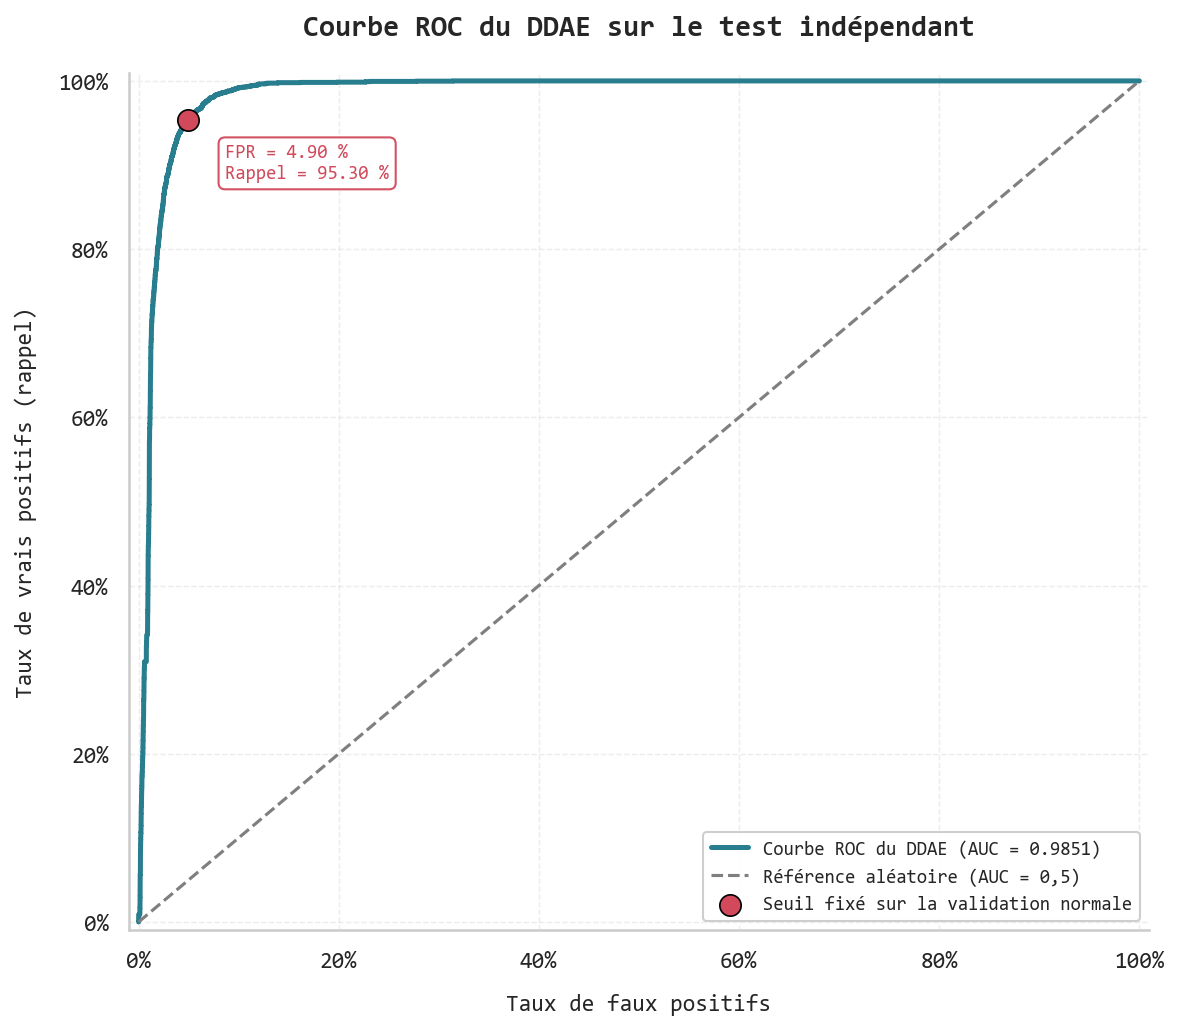

,Indicateur,Valeur
0,ROC-AUC,0.985124
1,FPR au seuil fixe,0.049002
2,TPR au seuil fixe,0.953032
3,Seuil de decision,0.035258
4,Nombre de points ROC,95514.000000


In [62]:

# ============================================================
# CELLULE 25 — COURBE ROC ET AIRE ROC-AUC DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation : test independant
# Score : MSE individuel
# Seuil de decision : 95e percentile
#                     de validation normale
#
# Aucun recalibrage du seuil sur le test.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    auc
)

# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("METRICS_READY", False):
    raise RuntimeError(
        "Les metriques globales sont absentes. "
        "Executer la cellule 23."
    )

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Les scores du test sont indisponibles."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "Le seuil n'est pas calibre."
    )

required_objects = [
    "mse_test",
    "y_test_array",
    "y_pred_test",
    "FIXED_THRESHOLD",
    "THRESHOLD_DDAE",
    "DDAE_METRICS",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR",
    "SCIENTIFIC_FONT"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Recuperation des scores et etiquettes
# ------------------------------------------------------------

y_true_roc = np.asarray(
    y_test_array,
    dtype=np.int8
)

scores_roc = np.asarray(
    mse_test,
    dtype=np.float64
)

predictions_roc = np.asarray(
    y_pred_test,
    dtype=np.int8
)

threshold_roc = float(
    FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. Controles de coherence
# ------------------------------------------------------------

assert y_true_roc.ndim == 1
assert scores_roc.ndim == 1

assert (
    len(y_true_roc)
    == len(scores_roc)
    == len(predictions_roc)
)

assert set(np.unique(y_true_roc)) == {0, 1}

assert np.isfinite(scores_roc).all()

assert np.all(scores_roc >= 0)

assert np.isclose(
    threshold_roc,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

assert np.array_equal(
    predictions_roc,
    (scores_roc > threshold_roc).astype(np.int8)
)

print("\nCONTROLES DE COHERENCE : VALIDES")

print("Observations :", len(y_true_roc))
print("Normaux :", int((y_true_roc == 0).sum()))
print("Attaques :", int((y_true_roc == 1).sum()))

# ------------------------------------------------------------
# 4. Calcul de la courbe ROC
# ------------------------------------------------------------

# Les scores continus sont utilises.
# Un score MSE eleve indique une anomalie
# potentiellement plus importante.

fpr_roc, tpr_roc, roc_thresholds = roc_curve(
    y_true_roc,
    scores_roc,
    pos_label=1,
    drop_intermediate=False
)

# ------------------------------------------------------------
# 5. Calcul de ROC-AUC
# ------------------------------------------------------------

ROC_AUC_VALUE = float(
    roc_auc_score(
        y_true_roc,
        scores_roc
    )
)

# Verification par integration trapezoidale

ROC_AUC_TRAPEZOID = float(
    auc(
        fpr_roc,
        tpr_roc
    )
)

assert np.isclose(
    ROC_AUC_VALUE,
    ROC_AUC_TRAPEZOID,
    rtol=1e-10,
    atol=1e-10
)

# Coherence avec la cellule 23

assert np.isclose(
    ROC_AUC_VALUE,
    DDAE_METRICS["ROC-AUC"],
    rtol=1e-10,
    atol=1e-10
), (
    "Le ROC-AUC differe de la cellule 23."
)

print("\nRESULTATS ROC")

print(
    "ROC-AUC :",
    f"{ROC_AUC_VALUE:.6f}"
)

print(
    "Nombre de points ROC :",
    len(fpr_roc)
)

# ------------------------------------------------------------
# 6. Point du seuil de decision fixe
# ------------------------------------------------------------

# IMPORTANT :
# Le point de fonctionnement est calcule
# avec les predictions de la cellule 20.
#
# Aucun nouveau seuil n'est recherche.

normal_mask = (
    y_true_roc == 0
)

attack_mask = (
    y_true_roc == 1
)

FPR_OPERATING = float(
    np.mean(
        predictions_roc[normal_mask] == 1
    )
)

TPR_OPERATING = float(
    np.mean(
        predictions_roc[attack_mask] == 1
    )
)

# Coherence avec la matrice de confusion

assert np.isclose(
    FPR_OPERATING,
    FPR,
    rtol=1e-12,
    atol=1e-12
)

assert np.isclose(
    TPR_OPERATING,
    TPR,
    rtol=1e-12,
    atol=1e-12
)

print("\nPOINT DE FONCTIONNEMENT")

print(
    "Seuil fixe :",
    f"{threshold_roc:.10f}"
)

print(
    "Taux de faux positifs :",
    f"{FPR_OPERATING * 100:.4f} %"
)

print(
    "Taux de vrais positifs :",
    f"{TPR_OPERATING * 100:.4f} %"
)

# ------------------------------------------------------------
# 7. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid"
)

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_ROC = "#287D8E"
COLOR_REFERENCE = "#7F7F7F"
COLOR_OPERATING = "#D1495B"

# ------------------------------------------------------------
# 8. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7),
    dpi=150
)

# Courbe ROC

ax.plot(
    fpr_roc,
    tpr_roc,
    color=COLOR_ROC,
    linewidth=2.4,
    label=(
        f"Courbe ROC du DDAE "
        f"(AUC = {ROC_AUC_VALUE:.4f})"
    )
)

# Diagonale de reference

ax.plot(
    [0, 1],
    [0, 1],
    color=COLOR_REFERENCE,
    linestyle="--",
    linewidth=1.5,
    label="Référence aléatoire (AUC = 0,5)"
)

# ------------------------------------------------------------
# 9. Point de fonctionnement du seuil fixe
# ------------------------------------------------------------

ax.scatter(
    FPR_OPERATING,
    TPR_OPERATING,
    s=105,
    color=COLOR_OPERATING,
    edgecolor="black",
    linewidth=0.8,
    marker="o",
    zorder=6,
    label="Seuil fixé sur la validation normale"
)

ax.annotate(
    (
        f"FPR = {FPR_OPERATING * 100:.2f} %\n"
        f"Rappel = {TPR_OPERATING * 100:.2f} %"
    ),
    xy=(
        FPR_OPERATING,
        TPR_OPERATING
    ),
    xytext=(18, -28),
    textcoords="offset points",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT,
    color=COLOR_OPERATING,
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": "white",
        "edgecolor": COLOR_OPERATING,
        "alpha": 0.95
    }
)

# ------------------------------------------------------------
# 10. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Courbe ROC du DDAE sur le test indépendant",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Taux de faux positifs",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=10
)

ax.set_ylabel(
    "Taux de vrais positifs (rappel)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=10
)

# ------------------------------------------------------------
# 11. Configuration des axes
# ------------------------------------------------------------

ax.set_xlim(
    -0.01,
    1.01
)

ax.set_ylim(
    -0.01,
    1.01
)

ax.set_xticks(
    np.linspace(0, 1, 6)
)

ax.set_yticks(
    np.linspace(0, 1, 6)
)

ax.xaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.yaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

ax.legend(
    loc="lower right",
    fontsize=9,
    frameon=True,
    framealpha=0.95
)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 12. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = "courbe_ROC_DDAE_test_independant"

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 13. Export des points ROC
# ------------------------------------------------------------

roc_points_table = pd.DataFrame({
    "Taux_faux_positifs": fpr_roc,
    "Taux_vrais_positifs": tpr_roc,
    "Seuil_ROC_exploratoire": roc_thresholds
})

ROC_POINTS_PATH = (
    TABLES_DIR / "points_courbe_ROC_DDAE.csv"
)

roc_points_table.to_csv(
    ROC_POINTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. Tableau des indicateurs
# ------------------------------------------------------------

roc_summary = pd.DataFrame({
    "Indicateur": [
        "ROC-AUC",
        "FPR au seuil fixe",
        "TPR au seuil fixe",
        "Seuil de decision",
        "Nombre de points ROC"
    ],
    "Valeur": [
        ROC_AUC_VALUE,
        FPR_OPERATING,
        TPR_OPERATING,
        threshold_roc,
        float(len(fpr_roc))
    ]
})

display(roc_summary)

roc_summary.to_csv(
    TABLES_DIR / "resume_ROC_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. Rapport de tracabilite
# ------------------------------------------------------------

roc_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "score": "MSE_individuel",
    "orientation": "score_eleve_plus_anormal",
    "roc_auc": ROC_AUC_VALUE,
    "roc_auc_trapezoidal": ROC_AUC_TRAPEZOID,
    "nombre_points_ROC": int(len(fpr_roc)),
    "seuil_operationnel": threshold_roc,
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "fpr_seuil_fixe": FPR_OPERATING,
    "tpr_seuil_fixe": TPR_OPERATING,
    "seuil_recalibre": False,
    "modele_modifie": False,
    "pretraitement_modifie": False,
    "optimisation_sur_test": False
}

ROC_REPORT_PATH = (
    ARTIFACTS_DIR / "rapport_ROC_DDAE.json"
)

with open(
    ROC_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        roc_report,
        file,
        indent=4,
        ensure_ascii=False
    )


CONTROLES DE COHERENCE : VALIDES

POPULATION DU TEST
Observations : 104,871
Trafic normal : 101,507
Attaques : 3,364
Proportion d'attaques : 3.2078 %

INDICATEURS PRECISION-RAPPEL
Average Precision : 0.574567
Aire PR trapezoidale : 0.573484

POINT DE FONCTIONNEMENT
Seuil fixe : 0.0352576726
Precision au seuil fixe : 39.1932 %
Rappel au seuil fixe : 95.3032 %


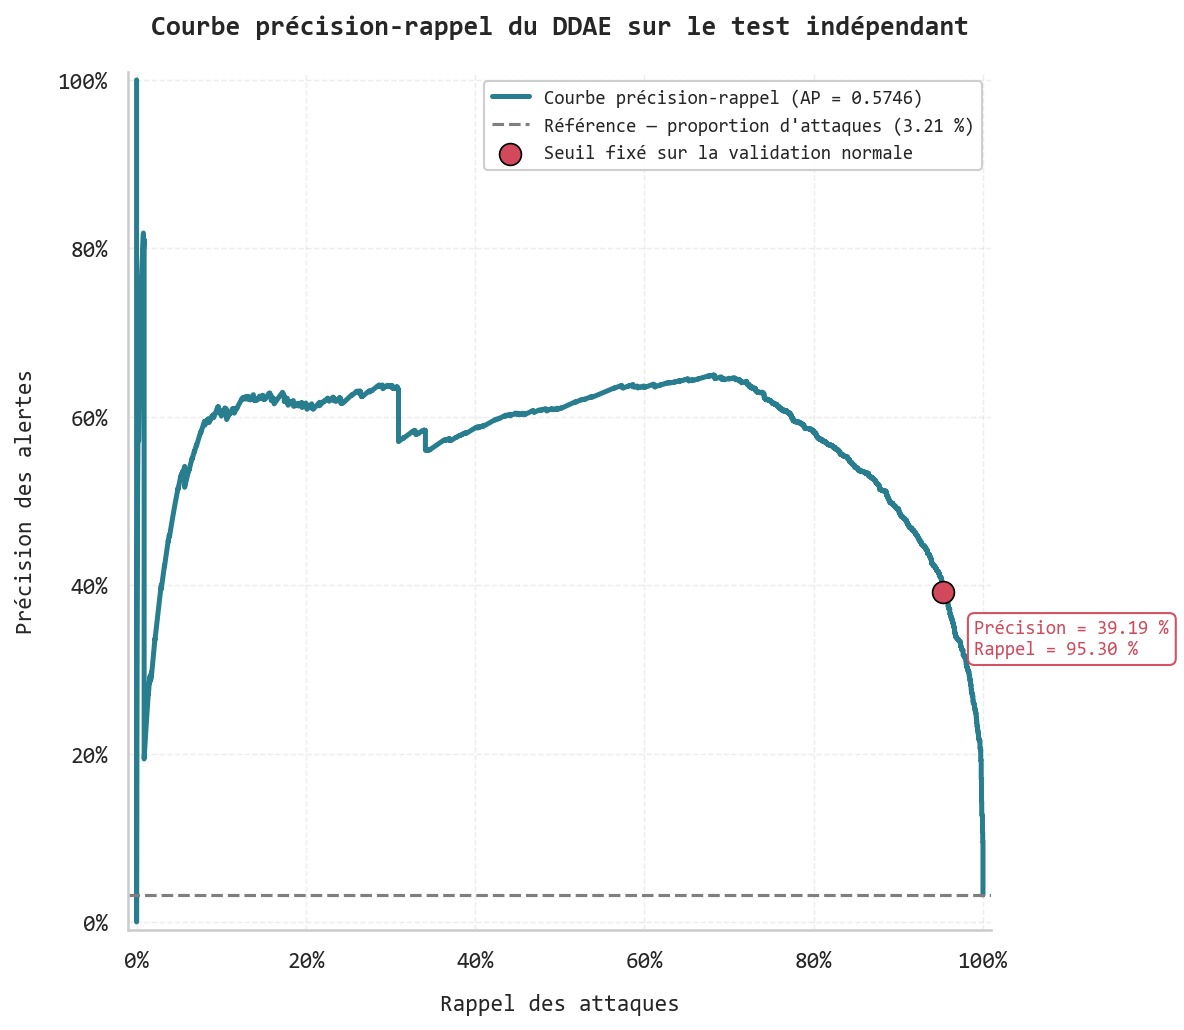


RESUME PRECISION-RAPPEL


,Indicateur,Valeur
0,Average Precision,0.574567
1,Aire PR trapezoidale,0.573484
2,Precision au seuil fixe,0.391932
3,Rappel au seuil fixe,0.953032
4,Proportion d'attaques,0.032078
5,Seuil operationnel,0.035258
6,Nombre de points PR,95514.000000



COURBE PRECISION-RAPPEL DU DDAE TERMINEE
Average Precision : 0.574567
Precision au seuil fixe : 39.1932 %
Rappel au seuil fixe : 95.3032 %


In [64]:

# ============================================================
# CELLULE 26 — COURBE PRECISION-RAPPEL DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation : test independant
# Score : MSE individuel
# Seuil : 95e percentile de validation normale
#
# Aucun recalibrage ni optimisation sur le test.
# ============================================================

import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    auc
)


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("METRICS_READY", False):
    raise RuntimeError(
        "Les metriques globales sont absentes. "
        "Executer la cellule 23."
    )

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Les scores du test ne sont pas disponibles."
    )

if not globals().get("CALIBRATION_COMPLETED", False):
    raise RuntimeError(
        "Le seuil de decision n'est pas calibre."
    )

required_objects = [
    "mse_test",
    "y_test_array",
    "y_pred_test",
    "FIXED_THRESHOLD",
    "THRESHOLD_DDAE",
    "DDAE_METRICS",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR",
    "SCIENTIFIC_FONT"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Recuperation des donnees du test
# ------------------------------------------------------------

y_true_pr = np.asarray(
    y_test_array,
    dtype=np.int8
)

scores_pr = np.asarray(
    mse_test,
    dtype=np.float64
)

predictions_pr = np.asarray(
    y_pred_test,
    dtype=np.int8
)

threshold_pr = float(
    FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. Controles de coherence
# ------------------------------------------------------------

assert y_true_pr.ndim == 1
assert scores_pr.ndim == 1
assert predictions_pr.ndim == 1

assert (
    len(y_true_pr)
    == len(scores_pr)
    == len(predictions_pr)
)

if set(np.unique(y_true_pr)) != {0, 1}:
    raise ValueError(
        "Les deux classes doivent etre presentes."
    )

if not np.isfinite(scores_pr).all():
    raise ValueError(
        "Des scores MSE non finis ont ete detectes."
    )

if np.any(scores_pr < 0):
    raise ValueError(
        "Les scores MSE doivent etre positifs ou nuls."
    )

assert np.isclose(
    threshold_pr,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

assert np.array_equal(
    predictions_pr,
    (scores_pr > threshold_pr).astype(np.int8)
)

print("\nCONTROLES DE COHERENCE : VALIDES")

# ------------------------------------------------------------
# 4. Distribution des classes du test
# ------------------------------------------------------------

N_TEST = len(y_true_pr)

N_NORMAL = int(
    np.sum(y_true_pr == 0)
)

N_ATTACK = int(
    np.sum(y_true_pr == 1)
)

ATTACK_PREVALENCE = (
    N_ATTACK / N_TEST
)

print("\nPOPULATION DU TEST")

print("Observations :", f"{N_TEST:,}")
print("Trafic normal :", f"{N_NORMAL:,}")
print("Attaques :", f"{N_ATTACK:,}")

print(
    "Proportion d'attaques :",
    f"{ATTACK_PREVALENCE * 100:.4f} %"
)

# ------------------------------------------------------------
# 5. Calcul de la courbe precision-rappel
# ------------------------------------------------------------

# La courbe est calculee sur les scores continus.
# Score eleve = observation plus anormale.
#
# Les seuils explores par sklearn ne servent
# PAS a modifier le seuil operationnel du DDAE.

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_true_pr,
        scores_pr,
        pos_label=1
    )
)

assert (
    len(precision_curve)
    == len(recall_curve)
)

assert (
    len(pr_thresholds) + 1
    == len(precision_curve)
)

# ------------------------------------------------------------
# 6. Calcul de l'Average Precision
# ------------------------------------------------------------

AP_VALUE = float(
    average_precision_score(
        y_true_pr,
        scores_pr
    )
)

# Aire trapezoidale fournie uniquement
# comme information complementaire.
#
# Elle n'est pas identique par definition
# a l'Average Precision de sklearn.

PR_AUC_TRAPEZOID = float(
    auc(
        recall_curve,
        precision_curve
    )
)

# Controle avec la cellule 23

assert np.isclose(
    AP_VALUE,
    DDAE_METRICS["Average Precision"],
    rtol=1e-10,
    atol=1e-10
), (
    "L'Average Precision differe de la cellule 23."
)

print("\nINDICATEURS PRECISION-RAPPEL")

print(
    "Average Precision :",
    f"{AP_VALUE:.6f}"
)

print(
    "Aire PR trapezoidale :",
    f"{PR_AUC_TRAPEZOID:.6f}"
)

# ------------------------------------------------------------
# 7. Point de fonctionnement du seuil fixe
# ------------------------------------------------------------

PRECISION_OPERATING = float(
    precision_score(
        y_true_pr,
        predictions_pr,
        zero_division=0
    )
)

RECALL_OPERATING = float(
    recall_score(
        y_true_pr,
        predictions_pr,
        zero_division=0
    )
)

# Verification avec les resultats deja calcules

assert np.isclose(
    PRECISION_OPERATING,
    DDAE_METRICS["Precision"],
    rtol=1e-12,
    atol=1e-12
)

assert np.isclose(
    RECALL_OPERATING,
    DDAE_METRICS["Recall"],
    rtol=1e-12,
    atol=1e-12
)

print("\nPOINT DE FONCTIONNEMENT")

print(
    "Seuil fixe :",
    f"{threshold_pr:.10f}"
)

print(
    "Precision au seuil fixe :",
    f"{PRECISION_OPERATING * 100:.4f} %"
)

print(
    "Rappel au seuil fixe :",
    f"{RECALL_OPERATING * 100:.4f} %"
)

# ------------------------------------------------------------
# 8. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid"
)

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_PR = "#287D8E"
COLOR_REFERENCE = "#7F7F7F"
COLOR_OPERATING = "#D1495B"

# ------------------------------------------------------------
# 9. Creation de la figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 7),
    dpi=150
)

# Courbe precision-rappel

ax.plot(
    recall_curve,
    precision_curve,
    color=COLOR_PR,
    linewidth=2.4,
    label=(
        f"Courbe précision-rappel "
        f"(AP = {AP_VALUE:.4f})"
    )
)

# ------------------------------------------------------------
# 10. Ligne de reference
# ------------------------------------------------------------

# Reference correspondant a la prevalence
# des attaques dans l'ensemble de test.

ax.axhline(
    y=ATTACK_PREVALENCE,
    color=COLOR_REFERENCE,
    linestyle="--",
    linewidth=1.5,
    label=(
        "Référence — proportion d'attaques "
        f"({ATTACK_PREVALENCE * 100:.2f} %)"
    )
)

# ------------------------------------------------------------
# 11. Point du seuil operationnel
# ------------------------------------------------------------

ax.scatter(
    RECALL_OPERATING,
    PRECISION_OPERATING,
    s=110,
    color=COLOR_OPERATING,
    edgecolor="black",
    linewidth=0.8,
    marker="o",
    zorder=6,
    label="Seuil fixé sur la validation normale"
)

ax.annotate(
    (
        f"Précision = {PRECISION_OPERATING * 100:.2f} %\n"
        f"Rappel = {RECALL_OPERATING * 100:.2f} %"
    ),
    xy=(
        RECALL_OPERATING,
        PRECISION_OPERATING
    ),
    xytext=(15, -30),
    textcoords="offset points",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT,
    color=COLOR_OPERATING,
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": "white",
        "edgecolor": COLOR_OPERATING,
        "alpha": 0.95
    }
)

# ------------------------------------------------------------
# 12. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Courbe précision-rappel du DDAE sur le test indépendant",
    fontsize=13,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Rappel des attaques",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=10
)

ax.set_ylabel(
    "Précision des alertes",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT,
    labelpad=10
)

# ------------------------------------------------------------
# 13. Configuration des axes
# ------------------------------------------------------------

ax.set_xlim(
    -0.01,
    1.01
)

ax.set_ylim(
    -0.01,
    1.01
)

ax.set_xticks(
    np.linspace(0, 1, 6)
)

ax.set_yticks(
    np.linspace(0, 1, 6)
)

ax.xaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.yaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

ax.legend(
    loc="best",
    fontsize=9,
    frameon=True,
    framealpha=0.95
)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 14. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = (
    "courbe_precision_rappel_DDAE_test_independant"
)

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 15. Export des points precision-rappel
# ------------------------------------------------------------

# Le dernier point de la courbe n'a pas
# de seuil associe dans sklearn.
# Nous enregistrons NaN pour ce point.

thresholds_extended = np.concatenate([
    pr_thresholds,
    [np.nan]
])

pr_points_table = pd.DataFrame({
    "Rappel": recall_curve,
    "Precision": precision_curve,
    "Seuil_exploratoire": thresholds_extended
})

PR_POINTS_PATH = (
    TABLES_DIR / "points_precision_rappel_DDAE.csv"
)

pr_points_table.to_csv(
    PR_POINTS_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 16. Tableau des indicateurs
# ------------------------------------------------------------

pr_summary = pd.DataFrame({
    "Indicateur": [
        "Average Precision",
        "Aire PR trapezoidale",
        "Precision au seuil fixe",
        "Rappel au seuil fixe",
        "Proportion d'attaques",
        "Seuil operationnel",
        "Nombre de points PR"
    ],
    "Valeur": [
        AP_VALUE,
        PR_AUC_TRAPEZOID,
        PRECISION_OPERATING,
        RECALL_OPERATING,
        ATTACK_PREVALENCE,
        threshold_pr,
        float(len(precision_curve))
    ]
})

print("\nRESUME PRECISION-RAPPEL")

display(pr_summary)

pr_summary.to_csv(
    TABLES_DIR / "resume_precision_rappel_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. Rapport de tracabilite
# ------------------------------------------------------------

pr_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "score": "MSE_individuel",
    "orientation": "score_eleve_plus_anormal",
    "average_precision": AP_VALUE,
    "aire_PR_trapezoidale": PR_AUC_TRAPEZOID,
    "nombre_points_PR": int(
        len(precision_curve)
    ),
    "proportion_attaques": ATTACK_PREVALENCE,
    "seuil_operationnel": threshold_pr,
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "precision_au_seuil_fixe": PRECISION_OPERATING,
    "rappel_au_seuil_fixe": RECALL_OPERATING,
    "seuil_recalibre": False,
    "modele_modifie": False,
    "pretraitement_modifie": False,
    "optimisation_sur_test": False
}

PR_REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_precision_rappel_DDAE.json"
)

with open(
    PR_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        pr_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 18. Verification finale
# ------------------------------------------------------------

assert 0 <= AP_VALUE <= 1
assert 0 <= PR_AUC_TRAPEZOID <= 1
assert 0 <= PRECISION_OPERATING <= 1
assert 0 <= RECALL_OPERATING <= 1

assert np.isclose(
    threshold_pr,
    THRESHOLD_DDAE
)

PR_FIGURE_READY = True

print("\n" + "=" * 70)
print("COURBE PRECISION-RAPPEL DU DDAE TERMINEE")
print("=" * 70)

print(
    "Average Precision :",
    f"{AP_VALUE:.6f}"
)

print(
    "Precision au seuil fixe :",
    f"{PRECISION_OPERATING * 100:.4f} %"
)

print(
    "Rappel au seuil fixe :",
    f"{RECALL_OPERATING * 100:.4f} %"
)


EFFECTIFS DES GROUPES
Vrais négatifs : 96,533
Faux positifs : 4,974
Faux négatifs : 158
Vrais positifs : 3,206

STATISTIQUES DES QUATRE GROUPES


,Groupe,Effectif,Proportion_test_pct,MSE_min,MSE_moyen,MSE_median,MSE_P95,MSE_max,Marge_mediane
0,Vrais négatifs,96533,92.049280,0.000078,0.006867,0.004494,0.020644,0.035250,-0.030764
1,Faux positifs,4974,4.742970,0.035263,0.453196,0.056516,0.351217,369.454985,0.021258
2,Faux négatifs,158,0.150661,0.008358,0.026462,0.027664,0.034907,0.035242,-0.007594
3,Vrais positifs,3206,3.057089,0.035439,0.346789,0.135052,0.629013,95.883841,0.099794



OBSERVATIONS MAL CLASSEES
Total : 5,132


,ID_observation,Classe_reelle,Classe_predite,Score_MSE,Seuil_DDAE,Marge_score,Type_classification,Categorie_attaque
3,7,0,1,2.619276,0.035258,2.584019,Faux positif,<NA>
4,10,0,1,2.619276,0.035258,2.584019,Faux positif,<NA>
5,11,0,1,2.619276,0.035258,2.584019,Faux positif,<NA>
6,12,0,1,2.619276,0.035258,2.584019,Faux positif,<NA>
18,119,0,1,0.160444,0.035258,0.125186,Faux positif,<NA>
19,121,0,1,0.160444,0.035258,0.125186,Faux positif,<NA>
42,263,0,1,0.094437,0.035258,0.059180,Faux positif,<NA>
43,264,0,1,0.136215,0.035258,0.100957,Faux positif,<NA>
45,278,0,1,0.302446,0.035258,0.267188,Faux positif,<NA>
46,281,0,1,0.118803,0.035258,0.083546,Faux positif,<NA>



SYNTHESE DES ERREURS


,Type,Effectif
0,Faux positifs,4974
1,Faux négatifs,158


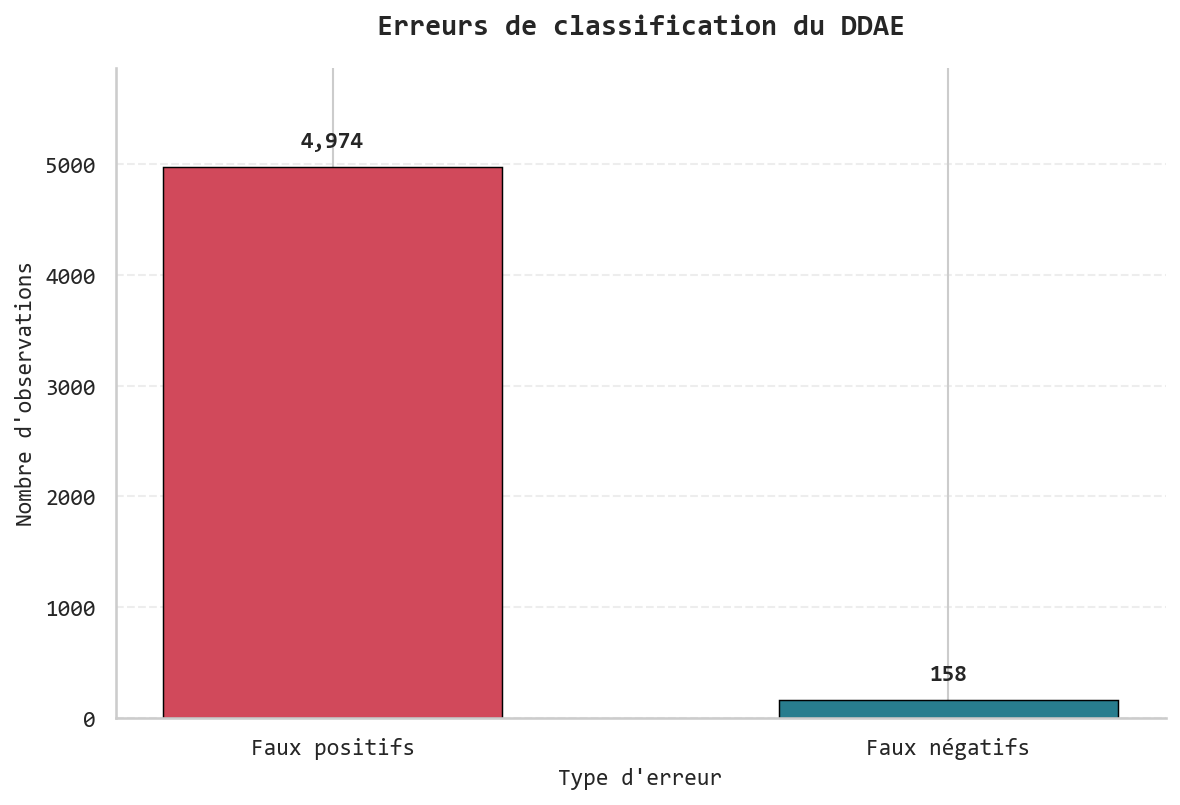

In [66]:

# ============================================================
# CELLULE 27 — ANALYSE DES ERREURS DE CLASSIFICATION DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Analyser les vrais negatifs, faux positifs,
# faux negatifs et vrais positifs.
#
# Evaluation descriptive sur test independant.
# Aucun nouvel entrainement ou recalibrage.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("METRICS_READY", False):
    raise RuntimeError(
        "Executer et valider la cellule 23."
    )

if not globals().get("CONFUSION_MATRIX_READY", False):
    raise RuntimeError(
        "Executer et valider la cellule 22."
    )

required_objects = [
    "y_test_array",
    "y_pred_test",
    "mse_test",
    "ids_test",
    "FIXED_THRESHOLD",
    "THRESHOLD_DDAE",
    "TN", "FP", "FN", "TP",
    "SCIENTIFIC_FONT",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Objets manquants : {missing}"
    )

# ------------------------------------------------------------
# 2. Recuperation des donnees
# ------------------------------------------------------------

y_true_errors = np.asarray(
    y_test_array,
    dtype=np.int8
)

y_pred_errors = np.asarray(
    y_pred_test,
    dtype=np.int8
)

scores_errors = np.asarray(
    mse_test,
    dtype=np.float64
)

ids_errors = np.asarray(
    ids_test,
    dtype=np.int64
)

threshold_errors = float(
    FIXED_THRESHOLD
)

# ------------------------------------------------------------
# 3. Controles de coherence
# ------------------------------------------------------------

n_samples = len(y_true_errors)

assert (
    len(y_pred_errors)
    == len(scores_errors)
    == len(ids_errors)
    == n_samples
)

assert set(np.unique(y_true_errors)) == {0, 1}

assert set(np.unique(y_pred_errors)).issubset({0, 1})

assert np.isfinite(scores_errors).all()

assert np.isclose(
    threshold_errors,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

assert np.array_equal(
    y_pred_errors,
    (scores_errors > threshold_errors).astype(np.int8)
)

# ------------------------------------------------------------
# 4. Identification des quatre groupes
# ------------------------------------------------------------

mask_tn = (
    (y_true_errors == 0)
    & (y_pred_errors == 0)
)

mask_fp = (
    (y_true_errors == 0)
    & (y_pred_errors == 1)
)

mask_fn = (
    (y_true_errors == 1)
    & (y_pred_errors == 0)
)

mask_tp = (
    (y_true_errors == 1)
    & (y_pred_errors == 1)
)

groups = {
    "Vrais négatifs": mask_tn,
    "Faux positifs": mask_fp,
    "Faux négatifs": mask_fn,
    "Vrais positifs": mask_tp
}

# ------------------------------------------------------------
# 5. Verification des effectifs
# ------------------------------------------------------------

counts = {
    name: int(mask.sum())
    for name, mask in groups.items()
}

assert counts["Vrais négatifs"] == TN
assert counts["Faux positifs"] == FP
assert counts["Faux négatifs"] == FN
assert counts["Vrais positifs"] == TP

assert sum(counts.values()) == n_samples

print("\nEFFECTIFS DES GROUPES")

for name, count in counts.items():
    print(f"{name} : {count:,}")

# ------------------------------------------------------------
# 6. Marges par rapport au seuil
# ------------------------------------------------------------

# Marge positive :
# score superieur au seuil.
#
# Marge negative :
# score inferieur au seuil.
#
# Aucune transformation des scores utilises
# pour les decisions operationnelles.

score_margins = (
    scores_errors - threshold_errors
)

# ------------------------------------------------------------
# 7. Statistiques par groupe
# ------------------------------------------------------------

statistics_rows = []

for group_name, mask in groups.items():

    group_scores = scores_errors[mask]
    group_margins = score_margins[mask]

    row = {
        "Groupe": group_name,
        "Effectif": int(len(group_scores)),
        "Proportion_test_pct": (
            100 * len(group_scores) / n_samples
        ),
        "MSE_min": np.nan,
        "MSE_moyen": np.nan,
        "MSE_median": np.nan,
        "MSE_P95": np.nan,
        "MSE_max": np.nan,
        "Marge_mediane": np.nan
    }

    if len(group_scores) > 0:

        row.update({
            "MSE_min": float(
                np.min(group_scores)
            ),
            "MSE_moyen": float(
                np.mean(group_scores)
            ),
            "MSE_median": float(
                np.median(group_scores)
            ),
            "MSE_P95": float(
                np.percentile(group_scores, 95)
            ),
            "MSE_max": float(
                np.max(group_scores)
            ),
            "Marge_mediane": float(
                np.median(group_margins)
            )
        })

    statistics_rows.append(row)

error_statistics = pd.DataFrame(
    statistics_rows
)

print("\nSTATISTIQUES DES QUATRE GROUPES")

display(error_statistics)

# ------------------------------------------------------------
# 8. Tableau individuel des erreurs
# ------------------------------------------------------------

error_type = np.select(
    [
        mask_tn,
        mask_fp,
        mask_fn,
        mask_tp
    ],
    [
        "Vrai negatif",
        "Faux positif",
        "Faux negatif",
        "Vrai positif"
    ],
    default="Indetermine"
)

error_details = pd.DataFrame({
    "ID_observation": ids_errors,
    "Classe_reelle": y_true_errors,
    "Classe_predite": y_pred_errors,
    "Score_MSE": scores_errors,
    "Seuil_DDAE": threshold_errors,
    "Marge_score": score_margins,
    "Type_classification": error_type
})

if "attack_metadata" in globals():

    error_details["Categorie_attaque"] = (
        attack_metadata.iloc[ids_errors]
        .astype(str)
        .to_numpy()
    )

# ------------------------------------------------------------
# 9. Extraction des observations mal classees
# ------------------------------------------------------------

misclassified_mask = (
    y_true_errors != y_pred_errors
)

misclassified_table = (
    error_details.loc[misclassified_mask]
    .copy()
)

print("\nOBSERVATIONS MAL CLASSEES")

print(
    "Total :",
    f"{len(misclassified_table):,}"
)

display(
    misclassified_table.head(15)
)

# ------------------------------------------------------------
# 10. Comptage des erreurs
# ------------------------------------------------------------

error_count_table = pd.DataFrame({
    "Type": [
        "Faux positifs",
        "Faux négatifs"
    ],
    "Effectif": [
        int(FP),
        int(FN)
    ]
})

print("\nSYNTHESE DES ERREURS")

display(error_count_table)

# ------------------------------------------------------------
# 11. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_FP = "#D1495B"
COLOR_FN = "#287D8E"

# ------------------------------------------------------------
# 12. Graphique des erreurs
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5.5),
    dpi=150
)

bars = ax.bar(
    error_count_table["Type"],
    error_count_table["Effectif"],
    color=[
        COLOR_FP,
        COLOR_FN
    ],
    width=0.55,
    edgecolor="black",
    linewidth=0.7
)

# ------------------------------------------------------------
# 13. Annotations des effectifs
# ------------------------------------------------------------

max_count = int(
    error_count_table["Effectif"].max()
)

for bar, value in zip(
    bars,
    error_count_table["Effectif"]
):

    ax.annotate(
        f"{value:,}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        fontfamily=SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 14. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Erreurs de classification du DDAE",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax.set_xlabel(
    "Type d'erreur",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Nombre d'observations",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylim(
    0,
    max(1, max_count) * 1.18
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 15. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = "erreurs_classification_DDAE"

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 16. Export des tableaux
# ------------------------------------------------------------

error_statistics.to_csv(
    TABLES_DIR / "statistiques_erreurs_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

error_count_table.to_csv(
    TABLES_DIR / "effectifs_erreurs_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

misclassified_table.to_csv(
    TABLES_DIR / "observations_mal_classees_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. Rapport de tracabilite
# ------------------------------------------------------------

error_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "observations": int(n_samples),
    "TN": int(TN),
    "FP": int(FP),
    "FN": int(FN),
    "TP": int(TP),
    "total_erreurs": int(
        FP + FN
    ),
    "taux_erreur_global_pct": float(
        100 * (FP + FN) / n_samples
    ),
    "taux_fausses_alertes_pct": float(
        100 * FP / (TN + FP)
    ),
    "taux_attaques_manquees_pct": float(
        100 * FN / (FN + TP)
    ),
    "seuil": float(threshold_errors),
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "modele_modifie": False,
    "seuil_modifie": False,
    "analyse": "descriptive_post_evaluation",
    "optimisation_sur_test": False
}

ERROR_REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_erreurs_classification_DDAE.json"
)

with open(
    ERROR_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        error_report,
        file,
        indent=4,
        ensure_ascii=False
    )




PERFORMANCES PAR CATEGORIE


,Categorie_attaque,Nombre_attaques,Attaques_detectees,MSE_moyen,MSE_median,Attaques_manquees,Taux_detection_pct,Taux_non_detection_pct
0,Worms,3,2,0.197225,0.051585,1,66.67 %,33.33 %
1,Reconnaissance,279,243,0.103691,0.060203,36,87.10 %,12.90 %
2,Fuzzers,735,641,0.151398,0.073800,94,87.21 %,12.79 %
3,Exploits,772,752,0.855827,0.197953,20,97.41 %,2.59 %
4,Shellcode,44,43,0.118384,0.111133,1,97.73 %,2.27 %
5,DoS,172,169,0.414719,0.139997,3,98.26 %,1.74 %
6,Generic,1211,1208,0.174920,0.139995,3,99.75 %,0.25 %
7,Analysis,72,72,0.183232,0.138374,0,100.00 %,0.00 %
8,Backdoors,76,76,0.170127,0.139997,0,100.00 %,0.00 %


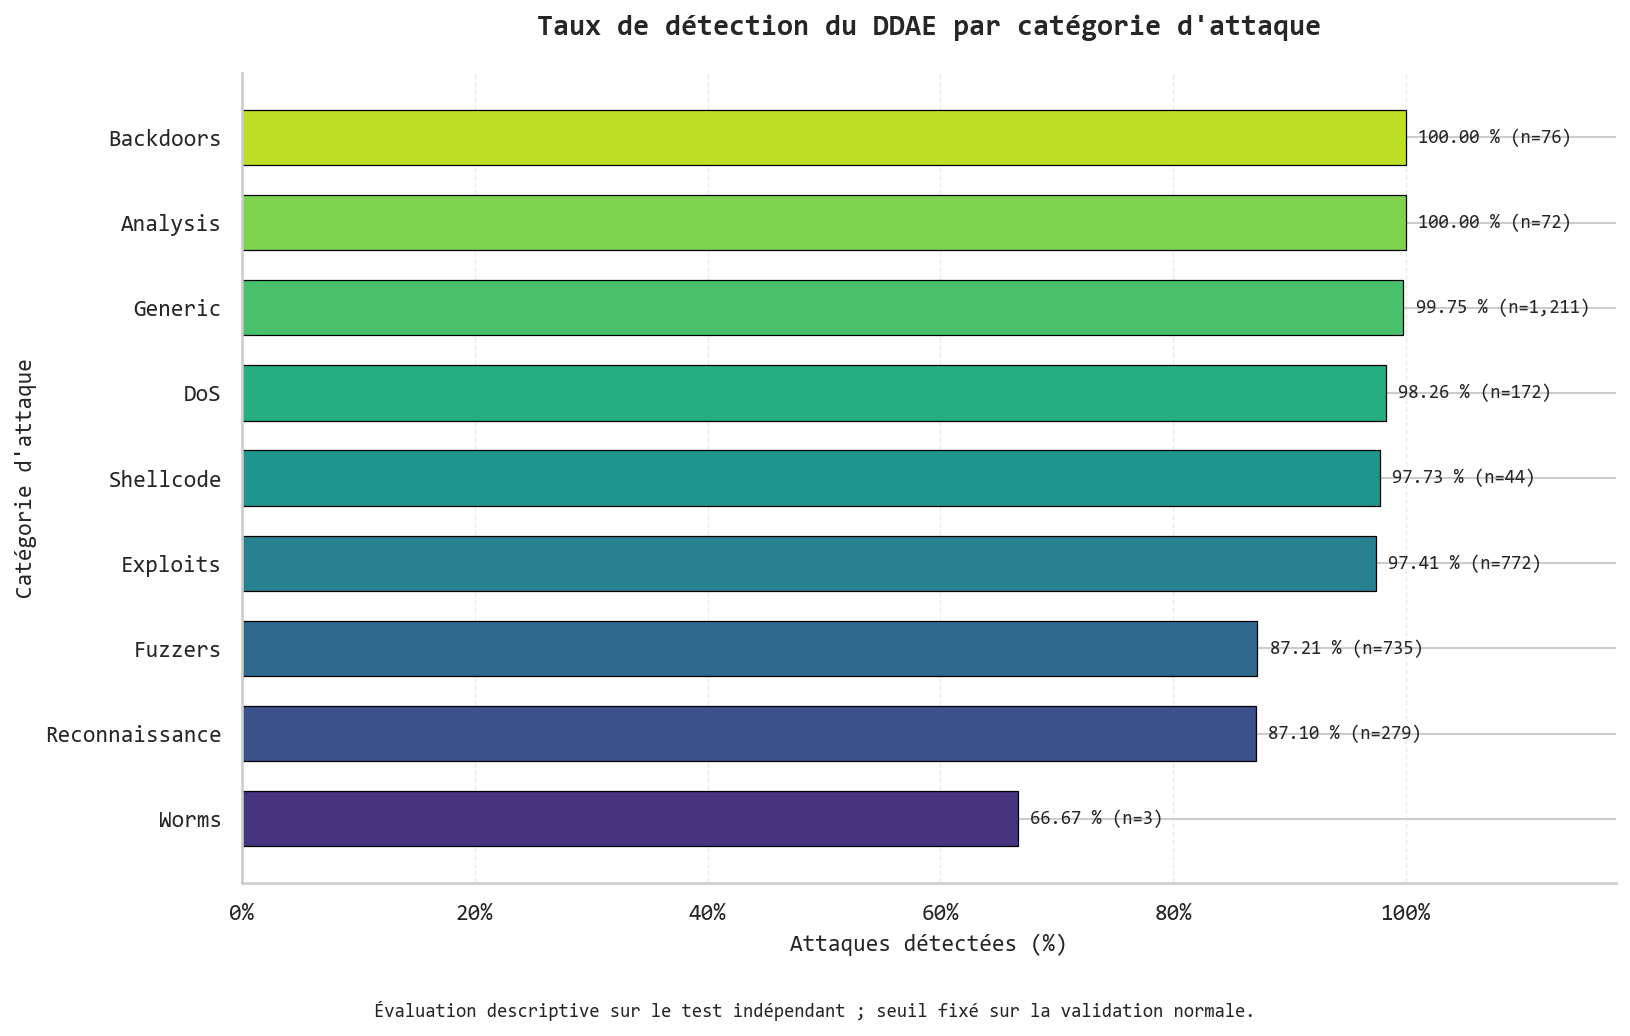

In [71]:

# ============================================================
# CELLULE 28 — DETECTION PAR CATEGORIE D'ATTAQUE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Evaluation descriptive : test independant
# Score : MSE individuel
# Seuil : 95e percentile de validation normale
#
# Aucun changement du modele ou du seuil.
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Executer et valider la cellule 20."
    )

if not globals().get("CONFUSION_MATRIX_READY", False):
    raise RuntimeError(
        "Executer et valider la cellule 22."
    )

if not globals().get("ERROR_ANALYSIS_READY", False):
    raise RuntimeError(
        "Executer et valider la cellule 27."
    )

required_objects = [
    "attack_metadata",
    "ids_test",
    "y_test_array",
    "y_pred_test",
    "mse_test",
    "FIXED_THRESHOLD",
    "THRESHOLD_DDAE",
    "TP",
    "FN",
    "SCIENTIFIC_FONT",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Objets manquants : {missing}"
    )

# ------------------------------------------------------------
# 2. Recuperation des donnees du test
# ------------------------------------------------------------

ids_category = np.asarray(
    ids_test,
    dtype=np.int64
)

y_true_category = np.asarray(
    y_test_array,
    dtype=np.int8
)

y_pred_category = np.asarray(
    y_pred_test,
    dtype=np.int8
)

scores_category = np.asarray(
    mse_test,
    dtype=np.float64
)

threshold_category = float(FIXED_THRESHOLD)

assert (
    len(ids_category)
    == len(y_true_category)
    == len(y_pred_category)
    == len(scores_category)
)

assert np.array_equal(
    y_pred_category,
    (scores_category > threshold_category).astype(np.int8)
)

assert np.isclose(
    threshold_category,
    THRESHOLD_DDAE,
    rtol=1e-12,
    atol=0
)

# ------------------------------------------------------------
# 3. Recuperation des categories reelles
# ------------------------------------------------------------

# Les categories proviennent exclusivement
# des metadonnees du test.
#
# Elles ne sont jamais introduites dans
# les caracteristiques du modele.

categories_test = (
    attack_metadata
    .iloc[ids_category]
    .astype("string")
    .str.strip()
    .fillna("Non renseignée")
    .to_numpy(dtype=str)
)

categories_test = np.where(
    categories_test == "",
    "Non renseignée",
    categories_test
)

# ------------------------------------------------------------
# 4. Selection des attaques du test
# ------------------------------------------------------------

attack_mask = (
    y_true_category == 1
)

attack_categories = categories_test[
    attack_mask
]

attack_predictions = y_pred_category[
    attack_mask
]

attack_scores = scores_category[
    attack_mask
]

n_attacks = len(attack_categories)

assert n_attacks == int(
    np.sum(y_true_category == 1)
)


# ------------------------------------------------------------
# 5. Tableau individuel des attaques
# ------------------------------------------------------------

attacks_table = pd.DataFrame({
    "ID_observation": ids_category[attack_mask],
    "Categorie_attaque": attack_categories,
    "Score_MSE": attack_scores,
    "Prediction": attack_predictions,
    "Detectee": (
        attack_predictions == 1
    ).astype(np.int8)
})

# ------------------------------------------------------------
# 6. Statistiques par categorie
# ------------------------------------------------------------

category_performance = (
    attacks_table
    .groupby(
        "Categorie_attaque",
        dropna=False
    )
    .agg(
        Nombre_attaques=(
            "Detectee",
            "size"
        ),
        Attaques_detectees=(
            "Detectee",
            "sum"
        ),
        MSE_moyen=(
            "Score_MSE",
            "mean"
        ),
        MSE_median=(
            "Score_MSE",
            "median"
        )
    )
    .reset_index()
)

category_performance[
    "Attaques_manquees"
] = (
    category_performance["Nombre_attaques"]
    - category_performance["Attaques_detectees"]
)

category_performance[
    "Taux_detection_pct"
] = (
    category_performance["Attaques_detectees"]
    / category_performance["Nombre_attaques"]
    * 100
)

category_performance[
    "Taux_non_detection_pct"
] = (
    100
    - category_performance["Taux_detection_pct"]
)

category_performance = (
    category_performance
    .sort_values(
        "Taux_detection_pct",
        ascending=True
    )
    .reset_index(drop=True)
)

print("\nPERFORMANCES PAR CATEGORIE")

display(
    category_performance.style.format({
        "Taux_detection_pct": "{:.2f} %",
        "Taux_non_detection_pct": "{:.2f} %",
        "MSE_moyen": "{:.6f}",
        "MSE_median": "{:.6f}"
    })
)

# ------------------------------------------------------------
# 7. Verification avec la matrice de confusion
# ------------------------------------------------------------

total_detected = int(
    category_performance[
        "Attaques_detectees"
    ].sum()
)

total_missed = int(
    category_performance[
        "Attaques_manquees"
    ].sum()
)

assert total_detected == TP, (
    "Incoherence des attaques detectees avec TP."
)

assert total_missed == FN, (
    "Incoherence des attaques manquees avec FN."
)

assert (
    total_detected + total_missed
    == n_attacks
)



# ------------------------------------------------------------
# 8. Configuration graphique scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(category_performance)
    )
)

# ------------------------------------------------------------
# 9. Diagramme horizontal
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        11,
        max(6, 0.55 * len(category_performance) + 2)
    ),
    dpi=150
)

bars = ax.barh(
    category_performance[
        "Categorie_attaque"
    ],
    category_performance[
        "Taux_detection_pct"
    ],
    color=colors,
    edgecolor="black",
    linewidth=0.6,
    height=0.65
)

# ------------------------------------------------------------
# 10. Annotation des taux et effectifs
# ------------------------------------------------------------

for bar, (_, row) in zip(
    bars,
    category_performance.iterrows()
):

    value = float(
        row["Taux_detection_pct"]
    )

    effectif = int(
        row["Nombre_attaques"]
    )

    ax.annotate(
        f"{value:.2f} % (n={effectif:,})",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontfamily=SCIENTIFIC_FONT
    )

# ------------------------------------------------------------
# 11. Titres et axes en francais
# ------------------------------------------------------------

ax.set_title(
    "Taux de détection du DDAE par catégorie d'attaque",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=18
)

ax.set_xlabel(
    "Attaques détectées (%)",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    "Catégorie d'attaque",
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_xlim(
    0,
    118
)

ax.set_xticks(
    np.arange(0, 101, 20)
)

ax.xaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=100,
        decimals=0
    )
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.set_axisbelow(True)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

# ------------------------------------------------------------
# 12. Note methodologique
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    (
        "Évaluation descriptive sur le test indépendant ; "
        "seuil fixé sur la validation normale."
    ),
    ha="center",
    fontsize=9,
    fontfamily=SCIENTIFIC_FONT
)

plt.tight_layout(
    rect=(0, 0.05, 1, 1)
)

# ------------------------------------------------------------
# 13. Sauvegarde des figures
# ------------------------------------------------------------

FIGURE_NAME = (
    "taux_detection_categories_attaques_DDAE"
)

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 14. Export des tableaux
# ------------------------------------------------------------

category_performance.to_csv(
    TABLES_DIR /
    "performances_categories_attaques_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

attacks_table.to_csv(
    TABLES_DIR /
    "predictions_categories_attaques_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. Synthese scientifique
# ------------------------------------------------------------

best_category = (
    category_performance
    .sort_values(
        ["Taux_detection_pct", "Nombre_attaques"],
        ascending=[False, False]
    )
    .iloc[0]
)

worst_category = (
    category_performance
    .sort_values(
        ["Taux_detection_pct", "Nombre_attaques"],
        ascending=[True, False]
    )
    .iloc[0]
)

overall_attack_recall = (
    100 * total_detected / n_attacks
)


# ------------------------------------------------------------
# 16. Rapport de tracabilite
# ------------------------------------------------------------

category_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "ensemble": "test_independant",
    "analyse": "descriptive_post_evaluation",
    "nombre_attaques": int(n_attacks),
    "nombre_categories": int(
        len(category_performance)
    ),
    "attaques_detectees": total_detected,
    "attaques_manquees": total_missed,
    "rappel_global_attaques_pct": float(
        overall_attack_recall
    ),
    "categorie_meilleur_taux": str(
        best_category["Categorie_attaque"]
    ),
    "meilleur_taux_pct": float(
        best_category["Taux_detection_pct"]
    ),
    "categorie_plus_faible_taux": str(
        worst_category["Categorie_attaque"]
    ),
    "plus_faible_taux_pct": float(
        worst_category["Taux_detection_pct"]
    ),
    "seuil": float(threshold_category),
    "seuil_origine": "validation_normale",
    "percentile_calibration": 95,
    "modele_modifie": False,
    "seuil_modifie": False,
    "categories_utilisees_pour_entrainement": False,
    "optimisation_sur_test": False
}

CATEGORY_REPORT_PATH = (
    ARTIFACTS_DIR /
    "rapport_categories_attaques_DDAE.json"
)

with open(
    CATEGORY_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        category_report,
        file,
        indent=4,
        ensure_ascii=False
    )


Extraction des vecteurs latents : train normal
Dimensions : (474263, 16)

VARIANCE EXPLIQUEE PAR L'ACP
Composante 1 : 46.59 %
Composante 2 : 11.71 %
Variance cumulee : 58.30 %

Extraction des vecteurs latents du test...

APERÇU DES PROJECTIONS


,ID_observation,Classe_reelle,Composante_1,Composante_2,Classe_trafic
0,0,0,-3.888083,2.730193,Trafic normal
1,2,0,-3.364846,2.891947,Trafic normal
2,4,0,-3.731370,2.671075,Trafic normal
3,7,0,13.350716,5.816517,Trafic normal
4,10,0,13.350716,5.816517,Trafic normal
5,11,0,13.350716,5.816517,Trafic normal
6,12,0,13.350716,5.816517,Trafic normal
7,31,0,-3.716746,2.708779,Trafic normal
8,37,0,-3.777299,2.700670,Trafic normal
9,56,0,-3.321319,2.864707,Trafic normal



OBSERVATIONS REPRESENTEES
Trafic normal : 10000
Attaques : 3364


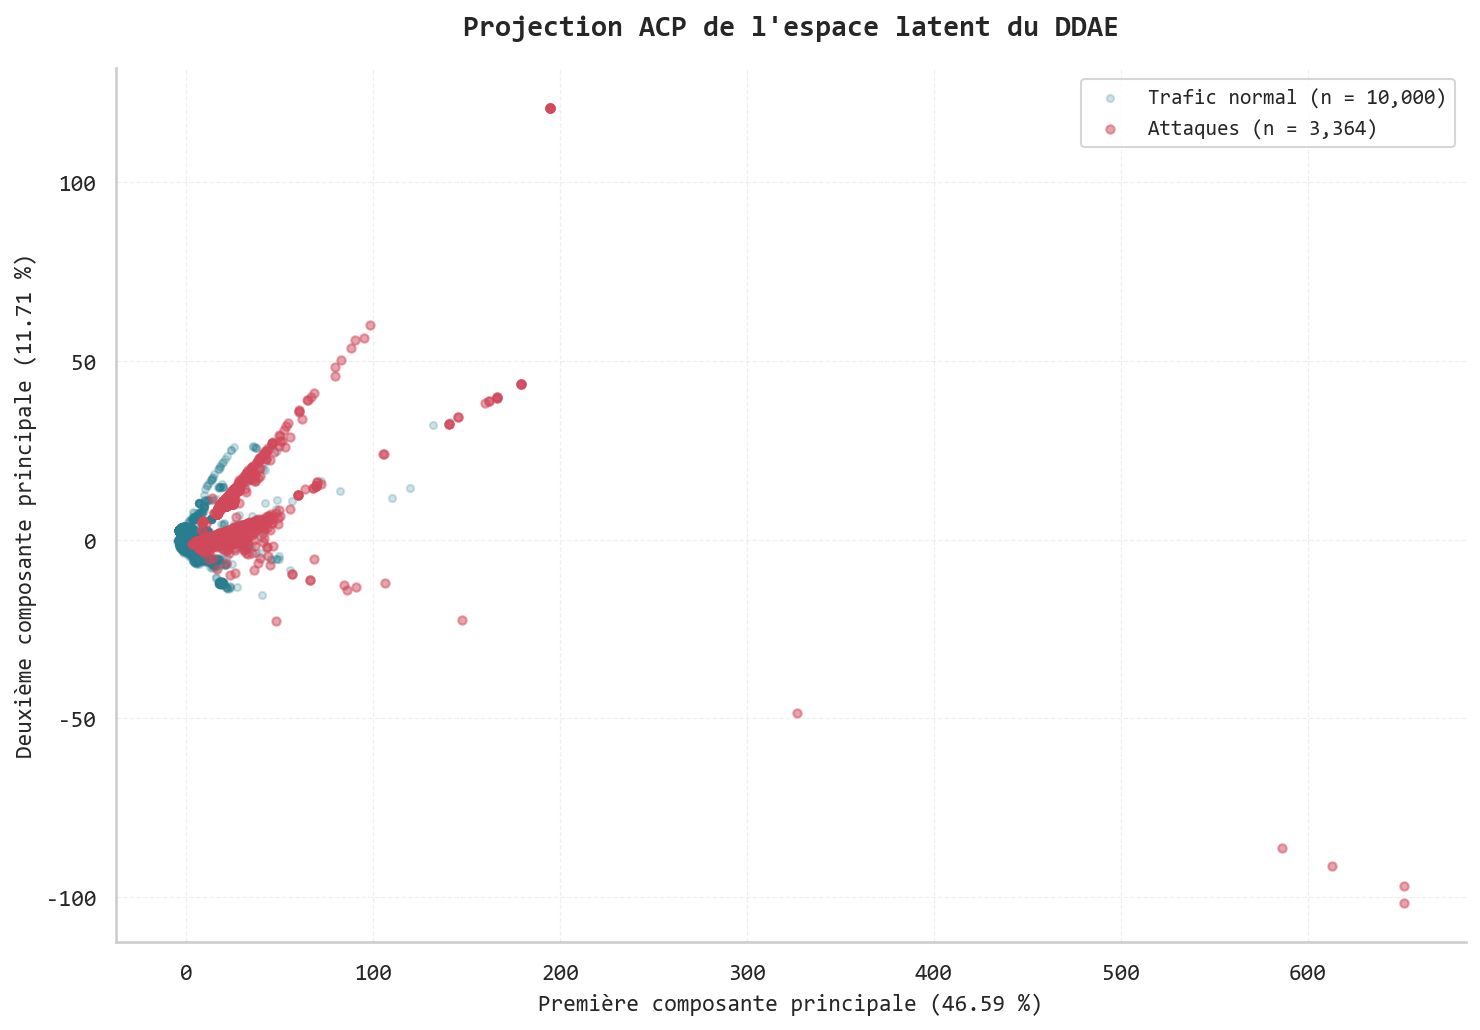


VARIANCE EXPLIQUEE


,Composante,Variance_expliquee_pct
0,Composante principale 1,46.586157
1,Composante principale 2,11.713992


In [73]:

# ============================================================
# CELLULE 29 — ANALYSE DE L'ESPACE LATENT PAR ACP
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Visualiser les representations latentes
# du trafic normal et des attaques.
#
# ACP ajustee sur le TRAIN NORMAL uniquement.
# Test utilise uniquement pour la visualisation.
# Aucun changement du DDAE ou du seuil.
# ============================================================

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.decomposition import PCA


# ------------------------------------------------------------
# 1. Verification des preconditions
# ------------------------------------------------------------

if not globals().get("TRAINING_COMPLETED", False):
    raise RuntimeError(
        "Executer correctement la cellule 15."
    )

if not globals().get("PROTOCOL_VALIDATED", False):
    raise RuntimeError(
        "Le protocole n'est pas valide."
    )

if not globals().get("TEST_SCORES_READY", False):
    raise RuntimeError(
        "Executer correctement la cellule 20."
    )

required_objects = [
    "ddae_scoring_model",
    "X_train_csr",
    "X_test_encoded",
    "y_test_array",
    "ids_test",
    "INPUT_DIM",
    "LATENT_DIM",
    "BATCH_SIZE",
    "SCIENTIFIC_FONT",
    "FIGURES_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR",
    "MODELS_DIR",
    "RANDOM_STATE"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Objets manquants : {missing}"
    )

# ------------------------------------------------------------
# 2. Recuperation de l'encodeur retenu
# ------------------------------------------------------------

# Important :
# L'encodeur est extrait du meilleur modele
# utilise pour calculer les scores du test.

latent_encoder = tf.keras.Model(
    inputs=ddae_scoring_model.inputs,
    outputs=ddae_scoring_model.get_layer(
        "representation_latente_16"
    ).output,
    name="Encodeur_DDAE_Analyse_Latente"
)

assert latent_encoder.output_shape[-1] == LATENT_DIM

# ------------------------------------------------------------
# 3. Preparation des matrices
# ------------------------------------------------------------

X_test_latent_csr = (
    X_test_encoded.tocsr()
    if sparse.issparse(X_test_encoded)
    else sparse.csr_matrix(
        X_test_encoded,
        dtype=np.float32
    )
)

assert X_train_csr.shape[1] == INPUT_DIM
assert X_test_latent_csr.shape[1] == INPUT_DIM

labels_latent = np.asarray(
    y_test_array,
    dtype=np.int8
)

ids_latent = np.asarray(
    ids_test,
    dtype=np.int64
)

assert (
    len(labels_latent)
    == len(ids_latent)
    == X_test_latent_csr.shape[0]
)

assert set(np.unique(labels_latent)) == {0, 1}

# ------------------------------------------------------------
# 4. Extraction des representations par lots
# ------------------------------------------------------------

def extract_latent_representations(
    model,
    matrix,
    batch_size=256
):
    """
    Extrait les vecteurs latents sans
    modifier les poids du modele.

    Conversion dense uniquement par lots.
    """

    if not sparse.issparse(matrix):
        matrix = sparse.csr_matrix(matrix)

    matrix = matrix.tocsr()

    n_samples = matrix.shape[0]

    latent_dim = int(
        model.output_shape[-1]
    )

    representations = np.empty(
        (n_samples, latent_dim),
        dtype=np.float32
    )

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        end = min(
            start + batch_size,
            n_samples
        )

        batch = (
            matrix[start:end]
            .toarray()
            .astype(np.float32, copy=False)
        )

        latent_batch = model(
            batch,
            training=False
        ).numpy()

        representations[start:end] = latent_batch

    if not np.isfinite(representations).all():
        raise ValueError(
            "Representations latentes non finies."
        )

    return representations

# ------------------------------------------------------------
# 5. Representation latente du TRAIN NORMAL
# ------------------------------------------------------------

print("\nExtraction des vecteurs latents : train normal")

Z_train_normal = extract_latent_representations(
    latent_encoder,
    X_train_csr,
    batch_size=BATCH_SIZE
)

print("Dimensions :", Z_train_normal.shape)

# ------------------------------------------------------------
# 6. Ajustement de l'ACP
# ------------------------------------------------------------

# L'ACP est ajustee uniquement sur
# les observations normales d'entrainement.
#
# Le test ne contribue pas au calcul
# des axes de projection.

pca_latent = PCA(
    n_components=2,
    svd_solver="full"
)

pca_latent.fit(
    Z_train_normal
)

explained_variance = (
    pca_latent.explained_variance_ratio_
)

print("\nVARIANCE EXPLIQUEE PAR L'ACP")

print(
    "Composante 1 :",
    f"{explained_variance[0] * 100:.2f} %"
)

print(
    "Composante 2 :",
    f"{explained_variance[1] * 100:.2f} %"
)

print(
    "Variance cumulee :",
    f"{explained_variance.sum() * 100:.2f} %"
)

# ------------------------------------------------------------
# 7. Extraction des vecteurs latents du TEST
# ------------------------------------------------------------

print("\nExtraction des vecteurs latents du test...")

Z_test = extract_latent_representations(
    latent_encoder,
    X_test_latent_csr,
    batch_size=BATCH_SIZE
)

assert Z_test.shape == (
    len(labels_latent),
    LATENT_DIM
)

# ------------------------------------------------------------
# 8. Projection du test sans nouvel ajustement
# ------------------------------------------------------------

Z_test_pca = pca_latent.transform(
    Z_test
)

assert Z_test_pca.shape == (
    len(labels_latent),
    2
)

# ------------------------------------------------------------
# 9. Preparation du tableau individuel
# ------------------------------------------------------------

latent_table = pd.DataFrame({
    "ID_observation": ids_latent,
    "Classe_reelle": labels_latent,
    "Composante_1": Z_test_pca[:, 0],
    "Composante_2": Z_test_pca[:, 1]
})

latent_table["Classe_trafic"] = np.where(
    latent_table["Classe_reelle"] == 0,
    "Trafic normal",
    "Attaque"
)

print("\nAPERÇU DES PROJECTIONS")

display(latent_table.head(10))

# ------------------------------------------------------------
# 10. Echantillonnage pour la visualisation
# ------------------------------------------------------------

# L'echantillonnage est uniquement graphique.
# Les metriques du modele ne sont pas modifiees.
#
# Les donnees projetees completes restent
# disponibles pour l'export.

MAX_NORMAL_POINTS = 10000
MAX_ATTACK_POINTS = 10000

rng = np.random.default_rng(
    RANDOM_STATE
)

normal_positions = np.flatnonzero(
    labels_latent == 0
)

attack_positions = np.flatnonzero(
    labels_latent == 1
)

normal_plot_positions = rng.choice(
    normal_positions,
    size=min(
        MAX_NORMAL_POINTS,
        len(normal_positions)
    ),
    replace=False
)

attack_plot_positions = rng.choice(
    attack_positions,
    size=min(
        MAX_ATTACK_POINTS,
        len(attack_positions)
    ),
    replace=False
)

plot_positions = np.concatenate([
    normal_plot_positions,
    attack_plot_positions
])

plot_table = latent_table.iloc[
    plot_positions
].copy()

print("\nOBSERVATIONS REPRESENTEES")

print(
    "Trafic normal :",
    len(normal_plot_positions)
)

print(
    "Attaques :",
    len(attack_plot_positions)
)

# ------------------------------------------------------------
# 11. Configuration scientifique
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": SCIENTIFIC_FONT,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
    "axes.unicode_minus": False,
    "savefig.dpi": 300
})

COLOR_NORMAL = "#287D8E"
COLOR_ATTACK = "#D1495B"

# ------------------------------------------------------------
# 12. Visualisation ACP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 7),
    dpi=150
)

normal_plot = plot_table[
    plot_table["Classe_reelle"] == 0
]

attack_plot = plot_table[
    plot_table["Classe_reelle"] == 1
]

ax.scatter(
    normal_plot["Composante_1"],
    normal_plot["Composante_2"],
    s=12,
    alpha=0.22,
    color=COLOR_NORMAL,
    label=(
        f"Trafic normal "
        f"(n = {len(normal_plot):,})"
    ),
    rasterized=True
)

ax.scatter(
    attack_plot["Composante_1"],
    attack_plot["Composante_2"],
    s=16,
    alpha=0.50,
    color=COLOR_ATTACK,
    label=(
        f"Attaques "
        f"(n = {len(attack_plot):,})"
    ),
    rasterized=True
)

# ------------------------------------------------------------
# 13. Titres et axes
# ------------------------------------------------------------

ax.set_title(
    "Projection ACP de l'espace latent du DDAE",
    fontsize=14,
    fontweight="bold",
    fontfamily=SCIENTIFIC_FONT,
    pad=16
)

ax.set_xlabel(
    (
        "Première composante principale "
        f"({explained_variance[0] * 100:.2f} %)"
    ),
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.set_ylabel(
    (
        "Deuxième composante principale "
        f"({explained_variance[1] * 100:.2f} %)"
    ),
    fontsize=11,
    fontfamily=SCIENTIFIC_FONT
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.30
)

ax.legend(
    loc="best",
    fontsize=10,
    frameon=True
)

sns.despine(
    ax=ax,
    top=True,
    right=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 14. Sauvegarde de la figure
# ------------------------------------------------------------

FIGURE_NAME = "projection_ACP_espace_latent_DDAE"

png_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.png"
)

pdf_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.pdf"
)

svg_path = (
    FIGURES_DIR / f"{FIGURE_NAME}.svg"
)

fig.savefig(
    png_path,
    format="png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 15. Sauvegarde de l'ACP et des projections
# ------------------------------------------------------------

PCA_MODEL_PATH = (
    MODELS_DIR / "ACP_espace_latent_DDAE.joblib"
)

joblib.dump(
    pca_latent,
    PCA_MODEL_PATH
)

latent_table.to_csv(
    TABLES_DIR / "projection_latente_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

np.save(
    ARTIFACTS_DIR / "vecteurs_latents_test_DDAE.npy",
    Z_test
)

# ------------------------------------------------------------
# 16. Tableau de variance expliquee
# ------------------------------------------------------------

variance_table = pd.DataFrame({
    "Composante": [
        "Composante principale 1",
        "Composante principale 2"
    ],
    "Variance_expliquee_pct": (
        explained_variance * 100
    )
})

print("\nVARIANCE EXPLIQUEE")

display(variance_table)

variance_table.to_csv(
    TABLES_DIR / "variance_ACP_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 17. Rapport de tracabilite
# ------------------------------------------------------------

latent_report = {
    "dataset": DATASET_NAME,
    "modele": MODEL_NAME,
    "analyse": "exploratoire_post_evaluation",
    "dimension_latente": int(LATENT_DIM),
    "dimension_ACP": 2,
    "ACP_fit": "train_normal_uniquement",
    "test_ACP": "transform_uniquement",
    "variance_PC1_pct": float(
        explained_variance[0] * 100
    ),
    "variance_PC2_pct": float(
        explained_variance[1] * 100
    ),
    "variance_cumulee_pct": float(
        explained_variance.sum() * 100
    ),
    "observations_test": int(
        len(labels_latent)
    ),
    "points_normaux_affiches": int(
        len(normal_plot)
    ),
    "points_attaques_affiches": int(
        len(attack_plot)
    ),
    "modele_modifie": False,
    "seuil_modifie": False,
    "optimisation_sur_test": False
}

LATENT_REPORT_PATH = (
    ARTIFACTS_DIR / "rapport_espace_latent_DDAE.json"
)

with open(
    LATENT_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        latent_report,
        file,
        indent=4,
        ensure_ascii=False
    )

In [77]:

# ============================================================
# CELLULE 30 — AUDIT FINAL DES RESULTATS EXPERIMENTAUX
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Verifier la coherence du protocole,
# des scores, des predictions, des metriques
# et des principaux fichiers exportes.
#
# Aucun entrainement.
# Aucun recalibrage.
# Aucune modification des resultats.
# ============================================================

import json
import hashlib
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

from scipy import sparse

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 75)
print("CELLULE 30 — AUDIT FINAL DU DDAE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Creation du dossier d'audit
# ------------------------------------------------------------

AUDIT_DIR = (
    RESULTS_DIR / "audit_final_DDAE"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

AUDIT_JSON_PATH = (
    AUDIT_DIR / "rapport_audit_final_DDAE.json"
)

AUDIT_CSV_PATH = (
    AUDIT_DIR / "controles_audit_DDAE.csv"
)

AUDIT_TXT_PATH = (
    AUDIT_DIR / "synthese_audit_DDAE.txt"
)

AUDIT_METRICS_PATH = (
    AUDIT_DIR / "metriques_verifiees_DDAE.csv"
)

# ------------------------------------------------------------
# 2. Registre des controles
# ------------------------------------------------------------

audit_checks = []

def register_check(name, condition, details=""):

    passed = bool(condition)

    audit_checks.append({
        "Controle": name,
        "Statut": "VALIDE" if passed else "ECHEC",
        "Details": str(details)
    })

    symbol = "[OK]" if passed else "[ECHEC]"

    print(f"{symbol} {name}")

    if not passed and details:
        print("   ", details)

    return passed


def same_number(a, b):

    return bool(
        np.isclose(
            float(a),
            float(b),
            rtol=1e-10,
            atol=1e-12
        )
    )


def hash_file(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha.update(block)

    return sha.hexdigest()


# ------------------------------------------------------------
# 3. Verification des objets indispensables
# ------------------------------------------------------------

required_variables = [
    "PROTOCOL_VALIDATED",
    "CLEAN_AUDIT_PASSED",
    "TRAINING_COMPLETED",
    "CALIBRATION_COMPLETED",
    "TEST_SCORES_READY",
    "CONFUSION_MATRIX_READY",
    "METRICS_READY",
    "ids_train",
    "ids_val",
    "ids_test",
    "ids_train_normal",
    "ids_val_normal",
    "y",
    "y_train_all",
    "y_val_all",
    "y_test",
    "X_train_encoded",
    "X_val_encoded",
    "X_test_encoded",
    "mse_val_normal",
    "mse_test",
    "y_pred_test",
    "THRESHOLD_DDAE",
    "DDAE_METRICS",
    "BEST_MODEL_PATH",
    "THRESHOLD_PATH",
    "TABLES_DIR",
    "FIGURES_DIR",
    "SCORES_DIR",
    "ARTIFACTS_DIR"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

register_check(
    "Variables indispensables disponibles",
    len(missing_variables) == 0,
    (
        "Variables absentes : "
        + ", ".join(missing_variables)
        if missing_variables
        else "Tous les objets requis sont presents."
    )
)

if missing_variables:

    audit_dataframe = pd.DataFrame(
        audit_checks
    )

    audit_dataframe.to_csv(
        AUDIT_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )

    raise RuntimeError(
        "Audit interrompu : variables manquantes. "
        "Reexecuter les cellules concernees."
    )

# ------------------------------------------------------------
# 4. Verification des indicateurs du protocole
# ------------------------------------------------------------

for flag_name in [
    "PROTOCOL_VALIDATED",
    "CLEAN_AUDIT_PASSED",
    "TRAINING_COMPLETED",
    "CALIBRATION_COMPLETED",
    "TEST_SCORES_READY",
    "CONFUSION_MATRIX_READY",
    "METRICS_READY"
]:

    register_check(
        flag_name,
        globals()[flag_name] is True
    )

# ------------------------------------------------------------
# 5. Verification des ensembles
# ------------------------------------------------------------

train_ids = np.asarray(
    ids_train,
    dtype=np.int64
)

val_ids = np.asarray(
    ids_val,
    dtype=np.int64
)

test_ids = np.asarray(
    ids_test,
    dtype=np.int64
)

all_ids = np.concatenate([
    train_ids,
    val_ids,
    test_ids
])

register_check(
    "Absence de chevauchement des indices",
    (
        len(np.unique(all_ids))
        == len(all_ids)
    ),
    "Chaque observation appartient a un seul ensemble."
)

register_check(
    "Couverture complete des observations",
    (
        len(all_ids) == len(y)
        and np.array_equal(
            np.sort(all_ids),
            np.arange(len(y))
        )
    ),
    "Les indices couvrent le jeu de donnees."
)

# ------------------------------------------------------------
# 6. Verification des groupes de signatures
# ------------------------------------------------------------

# La cellule 8 a construit group_inverse
# pour eviter le partage de signatures
# selectionnees entre les ensembles.

if "group_inverse" in globals():

    group_array = np.asarray(
        group_inverse
    )

    valid_group_length = (
        len(group_array) == len(y)
    )

    register_check(
        "Longueur des groupes coherente",
        valid_group_length
    )

    if valid_group_length:

        train_groups = np.unique(
            group_array[train_ids]
        )

        val_groups = np.unique(
            group_array[val_ids]
        )

        test_groups = np.unique(
            group_array[test_ids]
        )

        groups_disjoint = (
            np.intersect1d(
                train_groups,
                val_groups
            ).size == 0
            and np.intersect1d(
                train_groups,
                test_groups
            ).size == 0
            and np.intersect1d(
                val_groups,
                test_groups
            ).size == 0
        )

        register_check(
            "Groupes de signatures disjoints",
            groups_disjoint
        )

else:

    register_check(
        "Groupes de signatures disponibles",
        False,
        "Variable group_inverse absente."
    )

# ------------------------------------------------------------
# 7. Verification de l'apprentissage one-class
# ------------------------------------------------------------

train_normal_ids = np.asarray(
    ids_train_normal,
    dtype=np.int64
)

val_normal_ids = np.asarray(
    ids_val_normal,
    dtype=np.int64
)

y_all = np.asarray(
    y,
    dtype=np.int8
)

register_check(
    "Entrainement exclusivement normal",
    bool(
        np.all(
            y_all[train_normal_ids] == 0
        )
    )
)

register_check(
    "Calibration exclusivement normale",
    bool(
        np.all(
            y_all[val_normal_ids] == 0
        )
    )
)

register_check(
    "Indices de train normal corrects",
    np.array_equal(
        np.sort(train_normal_ids),
        np.sort(
            train_ids[
                y_all[train_ids] == 0
            ]
        )
    )
)

register_check(
    "Indices de validation normale corrects",
    np.array_equal(
        np.sort(val_normal_ids),
        np.sort(
            val_ids[
                y_all[val_ids] == 0
            ]
        )
    )
)

# ------------------------------------------------------------
# 8. Verification des dimensions encodees
# ------------------------------------------------------------

n_features = int(
    X_train_encoded.shape[1]
)

same_dimensions = (
    X_train_encoded.shape[1]
    == X_val_encoded.shape[1]
    == X_test_encoded.shape[1]
)

register_check(
    "Dimensions des matrices identiques",
    same_dimensions,
    f"{n_features} caracteristiques encodees."
)

register_check(
    "Effectif train normal coherent",
    (
        X_train_encoded.shape[0]
        == len(train_normal_ids)
    )
)

register_check(
    "Effectif validation normale coherent",
    (
        X_val_encoded.shape[0]
        == len(val_normal_ids)
    )
)

register_check(
    "Effectif test coherent",
    (
        X_test_encoded.shape[0]
        == len(test_ids)
    )
)

# ------------------------------------------------------------
# 9. Verification des valeurs numeriques
# ------------------------------------------------------------

def finite_matrix(matrix):

    values = (
        matrix.data
        if sparse.issparse(matrix)
        else np.asarray(matrix)
    )

    return bool(
        np.isfinite(values).all()
    )


register_check(
    "Train sans valeurs non finies",
    finite_matrix(X_train_encoded)
)

register_check(
    "Validation sans valeurs non finies",
    finite_matrix(X_val_encoded)
)

register_check(
    "Test sans valeurs non finies",
    finite_matrix(X_test_encoded)
)

# ------------------------------------------------------------
# 10. Verification de la calibration
# ------------------------------------------------------------

validation_scores = np.asarray(
    mse_val_normal,
    dtype=np.float64
)

fixed_threshold = float(
    THRESHOLD_DDAE
)

register_check(
    "Scores de validation finis et non negatifs",
    bool(
        validation_scores.size > 0
        and np.isfinite(validation_scores).all()
        and np.all(validation_scores >= 0)
    )
)

expected_threshold = float(
    np.percentile(
        validation_scores,
        95,
        method="linear"
    )
)

register_check(
    "Seuil egal au 95e percentile validation",
    same_number(
        fixed_threshold,
        expected_threshold
    ),
    (
        f"Seuil = {fixed_threshold:.10f}; "
        f"recalcul = {expected_threshold:.10f}"
    )
)

# Verification du fichier sauvegarde

threshold_file_exists = Path(
    THRESHOLD_PATH
).is_file()

register_check(
    "Fichier de calibration present",
    threshold_file_exists
)

if threshold_file_exists:

    with open(
        THRESHOLD_PATH,
        "r",
        encoding="utf-8"
    ) as file:

        saved_threshold_config = json.load(
            file
        )

    register_check(
        "Seuil sauvegarde coherent",
        same_number(
            saved_threshold_config["seuil"],
            fixed_threshold
        )
    )

    register_check(
        "Origine de calibration correcte",
        (
            saved_threshold_config.get(
                "population_calibration"
            ) == "validation_normale"
            and saved_threshold_config.get(
                "percentile"
            ) == 95
        )
    )

# ------------------------------------------------------------
# 11. Verification des scores du test
# ------------------------------------------------------------

test_scores = np.asarray(
    mse_test,
    dtype=np.float64
)

test_labels = np.asarray(
    y_test,
    dtype=np.int8
)

test_predictions = np.asarray(
    y_pred_test,
    dtype=np.int8
)

register_check(
    "Scores de test finis et non negatifs",
    bool(
        test_scores.size > 0
        and np.isfinite(test_scores).all()
        and np.all(test_scores >= 0)
    )
)

register_check(
    "Alignement etiquettes et indices du test",
    (
        len(test_labels) == len(test_ids)
        and np.array_equal(
            test_labels,
            y_all[test_ids]
        )
    )
)

register_check(
    "Alignement scores, etiquettes, predictions",
    (
        len(test_scores)
        == len(test_labels)
        == len(test_predictions)
    )
)

register_check(
    "Predictions issues du seuil fixe",
    np.array_equal(
        test_predictions,
        (test_scores > fixed_threshold).astype(
            np.int8
        )
    )
)

# ------------------------------------------------------------
# 12. Recalcul de la matrice de confusion
# ------------------------------------------------------------

cm_audit = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

tn_audit, fp_audit, fn_audit, tp_audit = [
    int(value)
    for value in cm_audit.ravel()
]

register_check(
    "Matrice de confusion coherente",
    (
        (tn_audit, fp_audit, fn_audit, tp_audit)
        == (TN, FP, FN, TP)
    ),
    (
        f"TN={tn_audit}, FP={fp_audit}, "
        f"FN={fn_audit}, TP={tp_audit}"
    )
)

# ------------------------------------------------------------
# 13. Recalcul independant des performances
# ------------------------------------------------------------

audit_metrics = {
    "Accuracy": accuracy_score(
        test_labels,
        test_predictions
    ),

    "Precision": precision_score(
        test_labels,
        test_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        test_labels,
        test_predictions,
        zero_division=0
    ),

    "F1-score": f1_score(
        test_labels,
        test_predictions,
        zero_division=0
    ),

    "Specificity": (
        tn_audit / (tn_audit + fp_audit)
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        test_labels,
        test_predictions
    ),

    "ROC-AUC": roc_auc_score(
        test_labels,
        test_scores
    ),

    "Average Precision": average_precision_score(
        test_labels,
        test_scores
    ),

    "FPR": (
        fp_audit / (fp_audit + tn_audit)
    ),

    "FNR": (
        fn_audit / (fn_audit + tp_audit)
    )
}

# ------------------------------------------------------------
# 14. Comparaison avec la cellule 23
# ------------------------------------------------------------

for metric_name, recalculated_value in (
    audit_metrics.items()
):

    stored_value = DDAE_METRICS.get(
        metric_name
    )

    register_check(
        f"Metrique coherente : {metric_name}",
        (
            stored_value is not None
            and same_number(
                recalculated_value,
                stored_value
            )
        ),
        (
            f"Recalcul = {recalculated_value:.8f}; "
            f"cellule 23 = {stored_value}"
        )
    )

# ------------------------------------------------------------
# 15. Verification des sorties ROC et PR
# ------------------------------------------------------------

if "ROC_AUC_VALUE" in globals():

    register_check(
        "ROC-AUC coherent avec cellule 25",
        same_number(
            audit_metrics["ROC-AUC"],
            ROC_AUC_VALUE
        )
    )

else:

    register_check(
        "Resultat ROC de la cellule 25 present",
        False
    )

if "AP_VALUE" in globals():

    register_check(
        "Average Precision coherente avec cellule 26",
        same_number(
            audit_metrics["Average Precision"],
            AP_VALUE
        )
    )

else:

    register_check(
        "Resultat PR de la cellule 26 present",
        False
    )

# ------------------------------------------------------------
# 16. Verification des fichiers principaux
# ------------------------------------------------------------

expected_files = {
    "Modele DDAE retenu": Path(BEST_MODEL_PATH),

    "Scores validation": (
        SCORES_DIR /
        "scores_MSE_validation_normale_DDAE.npy"
    ),

    "Scores test": (
        SCORES_DIR /
        "scores_MSE_test_DDAE.npy"
    ),

    "Predictions test": (
        SCORES_DIR /
        "predictions_test_DDAE.npy"
    ),

    "Matrice de confusion": (
        FIGURES_DIR /
        "matrice_confusion_DDAE_test_independant.png"
    ),

    "Performances globales": (
        TABLES_DIR /
        "performances_globales_DDAE.csv"
    ),

    "Courbe ROC": (
        FIGURES_DIR /
        "courbe_ROC_DDAE_test_independant.png"
    ),

    "Courbe precision-rappel": (
        FIGURES_DIR /
        "courbe_precision_rappel_DDAE_test_independant.png"
    ),

    "Categories d'attaque": (
        TABLES_DIR /
        "performances_categories_attaques_DDAE.csv"
    )
}

for description, file_path in expected_files.items():

    register_check(
        f"Fichier present : {description}",
        file_path.is_file(),
        str(file_path)
    )

# ------------------------------------------------------------
# 17. Controle des fichiers de scores exportes
# ------------------------------------------------------------

saved_test_scores_path = (
    SCORES_DIR /
    "scores_MSE_test_DDAE.npy"
)

if saved_test_scores_path.is_file():

    saved_test_scores = np.load(
        saved_test_scores_path
    )

    register_check(
        "Scores exportes identiques",
        np.array_equal(
            saved_test_scores,
            test_scores
        )
    )

saved_predictions_path = (
    SCORES_DIR /
    "predictions_test_DDAE.npy"
)

if saved_predictions_path.is_file():

    saved_predictions = np.load(
        saved_predictions_path
    )

    register_check(
        "Predictions exportees identiques",
        np.array_equal(
            saved_predictions,
            test_predictions
        )
    )

# ------------------------------------------------------------
# 18. Controle complementaire des caracteristiques
# ------------------------------------------------------------

if (
    "FEATURE_COLUMNS" in globals()
    and "SELECTED_FEATURES" in globals()
):

    selected_feature_set = set(
        SELECTED_FEATURES
    )

    excluded_targets = {
        "label",
        "attack_cat"
    }

    register_check(
        "Etiquettes absentes des caracteristiques",
        selected_feature_set.isdisjoint(
            excluded_targets
        )
    )

    register_check(
        "Caracteristiques selectionnees documentees",
        selected_feature_set.issubset(
            set(FEATURE_COLUMNS)
        )
    )

else:

    register_check(
        "Traçabilite des caracteristiques disponible",
        False
    )

# ------------------------------------------------------------
# 19. Controle des etapes complementaires
# ------------------------------------------------------------

optional_flags = {
    "Analyse des erreurs": "ERROR_ANALYSIS_READY",
    "Analyse des categories": "CATEGORY_ANALYSIS_READY",
    "Analyse latente": "LATENT_ANALYSIS_READY"
}

for description, flag_name in optional_flags.items():

    register_check(
        description,
        globals().get(flag_name, False) is True
    )

# ------------------------------------------------------------
# 20. Tableau de verification des metriques
# ------------------------------------------------------------

verified_metrics_table = pd.DataFrame({
    "Metrique": list(
        audit_metrics.keys()
    ),
    "Valeur": list(
        audit_metrics.values()
    )
})

verified_metrics_table[
    "Valeur_pct"
] = (
    verified_metrics_table["Valeur"] * 100
)

verified_metrics_table.to_csv(
    AUDIT_METRICS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nPERFORMANCES VERIFIEES")

display(
    verified_metrics_table.style.format({
        "Valeur": "{:.6f}",
        "Valeur_pct": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 21. Tableau final de l'audit
# ------------------------------------------------------------

audit_dataframe = pd.DataFrame(
    audit_checks
)

n_checks = len(
    audit_dataframe
)

n_passed = int(
    (audit_dataframe["Statut"] == "VALIDE").sum()
)

n_failed = int(
    (audit_dataframe["Statut"] == "ECHEC").sum()
)

AUDIT_PASSED = (
    n_failed == 0
)

print("\nRESULTATS DES CONTROLES")

display(audit_dataframe)

audit_dataframe.to_csv(
    AUDIT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 22. Rapport JSON
# ------------------------------------------------------------

audit_report = {
    "date_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "dataset": "UNSW-NB15",

    "modele": "Deep Dense Autoencoder",

    "protocole": "one-class",

    "evaluation": "test_independant",

    "taille_train": int(
        len(train_ids)
    ),

    "taille_validation": int(
        len(val_ids)
    ),

    "taille_test": int(
        len(test_ids)
    ),

    "caracteristiques_encodees": int(
        n_features
    ),

    "seuil": float(
        fixed_threshold
    ),

    "percentile_calibration": 95,

    "seuil_origine": "validation_normale",

    "matrice_confusion": {
        "TN": tn_audit,
        "FP": fp_audit,
        "FN": fn_audit,
        "TP": tp_audit
    },

    "metriques": {
        name: float(value)
        for name, value in audit_metrics.items()
    },

    "nombre_controles": n_checks,

    "controles_valides": n_passed,

    "controles_echoues": n_failed,

    "audit_reussi": bool(
        AUDIT_PASSED
    ),

    "limites": [
        "L'audit ne prouve pas l'independance "
        "temporelle des sessions reseau.",
        "L'absence de chevauchement des signatures "
        "ne garantit pas l'absence de toute dependance.",
        "Les analyses descriptives sur le test "
        "ne doivent pas guider une nouvelle optimisation."
    ],

    "controles": audit_checks
}

with open(
    AUDIT_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        audit_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 23. Synthese textuelle
# ------------------------------------------------------------

summary_lines = [
    "=" * 75,
    "RAPPORT FINAL D'AUDIT — DEEP DENSE AUTOENCODER",
    "=" * 75,
    "",
    f"Observations train : {len(train_ids)}",
    f"Observations validation : {len(val_ids)}",
    f"Observations test : {len(test_ids)}",
    f"Caracteristiques encodees : {n_features}",
    "",
    f"Seuil MSE : {fixed_threshold:.10f}",
    "Calibration : 95e percentile des normaux de validation",
    "",
    f"TN : {tn_audit}",
    f"FP : {fp_audit}",
    f"FN : {fn_audit}",
    f"TP : {tp_audit}",
    "",
    "PERFORMANCES"
]

for name, value in audit_metrics.items():

    summary_lines.append(
        f"{name} : {value:.6f}"
    )

summary_lines.extend([
    "",
    "AUDIT",
    f"Controles executes : {n_checks}",
    f"Controles valides : {n_passed}",
    f"Controles echoues : {n_failed}",
    "",
    (
        "Statut : VALIDATION REUSSIE"
        if AUDIT_PASSED
        else "Statut : CORRECTIONS NECESSAIRES"
    ),
    "",
    "LIMITES",
    "Les controles ne demontrent pas "
    "l'independance temporelle des sessions.",
    "Les analyses du test restent descriptives.",
    "",
    "=" * 75
])

with open(
    AUDIT_TXT_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "\n".join(summary_lines)
    )

# ------------------------------------------------------------
# 24. Bilan final
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BILAN FINAL DE L'AUDIT DDAE")
print("=" * 75)

print("Controles executes :", n_checks)
print("Controles valides :", n_passed)
print("Controles echoues :", n_failed)

print("\nRapport JSON :", AUDIT_JSON_PATH)
print("Rapport CSV :", AUDIT_CSV_PATH)
print("Rapport TXT :", AUDIT_TXT_PATH)
print("Metriques verifiees :", AUDIT_METRICS_PATH)

if AUDIT_PASSED:

    print("\nSTATUT : AUDIT DE COHERENCE REUSSI")

else:

    print("\nSTATUT : DES CORRECTIONS SONT NECESSAIRES")

    print("\nCONTROLES EN ECHEC :")

    failed_checks = audit_dataframe.loc[
        audit_dataframe["Statut"] == "ECHEC",
        ["Controle", "Details"]
    ]

    display(failed_checks)

print("\nModele modifie : NON")
print("Seuil modifie : NON")
print("Aucun nouvel entrainement.")

print("=" * 75)

if not AUDIT_PASSED:

    raise RuntimeError(
        "L'audit final contient des controles en echec. "
        "Consulter le tableau et corriger les problemes "
        "avant de declarer les resultats valides."
    )

CELLULE 30 — AUDIT FINAL DU DDAE
[OK] Variables indispensables disponibles
[OK] PROTOCOL_VALIDATED
[OK] CLEAN_AUDIT_PASSED
[OK] TRAINING_COMPLETED
[OK] CALIBRATION_COMPLETED
[OK] TEST_SCORES_READY
[OK] CONFUSION_MATRIX_READY
[OK] METRICS_READY
[OK] Absence de chevauchement des indices
[OK] Couverture complete des observations
[OK] Longueur des groupes coherente
[OK] Groupes de signatures disjoints
[OK] Entrainement exclusivement normal
[OK] Calibration exclusivement normale
[OK] Indices de train normal corrects
[OK] Indices de validation normale corrects
[OK] Dimensions des matrices identiques
[OK] Effectif train normal coherent
[OK] Effectif validation normale coherent
[OK] Effectif test coherent
[OK] Train sans valeurs non finies
[OK] Validation sans valeurs non finies
[OK] Test sans valeurs non finies
[OK] Scores de validation finis et non negatifs
[OK] Seuil egal au 95e percentile validation
[OK] Fichier de calibration present
[OK] Seuil sauvegarde coherent
[OK] Origine de calibrat

,Metrique,Valeur,Valeur_pct
0,Accuracy,0.951064,95.1064 %
1,Precision,0.391932,39.1932 %
2,Recall,0.953032,95.3032 %
3,F1-score,0.555440,55.5440 %
4,Specificity,0.950998,95.0998 %
5,Balanced Accuracy,0.952015,95.2015 %
6,ROC-AUC,0.985124,98.5124 %
7,Average Precision,0.574567,57.4567 %
8,FPR,0.049002,4.9002 %
9,FNR,0.046968,4.6968 %



RESULTATS DES CONTROLES


,Controle,Statut,Details
0,Variables indispensables disponibles,VALIDE,Tous les objets requis sont presents.
1,PROTOCOL_VALIDATED,VALIDE,
2,CLEAN_AUDIT_PASSED,VALIDE,
3,TRAINING_COMPLETED,VALIDE,
4,CALIBRATION_COMPLETED,VALIDE,
...,...,...,...
56,Etiquettes absentes des caracteristiques,VALIDE,
57,Caracteristiques selectionnees documentees,VALIDE,
58,Analyse des erreurs,VALIDE,
59,Analyse des categories,VALIDE,



BILAN FINAL DE L'AUDIT DDAE
Controles executes : 61
Controles valides : 61
Controles echoues : 0

Rapport JSON : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\audit_final_DDAE\rapport_audit_final_DDAE.json
Rapport CSV : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\audit_final_DDAE\controles_audit_DDAE.csv
Rapport TXT : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\audit_final_DDAE\synthese_audit_DDAE.txt
Metriques verifiees : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\audit_final_DDAE\metriques_verifiees_DDAE.csv

STATUT : AUDIT DE COHERENCE REUSSI

Modele modifie : NON
Seuil modifie : NON
Aucun nouvel entrainement.


In [80]:

# ============================================================
# CELLULE 31 — TABLEAU FINAL DES RESULTATS DU DDAE
# ============================================================
# Modele : Deep Dense Autoencoder (DDAE)
# Dataset : UNSW-NB15
# Protocole : One-Class Learning
#
# Objectif :
# Produire les tableaux definitifs des resultats
# experimentaux sur le test independant.
#
# Aucune modification du modele ou du seuil.
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 75)
print("CELLULE 31 — SYNTHESE FINALE DES RESULTATS DDAE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verification de l'audit precedent
# ------------------------------------------------------------

if not globals().get("AUDIT_PASSED", False):
    raise RuntimeError(
        "L'audit final de la cellule 30 n'est pas valide. "
        "Corriger les controles en echec avant de continuer."
    )

required_objects = [
    "DDAE_METRICS",
    "ids_train",
    "ids_val",
    "ids_test",
    "ids_train_normal",
    "ids_val_normal",
    "y_test_array",
    "y_pred_test",
    "mse_test",
    "mse_val_normal",
    "THRESHOLD_DDAE",
    "INPUT_DIM",
    "TN",
    "FP",
    "FN",
    "TP",
    "RESULTS_DIR",
    "TABLES_DIR",
    "ARTIFACTS_DIR",
    "AUDIT_JSON_PATH"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants : {missing_objects}"
    )

with open(
    AUDIT_JSON_PATH,
    "r",
    encoding="utf-8"
) as file:
    audit_report = json.load(file)

if not audit_report.get("audit_reussi", False):
    raise RuntimeError(
        "Le rapport d'audit sauvegarde indique un echec."
    )

print("\nAudit final : VALIDE")

# ------------------------------------------------------------
# 2. Preparation des dossiers
# ------------------------------------------------------------

SUMMARY_DIR = (
    RESULTS_DIR / "synthese_finale_DDAE"
)

SUMMARY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Recuperation des donnees experimentales
# ------------------------------------------------------------

y_true_final = np.asarray(
    y_test_array,
    dtype=np.int8
)

y_pred_final = np.asarray(
    y_pred_test,
    dtype=np.int8
)

scores_final = np.asarray(
    mse_test,
    dtype=np.float64
)

validation_scores_final = np.asarray(
    mse_val_normal,
    dtype=np.float64
)

threshold_final = float(
    THRESHOLD_DDAE
)

assert (
    len(y_true_final)
    == len(y_pred_final)
    == len(scores_final)
    == len(ids_test)
)

assert np.isfinite(scores_final).all()
assert np.isfinite(validation_scores_final).all()

assert set(np.unique(y_true_final)) == {0, 1}

# ------------------------------------------------------------
# 4. Verification du seuil operationnel
# ------------------------------------------------------------

threshold_recalculated = float(
    np.percentile(
        validation_scores_final,
        95,
        method="linear"
    )
)

assert np.isclose(
    threshold_final,
    threshold_recalculated,
    rtol=1e-12,
    atol=0
)

assert np.array_equal(
    y_pred_final,
    (scores_final > threshold_final).astype(np.int8)
)

# ------------------------------------------------------------
# 5. Effectifs des ensembles
# ------------------------------------------------------------

n_train_total = int(len(ids_train))
n_train_normal = int(len(ids_train_normal))

n_val_total = int(len(ids_val))
n_val_normal = int(len(ids_val_normal))

n_test_total = int(len(ids_test))

n_test_normal = int(
    np.sum(y_true_final == 0)
)

n_test_attack = int(
    np.sum(y_true_final == 1)
)

protocol_table = pd.DataFrame({
    "Ensemble": [
        "Entraînement total (partition)",
        "Entraînement utilisé par le DDAE",
        "Validation totale (partition)",
        "Validation utilisée pour la calibration",
        "Test indépendant"
    ],
    "Observations": [
        n_train_total,
        n_train_normal,
        n_val_total,
        n_val_normal,
        n_test_total
    ],
    "Utilisation": [
        "Partitionnement et contrôles",
        "Apprentissage sur trafic normal",
        "Partitionnement et contrôles",
        "Calibration du seuil sur trafic normal",
        "Évaluation finale, normal et attaques"
    ]
})

print("\nTABLEAU 1 — PROTOCOLE EXPERIMENTAL")

display(protocol_table)

# ------------------------------------------------------------
# 6. Matrice de confusion
# ------------------------------------------------------------

cm_final = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=[0, 1]
)

tn, fp, fn, tp = [
    int(x) for x in cm_final.ravel()
]

assert (
    (tn, fp, fn, tp)
    == (TN, FP, FN, TP)
)

confusion_summary = pd.DataFrame({
    "Indicateur": [
        "Vrais négatifs (TN)",
        "Faux positifs (FP)",
        "Faux négatifs (FN)",
        "Vrais positifs (TP)"
    ],
    "Effectif": [
        tn,
        fp,
        fn,
        tp
    ]
})

print("\nTABLEAU 2 — MATRICE DE CONFUSION")

display(confusion_summary)

# ------------------------------------------------------------
# 7. Recalcul de verification des metriques
# ------------------------------------------------------------

metrics_final = {
    "Accuracy": float(
        accuracy_score(y_true_final, y_pred_final)
    ),
    "Precision": float(
        precision_score(
            y_true_final,
            y_pred_final,
            zero_division=0
        )
    ),
    "Recall": float(
        recall_score(
            y_true_final,
            y_pred_final,
            zero_division=0
        )
    ),
    "F1-score": float(
        f1_score(
            y_true_final,
            y_pred_final,
            zero_division=0
        )
    ),
    "Specificity": float(
        tn / (tn + fp)
    ),
    "Balanced Accuracy": float(
        balanced_accuracy_score(
            y_true_final,
            y_pred_final
        )
    ),
    "ROC-AUC": float(
        roc_auc_score(
            y_true_final,
            scores_final
        )
    ),
    "Average Precision": float(
        average_precision_score(
            y_true_final,
            scores_final
        )
    ),
    "FPR": float(
        fp / (fp + tn)
    ),
    "FNR": float(
        fn / (fn + tp)
    )
}

for metric_name, actual_value in metrics_final.items():

    if metric_name not in DDAE_METRICS:
        raise ValueError(
            f"Metrique absente : {metric_name}"
        )

    if not np.isclose(
        actual_value,
        DDAE_METRICS[metric_name],
        rtol=1e-10,
        atol=1e-12
    ):
        raise ValueError(
            f"Incoherence pour {metric_name}."
        )

# ------------------------------------------------------------
# 8. Tableau scientifique des performances
# ------------------------------------------------------------

metrics_translation = {
    "Accuracy": "Exactitude",
    "Precision": "Précision",
    "Recall": "Rappel",
    "F1-score": "Score F1",
    "Specificity": "Spécificité",
    "Balanced Accuracy": "Exactitude équilibrée",
    "ROC-AUC": "Aire sous la courbe ROC",
    "Average Precision": "Précision moyenne (AP)",
    "FPR": "Taux de faux positifs",
    "FNR": "Taux de faux négatifs"
}

metrics_table = pd.DataFrame({
    "Métrique": [
        metrics_translation[key]
        for key in metrics_final
    ],
    "Valeur": list(metrics_final.values())
})

metrics_table["Valeur (%)"] = (
    metrics_table["Valeur"] * 100
)

print("\nTABLEAU 3 — PERFORMANCES FINALES DU DDAE")

display(
    metrics_table.style.format({
        "Valeur": "{:.6f}",
        "Valeur (%)": "{:.4f} %"
    })
)

# ------------------------------------------------------------
# 9. Tableau compact pour le chapitre 4
# ------------------------------------------------------------

chapter4_table = pd.DataFrame([{
    "Modèle": "Deep Dense Autoencoder",
    "Test (n)": n_test_total,
    "Normaux (n)": n_test_normal,
    "Attaques (n)": n_test_attack,
    "Exactitude (%)": (
        100 * metrics_final["Accuracy"]
    ),
    "Précision (%)": (
        100 * metrics_final["Precision"]
    ),
    "Rappel (%)": (
        100 * metrics_final["Recall"]
    ),
    "Score F1 (%)": (
        100 * metrics_final["F1-score"]
    ),
    "Spécificité (%)": (
        100 * metrics_final["Specificity"]
    ),
    "Exactitude équilibrée (%)": (
        100 * metrics_final["Balanced Accuracy"]
    ),
    "ROC-AUC": metrics_final["ROC-AUC"],
    "AP": metrics_final["Average Precision"],
    "FPR (%)": (
        100 * metrics_final["FPR"]
    ),
    "FNR (%)": (
        100 * metrics_final["FNR"]
    )
}])

print("\nTABLEAU 4 — SYNTHESE POUR LE CHAPITRE 4")

display(
    chapter4_table.style.format({
        "Exactitude (%)": "{:.2f}",
        "Précision (%)": "{:.2f}",
        "Rappel (%)": "{:.2f}",
        "Score F1 (%)": "{:.2f}",
        "Spécificité (%)": "{:.2f}",
        "Exactitude équilibrée (%)": "{:.2f}",
        "ROC-AUC": "{:.4f}",
        "AP": "{:.4f}",
        "FPR (%)": "{:.2f}",
        "FNR (%)": "{:.2f}"
    })
)

# ------------------------------------------------------------
# 10. Tableau de calibration
# ------------------------------------------------------------

calibration_table = pd.DataFrame({
    "Paramètre": [
        "Méthode",
        "Population de calibration",
        "Percentile",
        "Seuil MSE",
        "Règle de classification",
        "Modèle évalué",
        "Ensemble d'évaluation"
    ],
    "Valeur": [
        "Quantile empirique",
        "Trafic normal de validation",
        "95e percentile",
        f"{threshold_final:.10f}",
        "Anomalie si MSE > seuil",
        "Deep Dense Autoencoder",
        "Test indépendant"
    ]
})

print("\nTABLEAU 5 — CALIBRATION DU SEUIL")

display(calibration_table)

# ------------------------------------------------------------
# 11. Export CSV
# ------------------------------------------------------------

protocol_table.to_csv(
    SUMMARY_DIR / "protocole_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

confusion_summary.to_csv(
    SUMMARY_DIR / "confusion_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

metrics_table.to_csv(
    SUMMARY_DIR / "metriques_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

chapter4_table.to_csv(
    SUMMARY_DIR / "tableau_chapitre4_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

calibration_table.to_csv(
    SUMMARY_DIR / "calibration_DDAE.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Export Excel
# ------------------------------------------------------------

EXCEL_PATH = (
    SUMMARY_DIR / "resultats_definitifs_DDAE.xlsx"
)

with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl"
) as writer:

    protocol_table.to_excel(
        writer,
        sheet_name="Protocole",
        index=False
    )

    confusion_summary.to_excel(
        writer,
        sheet_name="Confusion",
        index=False
    )

    metrics_table.to_excel(
        writer,
        sheet_name="Metriques",
        index=False
    )

    chapter4_table.to_excel(
        writer,
        sheet_name="Chapitre4",
        index=False
    )

    calibration_table.to_excel(
        writer,
        sheet_name="Calibration",
        index=False
    )

# ------------------------------------------------------------
# 13. Export LaTeX — tableau scientifique
# ------------------------------------------------------------

# Le tableau compact est conserve sans
# modifier les resultats experimentaux.
#
# Les colonnes sont simplifiees pour faciliter
# leur integration dans le memoire.

latex_table = pd.DataFrame([{
    "Modèle": "DDAE",
    "Exactitude": (
        f"{100 * metrics_final['Accuracy']:.2f}"
    ),
    "Précision": (
        f"{100 * metrics_final['Precision']:.2f}"
    ),
    "Rappel": (
        f"{100 * metrics_final['Recall']:.2f}"
    ),
    "F1": (
        f"{100 * metrics_final['F1-score']:.2f}"
    ),
    "ROC-AUC": (
        f"{metrics_final['ROC-AUC']:.4f}"
    ),
    "AP": (
        f"{metrics_final['Average Precision']:.4f}"
    )
}])

LATEX_PATH = (
    SUMMARY_DIR / "tableau_resultats_DDAE.tex"
)

latex_code = latex_table.to_latex(
    index=False,
    escape=True,
    caption=(
        "Performances du Deep Dense Autoencoder "
        "sur le test indépendant."
    ),
    label="tab:performances_ddae_finales"
)

with open(
    LATEX_PATH,
    "w",
    encoding="utf-8"
) as file:
    file.write(latex_code)

# ------------------------------------------------------------
# 14. Export d'un resultat normalise
# ------------------------------------------------------------

# Ce fichier servira plus tard a construire
# la comparaison avec Isolation Forest.

COMPARISON_PATH = (
    SUMMARY_DIR /
    "resultats_DDAE_pour_comparaison.json"
)

comparison_report = {
    "modele": "Deep Dense Autoencoder",
    "identifiant": "DDAE",
    "dataset": "UNSW-NB15",
    "protocole": "one-class",
    "ensemble_evaluation": "test_independant",
    "n_train_normal": n_train_normal,
    "n_validation_normal": n_val_normal,
    "n_test": n_test_total,
    "n_test_normal": n_test_normal,
    "n_test_attack": n_test_attack,
    "dimension_entree": int(INPUT_DIM),
    "calibration": {
        "population": "validation_normale",
        "percentile": 95,
        "seuil": threshold_final,
        "operateur": ">"
    },
    "matrice_confusion": {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    },
    "metriques": metrics_final,
    "audit_reussi": True,
    "date_export_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(
    COMPARISON_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        comparison_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 15. Verification des exports
# ------------------------------------------------------------

required_exports = [
    EXCEL_PATH,
    LATEX_PATH,
    COMPARISON_PATH,
    SUMMARY_DIR / "protocole_DDAE.csv",
    SUMMARY_DIR / "confusion_DDAE.csv",
    SUMMARY_DIR / "metriques_DDAE.csv",
    SUMMARY_DIR / "tableau_chapitre4_DDAE.csv",
    SUMMARY_DIR / "calibration_DDAE.csv"
]

for path in required_exports:

    if not Path(path).is_file():
        raise RuntimeError(
            f"Export manquant : {path}"
        )

# ------------------------------------------------------------
# 16. Validation finale
# ------------------------------------------------------------

assert (
    tn + fp + fn + tp
    == n_test_total
)

assert (
    tn + fp
    == n_test_normal
)

assert (
    fn + tp
    == n_test_attack
)

assert np.isclose(
    threshold_final,
    THRESHOLD_DDAE
)

FINAL_SUMMARY_READY = True

print("\n" + "=" * 75)
print("SYNTHESE FINALE DDAE TERMINEE")
print("=" * 75)

print("\nTEST INDEPENDANT")

print("Observations :", n_test_total)
print("Normaux :", n_test_normal)
print("Attaques :", n_test_attack)

print("\nMETRIQUES PRINCIPALES")

print(
    "Accuracy :",
    f"{metrics_final['Accuracy'] * 100:.4f} %"
)

print(
    "Precision :",
    f"{metrics_final['Precision'] * 100:.4f} %"
)

print(
    "Recall :",
    f"{metrics_final['Recall'] * 100:.4f} %"
)

print(
    "F1-score :",
    f"{metrics_final['F1-score'] * 100:.4f} %"
)

print(
    "ROC-AUC :",
    f"{metrics_final['ROC-AUC']:.6f}"
)

print(
    "Average Precision :",
    f"{metrics_final['Average Precision']:.6f}"
)

print("\nSeuil fixe :", f"{threshold_final:.10f}")

print("\nDOSSIER DES RESULTATS")
print(SUMMARY_DIR)

print("\nExcel :", EXCEL_PATH)
print("LaTeX :", LATEX_PATH)
print("Comparaison :", COMPARISON_PATH)

print("\nModele modifie : NON")
print("Seuil modifie : NON")
print("Aucun nouvel entrainement.")

print("=" * 75)
print("CELLULE 31 EXECUTEE AVEC SUCCES")
print("=" * 75)


CELLULE 31 — SYNTHESE FINALE DES RESULTATS DDAE

Audit final : VALIDE

TABLEAU 1 — PROTOCOLE EXPERIMENTAL


,Ensemble,Observations,Utilisation
0,Entraînement total (partition),490140,Partitionnement et contrôles
1,Entraînement utilisé par le DDAE,474263,Apprentissage sur trafic normal
2,Validation totale (partition),104990,Partitionnement et contrôles
3,Validation utilisée pour la calibration,102016,Calibration du seuil sur trafic normal
4,Test indépendant,104871,"Évaluation finale, normal et attaques"



TABLEAU 2 — MATRICE DE CONFUSION


,Indicateur,Effectif
0,Vrais négatifs (TN),96533
1,Faux positifs (FP),4974
2,Faux négatifs (FN),158
3,Vrais positifs (TP),3206



TABLEAU 3 — PERFORMANCES FINALES DU DDAE


...


TABLEAU 4 — SYNTHESE POUR LE CHAPITRE 4


,Modèle,Test (n),Normaux (n),Attaques (n),Exactitude (%),Précision (%),Rappel (%),Score F1 (%),Spécificité (%),Exactitude équilibrée (%),ROC-AUC,AP,FPR (%),FNR (%)
0,Deep Dense Autoencoder,104871,101507,3364,95.11,39.19,95.30,55.54,95.10,95.20,0.9851,0.5746,4.90,4.70



TABLEAU 5 — CALIBRATION DU SEUIL


,Paramètre,Valeur
0,Méthode,Quantile empirique
1,Population de calibration,Trafic normal de validation
2,Percentile,95e percentile
3,Seuil MSE,0.0352576726
4,Règle de classification,Anomalie si MSE > seuil
5,Modèle évalué,Deep Dense Autoencoder
6,Ensemble d'évaluation,Test indépendant



SYNTHESE FINALE DDAE TERMINEE

TEST INDEPENDANT
Observations : 104871
Normaux : 101507
Attaques : 3364

METRIQUES PRINCIPALES
Accuracy : 95.1064 %
Precision : 39.1932 %
Recall : 95.3032 %
F1-score : 55.5440 %
ROC-AUC : 0.985124
Average Precision : 0.574567

Seuil fixe : 0.0352576726

DOSSIER DES RESULTATS
C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\synthese_finale_DDAE

Excel : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\synthese_finale_DDAE\resultats_definitifs_DDAE.xlsx
LaTeX : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\synthese_finale_DDAE\tableau_resultats_DDAE.tex
Comparaison : C:\Users\Taka\Documents\CODES_TFC_1\Dense_Autoencodeur\resultats_DDAE\synthese_finale_DDAE\resultats_DDAE_pour_comparaison.json

Modele modifie : NON
Seuil modifie : NON
Aucun nouvel entrainement.
CELLULE 31 EXECUTEE AVEC SUCCES


In [1]:

import sys
import platform
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "tensorflow",
    "matplotlib",
    "seaborn",
    "scipy",
    "jupyterlab",
    "ipykernel"
]

rapport = [
    "ENVIRONNEMENT LOGICIEL DU TFC",
    "=" * 40,
    f"Python : {sys.version.split()[0]}",
    f"Plateforme : {platform.platform()}",
    "",
    "Bibliothèques :"
]

for package in packages:
    try:
        rapport.append(
            f"{package} : {version(package)}"
        )
    except PackageNotFoundError:
        rapport.append(
            f"{package} : non installé"
        )

try:
    import tensorflow as tf
    rapport.append(
        "\nGPU détectés par TensorFlow : "
        + str(tf.config.list_physical_devices("GPU"))
    )
except ImportError:
    rapport.append(
        "\nTensorFlow indisponible."
    )

texte = "\n".join(rapport)

print(texte)

Path("environnement_logiciel.txt").write_text(
    texte,
    encoding="utf-8"
)



ENVIRONNEMENT LOGICIEL DU TFC
Python : 3.10.21
Plateforme : Windows-10-10.0.26300-SP0

Bibliothèques :
numpy : 1.26.4
pandas : 2.3.3
scikit-learn : 1.7.2
tensorflow : 2.15.0
matplotlib : 3.10.9
seaborn : 0.13.2
scipy : 1.15.3
jupyterlab : 4.6.3
ipykernel : 7.3.0

GPU détectés par TensorFlow : []


337